# Formula 1 Podium Prediction — Milestone 1

**Task.** Predict, for every driver entering a race, whether they finish on the podium (`positionOrder <= 3`), using only information available **after qualifying and before the race start**.

**Unit of analysis.** One driver in one race — the key `(raceId, driverId)` is unique in the modeling table.

**How to read this notebook.** Every step follows the same pattern: *what we checked → what the data showed (table or plot) → what we decided and why*. Numbers that depend on a trained model are printed by the code itself, so the text always matches the run.

| # | Section | Milestone item |
|---|---|---|
| 1 | Setup and raw data load | Raw files stay immutable |
| 2 | EDA before cleaning + data audit | EDA, PK/FK checks |
| 3 | Cleaning | Sentinels, typing, duplicate driver–race rows |
| 4 | EDA after cleaning | Impact of cleaning |
| 5 | Data-engineering questions 1–3 | Multi-hop joins, answers, plots |
| 6 | Leakage audit and feature engineering | Leakage-safe form / standings / grid / qualifying features |
| 7 | Train / validation / test split | Split justification |
| 8 | Feature selection evidence | Plots, correlations, trials |
| 9 | Pre-processing and order experiments | Effect of each step, order experiments |
| 10 | Models | Baseline, statistical models, shallow NN, tuning |
| 11 | Model comparison | All metrics on train / validation / test |
| 12 | Feature-group ablation | Experiments |
| 13 | Explainability | Permutation importance, SHAP, LIME |
| 14 | Inference function | Complete and partially-missing record |
| 15 | Limitations and summary | Report material |

## 1. Setup and raw data load

In [1]:
import os, glob, re, json, hashlib, warnings, subprocess, sys, time
import importlib.util

# shap and lime are not always pre-installed (e.g. on Kaggle); install them once if they are missing.
for _pkg in ["shap", "lime"]:
    if importlib.util.find_spec(_pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pkg])

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

SEED = 42
np.random.seed(SEED)

def md(text):
    """Render a computed conclusion as markdown so the text always matches the run."""
    display(Markdown(text))

# The data folder is located automatically so the same notebook runs locally and on Kaggle.
_candidates = ["Data", "data", "../input/formula-1-world-championship-1950-2020",
               "/kaggle/input/formula-1-world-championship-1950-2020"]
_candidates += [os.path.dirname(p) for p in glob.glob("/kaggle/input/**/results.csv", recursive=True)]
DATA_DIR = next(d for d in _candidates if os.path.exists(os.path.join(d, "results.csv")))
FIG_DIR, OUT_DIR = "figures", "outputs"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
print("Data folder:", DATA_DIR)

Data folder: Data


In [2]:
# One plotting style for the whole notebook: fixed colour order, light grid, no chart junk.
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", ink2="#52514e", muted="#898781", grid="#e1e0d9", axis="#c3c2b7",
         surface="#fcfcfb", light_blue="#b7d3f6", dark_blue="#104281")
SERIES = [C["blue"], C["orange"], C["aqua"], C["yellow"], C["magenta"], C["green"], C["violet"], C["red"]]
BLUES = mpl.colors.LinearSegmentedColormap.from_list("blues", ["#eef4fd", "#86b6ef", "#2a78d6", "#0d366b"])
DIVERGING = mpl.colors.LinearSegmentedColormap.from_list("div", ["#eb6834", "#f0efec", "#2a78d6"])

mpl.rcParams.update({
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "axes.edgecolor": C["axis"], "axes.labelcolor": C["ink2"], "axes.titlecolor": C["ink"],
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 9.5,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "xtick.labelcolor": C["ink2"], "ytick.labelcolor": C["ink2"],
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": C["grid"], "grid.linewidth": 0.7, "legend.frameon": False, "legend.fontsize": 8.5,
    "axes.prop_cycle": mpl.cycler(color=SERIES), "lines.linewidth": 2, "figure.dpi": 110,
    "font.family": "DejaVu Sans",
})

def savefig(name):
    """Save the current figure for the report, then show it."""
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()

def wilson(k, n, z=1.96):
    """Wilson 95% interval for a proportion; stays sensible for small n, unlike the normal approximation."""
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = np.where(n > 0, k / np.maximum(n, 1), np.nan)
    den = 1 + z**2 / np.maximum(n, 1)
    centre = (p + z**2 / (2 * np.maximum(n, 1))) / den
    half = z * np.sqrt(p * (1 - p) / np.maximum(n, 1) + z**2 / (4 * np.maximum(n, 1) ** 2)) / den
    return centre - half, centre + half

### 1.1 Load the raw tables exactly as they are on disk

Every CSV is read **as text**, with pandas' automatic missing-value detection turned off. This way the raw frames are a faithful copy of the files: nothing is silently converted, and we can count the placeholder values ourselves.

To prove the raw files are never modified, we store a SHA-256 fingerprint of each file now and compare it again at the very end of the notebook. All cleaning happens on copies (`CLEAN`).

In [3]:
TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings", "drivers",
          "driver_standings", "races", "results", "qualifying", "lap_times", "pit_stops",
          "sprint_results", "seasons", "status"]

def file_hash(path):
    with open(path, "rb") as fh:
        return hashlib.sha256(fh.read()).hexdigest()

RAW = {t: pd.read_csv(os.path.join(DATA_DIR, t + ".csv"), dtype=str, keep_default_na=False) for t in TABLES}
RAW_HASH = {t: file_hash(os.path.join(DATA_DIR, t + ".csv")) for t in TABLES}

inventory = pd.DataFrame({"rows": {t: len(d) for t, d in RAW.items()},
                          "columns": {t: d.shape[1] for t, d in RAW.items()}})
display(inventory.T)

,circuits,constructors,constructor_results,constructor_standings,drivers,driver_standings,races,results,qualifying,lap_times,pit_stops,sprint_results,seasons,status
rows,77,212,12625,13391,861,34863,1125,26759,10494,589081,11371,360,75,139
columns,9,5,5,7,9,7,18,18,9,6,7,16,2,2


## 2. EDA before cleaning and data audit

The audit is done in code, not by eye. Each check below produces a table or a plot, and each finding leads to one cleaning rule in Section 3.

### 2.1 Placeholder ("sentinel") missing values

The files use the literal text `\N` for "no value". We scan every cell of every table for `\N`, for empty strings, and for other common placeholders, so we do not assume `\N` is the only one.

In [4]:
SENTINELS = ["\\N", "", "NA", "N/A", "null", "NULL", "nan", "-", "?"]

rows = []
for t, d in RAW.items():
    for col in d.columns:
        values = d[col]
        for s in SENTINELS:
            n = int((values == s).sum())
            if n:
                rows.append({"table": t, "column": col, "sentinel": repr(s), "count": n, "share": n / len(d)})
        n_ws = int((values != values.str.strip()).sum())
        if n_ws:
            rows.append({"table": t, "column": col, "sentinel": "leading/trailing space", "count": n_ws, "share": n_ws / len(d)})
sentinel_audit = pd.DataFrame(rows).sort_values("share", ascending=False).reset_index(drop=True)
print("Distinct placeholder kinds found:", sorted(sentinel_audit["sentinel"].unique()))
display(sentinel_audit.head(40))

Distinct placeholder kinds found: ["''", "'\\\\N'", 'leading/trailing space']


,table,column,sentinel,count,share
0,constructor_results,status,'\\N',12608,0.998653
1,races,sprint_time,'\\N',1110,0.986667
2,races,sprint_date,'\\N',1107,0.984000
3,races,fp3_time,'\\N',1072,0.952889
4,races,quali_time,'\\N',1057,0.939556
5,races,fp1_time,'\\N',1057,0.939556
6,races,fp2_time,'\\N',1057,0.939556
7,races,fp3_date,'\\N',1053,0.936000
8,drivers,number,'\\N',802,0.931475
9,races,quali_date,'\\N',1035,0.920000


Default read: pandas sees 68 missing cells; the files really contain 160,144 placeholder cells.
Default read: 57 of 120 columns are typed as text.


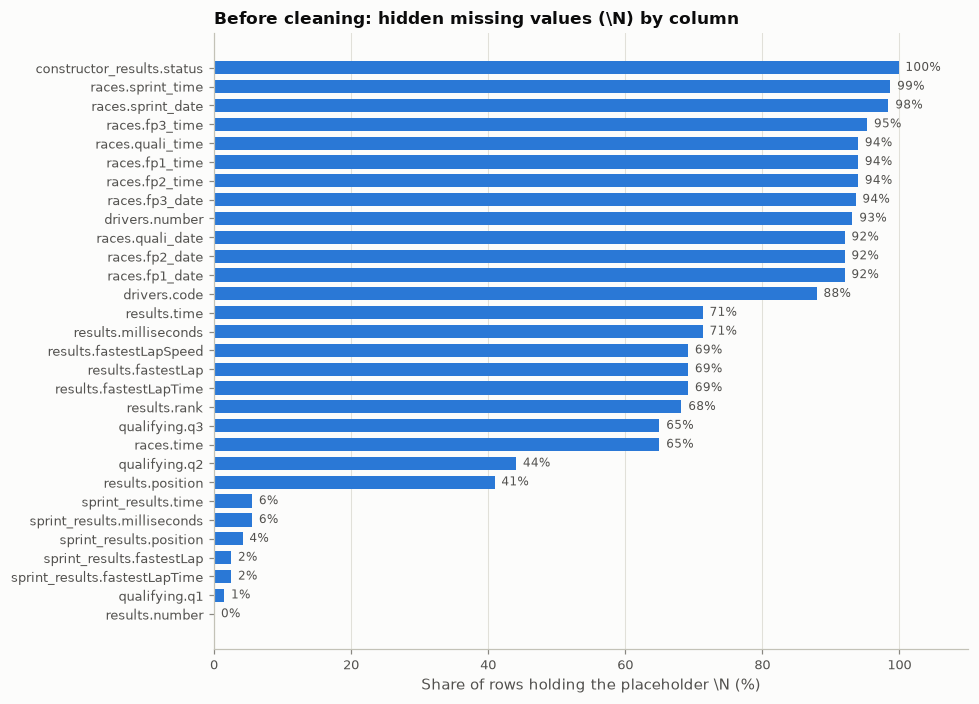

In [5]:
# What a default pd.read_csv would do: the \N text forces numeric columns to be read as text.
naive = {t: pd.read_csv(os.path.join(DATA_DIR, t + ".csv")) for t in TABLES}
naive_missing = sum(int(d.isna().sum().sum()) for d in naive.values())
hidden_missing = int(sentinel_audit.loc[sentinel_audit["sentinel"].isin(["'\\\\N'", "''"]), "count"].sum())
text_cols_naive = sum(int((~d.dtypes.map(pd.api.types.is_numeric_dtype)).sum()) for d in naive.values())
total_cols = sum(d.shape[1] for d in naive.values())
print(f"Default read: pandas sees {naive_missing:,} missing cells; the files really contain {hidden_missing:,} placeholder cells.")
print(f"Default read: {text_cols_naive} of {total_cols} columns are typed as text.")

fig, ax = plt.subplots(figsize=(9, 6.5))
top = sentinel_audit[sentinel_audit["sentinel"] == "'\\\\N'"].copy()
top["label"] = top["table"] + "." + top["column"]
top = top.sort_values("share")
ax.barh(top["label"], top["share"] * 100, color=C["blue"], height=0.7)
for y, v in enumerate(top["share"] * 100):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=8, color=C["ink2"])
ax.set_xlim(0, 110)
ax.set_xlabel(r"Share of rows holding the placeholder \N (%)")
ax.set_title(r"Before cleaning: hidden missing values (\N) by column")
ax.grid(axis="y", visible=False)
savefig("eda_before_sentinels")

**What this shows.**

- `\N` is the main placeholder, and `qualifying.q2` / `q3` also contain **empty strings** — a second placeholder that a `\N`-only rule would miss.
- A default read reports almost no missing data, while tens of thousands of cells are really empty. Any statistic computed on such a read would be wrong.
- The missingness is **structural, not random**: `results.position`, `time` and `milliseconds` are empty for drivers who did not finish; `fastestLap*` only exists from 2004; `q2`/`q3` are empty for drivers knocked out early; the practice and sprint timetable columns in `races` only exist for recent seasons. So we convert these to proper missing values and **do not fill them in** at this stage.
- One nationality value has a trailing space (`'Argentinian '`), which would create a false extra category.

### 2.2 Types and formats

Because of the placeholders, columns that hold numbers, dates and durations are all text. Before converting we check which **formats** actually occur, so the parser covers all of them.

In [6]:
def format_pattern(value):
    """Collapse a value to its shape: digits -> 9, letters -> a."""
    return re.sub(r"[A-Za-z]", "a", re.sub(r"\d", "9", value))

checks = {"qualifying.q1": RAW["qualifying"]["q1"], "qualifying.q3": RAW["qualifying"]["q3"],
          "lap_times.time": RAW["lap_times"]["time"], "pit_stops.duration": RAW["pit_stops"]["duration"],
          "results.time": RAW["results"]["time"], "results.fastestLapTime": RAW["results"]["fastestLapTime"],
          "races.date": RAW["races"]["date"], "races.time": RAW["races"]["time"], "drivers.dob": RAW["drivers"]["dob"]}
fmt = pd.concat({k: v.map(format_pattern).value_counts() for k, v in checks.items()}).rename("count").reset_index()
fmt.columns = ["column", "format", "count"]
display(fmt)

,column,format,count
0,qualifying.q1,9:99.999,10337
1,qualifying.q1,\a,156
2,qualifying.q1,99:99.999,1
3,qualifying.q3,\a,6819
4,qualifying.q3,9:99.999,3629
5,qualifying.q3,,46
6,lap_times.time,9:99.999,588455
7,lap_times.time,99:99.999,583
8,lap_times.time,9:99:99.999,43
9,pit_stops.duration,99.999,10854


**What this shows.** Durations come in several shapes: `M:SS.mmm` (lap and qualifying times), `SS.mmm` (pit stops under a minute), `M:SS.mmm` pit stops (long stops, usually under a red flag), `H:MM:SS.mmm` (winner's race time) and `+S.mmm` gaps for other finishers. One qualifying time has the shape `99:99.999` — a lap of more than ten minutes, which is not physically possible and is checked in Section 3. Dates are consistently `YYYY-MM-DD`.

### 2.3 Primary keys

A primary key must be unique and never empty. We test the declared key of every table.

In [7]:
PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"], "races": ["raceId"],
    "seasons": ["year"], "status": ["statusId"], "results": ["resultId"], "sprint_results": ["resultId"],
    "qualifying": ["qualifyId"], "driver_standings": ["driverStandingsId"],
    "constructor_standings": ["constructorStandingsId"], "constructor_results": ["constructorResultsId"],
    "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"],
}
pk_audit = pd.DataFrame([{
    "table": t, "primary key": " + ".join(k), "rows": len(RAW[t]),
    "duplicate keys": int(RAW[t].duplicated(k).sum()),
    "null keys": int(RAW[t][k].isin(["\\N", ""]).any(axis=1).sum()),
} for t, k in PRIMARY_KEYS.items()])
pk_audit["status"] = np.where((pk_audit["duplicate keys"] == 0) & (pk_audit["null keys"] == 0), "OK", "FAIL")
display(pk_audit)

,table,primary key,rows,duplicate keys,null keys,status
0,circuits,circuitId,77,0,0,OK
1,constructors,constructorId,212,0,0,OK
2,drivers,driverId,861,0,0,OK
3,races,raceId,1125,0,0,OK
4,seasons,year,75,0,0,OK
5,status,statusId,139,0,0,OK
6,results,resultId,26759,0,0,OK
7,sprint_results,resultId,360,0,0,OK
8,qualifying,qualifyId,10494,0,0,OK
9,driver_standings,driverStandingsId,34863,0,0,OK


### 2.4 Foreign keys

Every foreign key value must exist in the table it points to. An unmatched ("orphan") value would silently drop rows in an inner join or create empty rows in a left join.

,child,parent,rows,null,orphans,status
0,races.circuitId,circuits.circuitId,1125,0,0,OK
1,races.year,seasons.year,1125,0,0,OK
2,results.raceId,races.raceId,26759,0,0,OK
3,results.driverId,drivers.driverId,26759,0,0,OK
4,results.constructorId,constructors.constructorId,26759,0,0,OK
5,results.statusId,status.statusId,26759,0,0,OK
6,sprint_results.raceId,races.raceId,360,0,0,OK
7,sprint_results.driverId,drivers.driverId,360,0,0,OK
8,sprint_results.constructorId,constructors.constructorId,360,0,0,OK
9,sprint_results.statusId,status.statusId,360,0,0,OK


Qualifying entries with no race result row: 0 of 10494


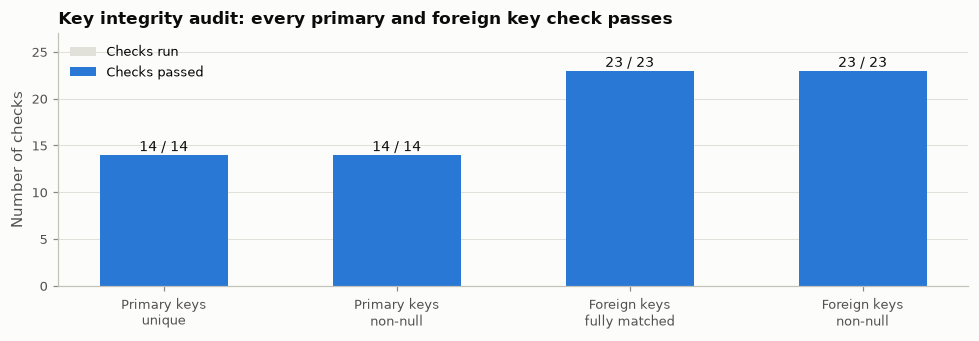

In [8]:
FOREIGN_KEYS = [
    ("races", "circuitId", "circuits", "circuitId"), ("races", "year", "seasons", "year"),
    ("results", "raceId", "races", "raceId"), ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"), ("results", "statusId", "status", "statusId"),
    ("sprint_results", "raceId", "races", "raceId"), ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"), ("sprint_results", "statusId", "status", "statusId"),
    ("qualifying", "raceId", "races", "raceId"), ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("driver_standings", "raceId", "races", "raceId"), ("driver_standings", "driverId", "drivers", "driverId"),
    ("constructor_standings", "raceId", "races", "raceId"), ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("constructor_results", "raceId", "races", "raceId"), ("constructor_results", "constructorId", "constructors", "constructorId"),
    ("lap_times", "raceId", "races", "raceId"), ("lap_times", "driverId", "drivers", "driverId"),
    ("pit_stops", "raceId", "races", "raceId"), ("pit_stops", "driverId", "drivers", "driverId"),
]
rows = []
for child, col, parent, pcol in FOREIGN_KEYS:
    values = RAW[child][col]
    is_null = values.isin(["\\N", ""])
    orphan = ~values[~is_null].isin(set(RAW[parent][pcol]))
    rows.append({"child": f"{child}.{col}", "parent": f"{parent}.{pcol}", "rows": len(values),
                 "null": int(is_null.sum()), "orphans": int(orphan.sum())})
fk_audit = pd.DataFrame(rows)
fk_audit["status"] = np.where((fk_audit["orphans"] == 0) & (fk_audit["null"] == 0), "OK", "FAIL")
display(fk_audit)

# The same key can also be checked across fact tables: does every qualifying entry have a race result?
q_keys = set(zip(RAW["qualifying"]["raceId"], RAW["qualifying"]["driverId"]))
r_keys = set(zip(RAW["results"]["raceId"], RAW["results"]["driverId"]))
print(f"Qualifying entries with no race result row: {len(q_keys - r_keys)} of {len(q_keys)}")

fig, ax = plt.subplots(figsize=(9, 3.2))
summary = pd.Series({"Primary keys\nunique": (pk_audit["duplicate keys"] == 0).sum(),
                     "Primary keys\nnon-null": (pk_audit["null keys"] == 0).sum(),
                     "Foreign keys\nfully matched": (fk_audit["orphans"] == 0).sum(),
                     "Foreign keys\nnon-null": (fk_audit["null"] == 0).sum()})
totals = [len(pk_audit), len(pk_audit), len(fk_audit), len(fk_audit)]
ax.bar(summary.index, totals, color=C["grid"], width=0.55, label="Checks run")
ax.bar(summary.index, summary.values, color=C["blue"], width=0.55, label="Checks passed")
for i, (v, n) in enumerate(zip(summary.values, totals)):
    ax.text(i, n + 0.4, f"{v} / {n}", ha="center", fontsize=9, color=C["ink"])
ax.set_ylim(0, max(totals) + 4)
ax.set_ylabel("Number of checks")
ax.set_title("Key integrity audit: every primary and foreign key check passes")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
savefig("audit_keys")

**What this shows.** All primary keys are unique and non-null, and all foreign keys reconcile with zero orphans. This means joins between the tables will neither drop rows nor invent them, so no repair is needed here. The declared keys are sound — but the **modeling grain** `(raceId, driverId)` is *not* the primary key of `results` (that is `resultId`), so it needs its own check.

### 2.5 Is `(raceId, driverId)` unique in `results`?

176 result rows belong to 85 driver-race pairs that appear more than once (91 surplus rows).
Pairs where the entries differ in grid slot: 81, in constructor: 16


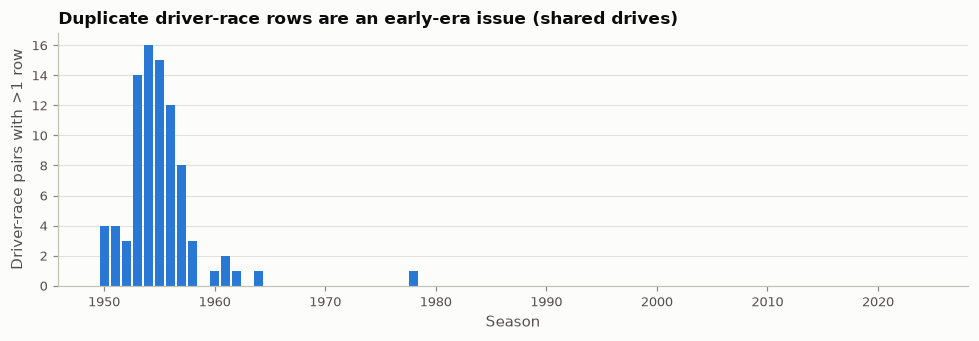

,year,raceId,driverId,resultId,constructorId,number,grid,positionText,positionOrder,laps,statusId
13188,1978,540,229,13189,54,10,0,F,26,0,81
13191,1978,540,229,13192,57,23,0,F,29,0,97
17362,1964,717,373,17363,172,1,1,7,7,102,60
24298,1964,717,373,24304,172,2,1,R,12,54,98
17740,1962,733,465,17741,172,48,0,W,22,0,54
17743,1962,733,465,17744,97,50,0,W,25,0,54
17961,1961,742,475,17962,102,26,20,D,19,56,2
17963,1961,742,475,17964,172,28,5,R,21,44,23


In [9]:
res_raw = RAW["results"].merge(RAW["races"][["raceId", "year"]], on="raceId")
res_raw["year"] = res_raw["year"].astype(int)
dup_mask = res_raw.duplicated(["raceId", "driverId"], keep=False)
dup_rows = res_raw[dup_mask]
dup_pairs = dup_rows.groupby(["raceId", "driverId"]).agg(
    year=("year", "first"), entries=("resultId", "size"), constructors=("constructorId", "nunique"),
    grids=("grid", "nunique"), statuses=("positionText", lambda s: "/".join(sorted(s))))
print(f"{len(dup_rows)} result rows belong to {len(dup_pairs)} driver-race pairs that appear more than once "
      f"({len(dup_rows) - len(dup_pairs)} surplus rows).")
print(f"Pairs where the entries differ in grid slot: {(dup_pairs['grids'] > 1).sum()}, in constructor: {(dup_pairs['constructors'] > 1).sum()}")

fig, ax = plt.subplots(figsize=(9, 3.2))
per_year = dup_pairs.groupby("year").size().reindex(range(1950, 2025), fill_value=0)
ax.bar(per_year.index, per_year.values, color=C["blue"], width=0.8)
ax.set_xlabel("Season")
ax.set_ylabel("Driver-race pairs with >1 row")
ax.set_title("Duplicate driver-race rows are an early-era issue (shared drives)")
ax.grid(axis="x", visible=False)
savefig("eda_before_duplicates")

display(dup_rows.sort_values(["raceId", "driverId"])[["year", "raceId", "driverId", "resultId", "constructorId", "number", "grid",
                                                      "positionText", "positionOrder", "laps", "statusId"]].head(8))

**What this shows.** The duplicates are concentrated in 1950–1964. In those seasons a driver could take over a team-mate's car mid-race, and each car the driver sat in is recorded as a separate result row (different car number, different grid slot, different laps). A few later cases (1962, 1978) are drivers entered by two teams who did not qualify. The rule for collapsing these rows is chosen in Section 3.4.

### 2.6 Other consistency checks found during exploration

In [10]:
r = RAW["results"]
circ = RAW["circuits"]
print("Countries spelled two ways in circuits:", sorted(c for c in circ["country"].unique() if c in ("USA", "United States")))
print("results.grid == 0 (no grid slot):", int((r["grid"] == "0").sum()), "rows")
print("positionText codes that are not a number:", dict(r.loc[~r["positionText"].str.isdigit(), "positionText"].value_counts()))

# positionOrder should be a complete 1..n ranking inside every race
rk = res_raw.assign(positionOrder=res_raw["positionOrder"].astype(int))
per_race = rk.groupby("raceId").agg(year=("year", "first"), rows=("resultId", "size"), distinct_positions=("positionOrder", "nunique"),
                                    podium_rows=("positionOrder", lambda s: int((s <= 3).sum())))
tied = per_race[per_race["rows"] != per_race["distinct_positions"]]
print(f"Races where two rows share a positionOrder: {len(tied)} (seasons {tied['year'].min()}-{tied['year'].max()})")
print("Podium rows per race, up to 1964:", dict(per_race.loc[per_race["year"] <= 1964, "podium_rows"].value_counts().sort_index()))
print("Podium rows per race, from 1965 :", dict(per_race.loc[per_race["year"] >= 1965, "podium_rows"].value_counts().sort_index()))
print("Nationality spellings for Argentina:", sorted(n for n in RAW["drivers"]["nationality"].unique() if n.startswith("Argentin")))

Countries spelled two ways in circuits: ['USA', 'United States']
results.grid == 0 (no grid slot): 1638 rows
positionText codes that are not a number: {'R': np.int64(8897), 'F': np.int64(1368), 'W': np.int64(336), 'N': np.int64(190), 'D': np.int64(151), 'E': np.int64(9)}
Races where two rows share a positionOrder: 46 (seasons 1950-1964)
Podium rows per race, up to 1964: {3: np.int64(113), 4: np.int64(16), 5: np.int64(1), 7: np.int64(1)}
Podium rows per race, from 1965 : {3: np.int64(994)}
Nationality spellings for Argentina: ['Argentine', 'Argentine-Italian', 'Argentinian ']


**Findings carried into cleaning.**

| # | Finding | Evidence | Cleaning rule (Section 3) |
|---|---|---|---|
| 1 | Two placeholders for missing: `\N` and empty string | 2.1 | Convert both to real missing values |
| 2 | Missing values are structural (DNF, era, knockout qualifying) | 2.1 | Keep as missing; do not fill |
| 3 | Numbers, dates and durations stored as text | 2.2 | Semantic typing; durations to seconds |
| 4 | One impossible qualifying time (over ten minutes) | 2.2 | Plausibility rule sets it to missing |
| 5 | Trailing space in a nationality; `Argentine` / `Argentinian`; `USA` / `United States` | 2.1, 2.6 | Trim text; harmonise the two spellings |
| 6 | Driver–race pairs duplicated by shared drives | 2.5 | Collapse to one row per driver–race |
| 7 | `grid = 0` means "no grid slot" (pit-lane start or did not start), not "ahead of pole" | 2.6 | Keep in cleaning; handled as a feature in Section 6 |
| 8 | From 1965 on, every race has exactly 3 rows with `positionOrder <= 3`. Up to 1964, two drivers who shared a car share one `positionOrder`, so some races have 4–5 podium rows | 2.6 | `positionOrder` is a safe target source; the early ties are genuine shared podiums and are kept |

## 3. Cleaning

All cleaning is applied to copies; `RAW` is left untouched.

### 3.1 Sentinels and whitespace

In [11]:
CLEAN = {}
for t, d in RAW.items():
    c = d.copy()
    for col in c.columns:
        c[col] = c[col].str.strip()
    c = c.replace({"\\N": np.nan, "": np.nan})
    CLEAN[t] = c

### 3.2 Semantic typing

- **Durations → seconds (float).** A single parser handles `SS.mmm`, `M:SS.mmm` and `H:MM:SS.mmm`. Gap strings such as `+5.478` in `results.time` are not durations of the race; the numeric race time is already in `results.milliseconds`, so we derive `race_time_s` from that and keep `time` as text.
- **Dates → datetime.** Race date and time are also combined into one timestamp.
- **Numbers.** Every remaining column is converted to a number **only if every non-missing value converts**, so the conversion can never create new missing values. Whole-number columns use the nullable integer type, which keeps IDs as integers even when some rows are missing.

In [12]:
def to_seconds(value):
    """'1:26.572' -> 86.572, '25.021' -> 25.021, '1:34:50.616' -> 5690.616."""
    if pd.isna(value):
        return np.nan
    total = 0.0
    for part in str(value).split(":"):
        total = total * 60 + float(part)
    return total

DURATION_COLS = {"qualifying": ["q1", "q2", "q3"], "lap_times": ["time"], "pit_stops": ["duration"],
                 "results": ["fastestLapTime"], "sprint_results": ["fastestLapTime"]}
DATE_COLS = {"races": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"], "drivers": ["dob"]}
KEEP_TEXT = {"results": ["time", "positionText"], "sprint_results": ["time", "positionText"],
             "driver_standings": ["positionText"], "constructor_standings": ["positionText"],
             "races": ["time", "fp1_time", "fp2_time", "fp3_time", "quali_time", "sprint_time"], "pit_stops": ["time"],
             "drivers": ["code"]}

typing_log = []
for t, c in CLEAN.items():
    for col in DURATION_COLS.get(t, []):
        before = c[col].notna().sum()
        c[col + "_s"] = c[col].map(to_seconds)
        assert c[col + "_s"].notna().sum() == before, f"duration parse lost values in {t}.{col}"
        typing_log.append((t, col, "text", "seconds (float)"))
    for col in DATE_COLS.get(t, []):
        before = c[col].notna().sum()
        c[col] = pd.to_datetime(c[col], format="%Y-%m-%d", errors="coerce")
        assert c[col].notna().sum() == before, f"date parse lost values in {t}.{col}"
        typing_log.append((t, col, "text", "datetime"))
    skip = set(DURATION_COLS.get(t, [])) | set(DATE_COLS.get(t, [])) | set(KEEP_TEXT.get(t, []))
    for col in [x for x in RAW[t].columns if x not in skip]:
        converted = pd.to_numeric(c[col], errors="coerce")
        if converted.notna().sum() == c[col].notna().sum():      # lossless -> accept
            is_whole = (converted.dropna() % 1 == 0).all()
            c[col] = converted.astype("Int64") if is_whole else converted.astype(float)
            typing_log.append((t, col, "text", "integer" if is_whole else "float"))

# Derived, clearly named numeric versions of mixed-format columns
CLEAN["results"]["race_time_s"] = CLEAN["results"]["milliseconds"].astype(float) / 1000
CLEAN["lap_times"]["lap_time_s"] = CLEAN["lap_times"]["milliseconds"].astype(float) / 1000
CLEAN["races"]["race_datetime"] = pd.to_datetime(
    CLEAN["races"]["date"].dt.strftime("%Y-%m-%d") + " " + CLEAN["races"]["time"].fillna("00:00:00"))

typing_log = pd.DataFrame(typing_log, columns=["table", "column", "from", "to"])
display(typing_log.groupby(["table", "to"]).size().unstack(fill_value=0))

# Cross-check the parser against the independent milliseconds column supplied in lap_times
diff = (CLEAN["lap_times"]["time_s"] - CLEAN["lap_times"]["lap_time_s"]).abs().max()
print(f"Largest disagreement between parsed lap time and the milliseconds column: {diff:.6f} s")

to,datetime,float,integer,seconds (float)
table,,,,
circuits,0,2,2,0
constructor_results,0,1,3,0
constructor_standings,0,1,5,0
constructors,0,0,1,0
driver_standings,0,1,5,0
drivers,1,0,2,0
lap_times,0,0,5,1
pit_stops,0,0,5,1
qualifying,0,0,6,3


Largest disagreement between parsed lap time and the milliseconds column: 0.000000 s


The duration parser agrees with the independent `milliseconds` column on every one of the ~589k laps, which validates it before we rely on it for qualifying times (which have no such second column).

### 3.3 Value-level fixes

Three issues found in the audit are fixed with explicit, testable rules:

1. **Unrepresentative qualifying times.** A qualifying time slower than 1.5× the fastest lap of the same session is not a real flying lap (a typo, or a slow lap recorded after the driver's fast laps were deleted). Such values are set to missing rather than dropping the row, so the driver's qualifying *position* is kept.
2. **Category spelling.** `United States` → `USA` and `Argentinian` → `Argentine`, so one country is one category.
3. **Pit-stop durations inflated by red flags.** Stops longer than five minutes are cars waiting in the pit lane during a stoppage, not service time. We keep the row and add a flag, because pit stops are not used as features (they happen after the cutoff) and deleting them would change the stop count.

In [13]:
q = CLEAN["qualifying"]
n_bad = 0
for col in ["q1_s", "q2_s", "q3_s"]:
    session_best = q.groupby("raceId")[col].transform("min")
    bad = q[col] > 1.5 * session_best
    n_bad += int(bad.sum())
    if bad.any():
        display(q.loc[bad, ["raceId", "driverId", "position", col[:2], col]].assign(session_best_s=session_best[bad]))
    q.loc[bad, col] = np.nan
q["best_s"] = q[["q1_s", "q2_s", "q3_s"]].min(axis=1)
print("Qualifying times set to missing by the plausibility rule:", n_bad)

CLEAN["circuits"]["country"] = CLEAN["circuits"]["country"].replace({"United States": "USA"})
CLEAN["drivers"]["nationality"] = CLEAN["drivers"]["nationality"].replace({"Argentinian": "Argentine"})
CLEAN["pit_stops"]["red_flag_wait"] = CLEAN["pit_stops"]["duration_s"] > 300
print("Pit stops flagged as red-flag waits (> 5 min):", int(CLEAN["pit_stops"]["red_flag_wait"].sum()))
print("Driver nationalities after harmonising:", CLEAN["drivers"]["nationality"].nunique(), "(was", RAW["drivers"]["nationality"].nunique(), ")")

,raceId,driverId,position,q1,q1_s,session_best_s
2567,255,87,24,16:42.640,1002.64,98.023


,raceId,driverId,position,q2,q2_s,session_best_s
9749,1107,815,15,2:06.688,126.688,64.951


Qualifying times set to missing by the plausibility rule: 2
Pit stops flagged as red-flag waits (> 5 min): 478
Driver nationalities after harmonising: 42 (was 43 )


### 3.4 One row per driver per race

Each row of the modeling table is one prediction, so each driver must appear once per race. We compare three candidate rules on the duplicated pairs before choosing.

| Rule | Idea | Weakness |
|---|---|---|
| A. Keep the **best classified result** (lowest `positionOrder`) | The target asks "did this driver finish on the podium?" A driver who was credited with a podium in any car did. | Chooses the row using the outcome |
| B. Keep the **first recorded row** (lowest `resultId`) | Simple, does not look at the outcome | Recording order is arbitrary; can discard a real podium |
| C. Keep the row with the **most laps** | The car the driver spent most time in | Also uses post-race information; can discard a podium |

,duplicated pairs,pairs with a credited podium,podiums kept,podiums lost
A: best result,85,22,22,0
B: first row,85,22,6,16
C: most laps,85,22,22,0


Pairs where rules A and C keep a different row: 0


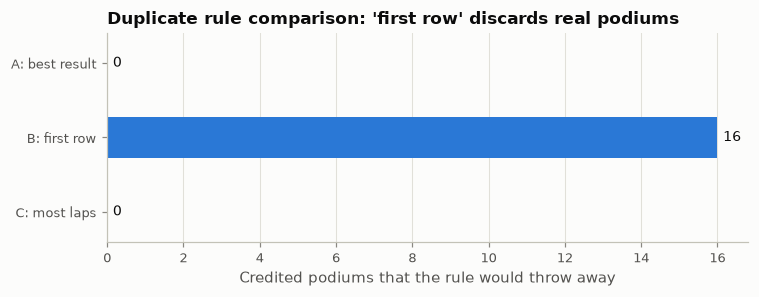

In [14]:
res = CLEAN["results"]
dups = res[res.duplicated(["raceId", "driverId"], keep=False)].copy()
grp = dups.groupby(["raceId", "driverId"])
truth = grp["positionOrder"].min() <= 3                  # driver was credited with a podium in at least one car

rule_a = dups.sort_values(["positionOrder", "resultId"]).drop_duplicates(["raceId", "driverId"]).set_index(["raceId", "driverId"])
rule_b = dups.sort_values("resultId").drop_duplicates(["raceId", "driverId"]).set_index(["raceId", "driverId"])
rule_c = dups.sort_values(["laps", "resultId"], ascending=[False, True]).drop_duplicates(["raceId", "driverId"]).set_index(["raceId", "driverId"])
rule_cmp = pd.DataFrame({
    "duplicated pairs": len(truth),
    "pairs with a credited podium": int(truth.sum()),
    "podiums kept": [int(((x["positionOrder"] <= 3) & truth.reindex(x.index)).sum()) for x in (rule_a, rule_b, rule_c)],
}, index=["A: best result", "B: first row", "C: most laps"])
rule_cmp["podiums lost"] = rule_cmp["pairs with a credited podium"] - rule_cmp["podiums kept"]
display(rule_cmp)
print("Pairs where rules A and C keep a different row:", int((rule_a["resultId"] != rule_c["resultId"].reindex(rule_a.index)).sum()))

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(rule_cmp.index[::-1], rule_cmp["podiums lost"][::-1], color=C["blue"], height=0.55)
for y, v in enumerate(rule_cmp["podiums lost"][::-1]):
    ax.text(v + 0.15, y, str(int(v)), va="center", fontsize=9, color=C["ink"])
ax.set_xlabel("Credited podiums that the rule would throw away")
ax.set_title("Duplicate rule comparison: 'first row' discards real podiums")
ax.grid(axis="y", visible=False)
savefig("cleaning_duplicate_rules")

**Decision: rule A — keep the row with the lowest `positionOrder` (ties broken by lowest `resultId`).**

- Rule B is rejected on evidence: it would label a driver "no podium" in 16 races where the driver was officially credited with one.
- Rules A and C keep every podium and, on this data, select exactly the same rows. We state the rule as A because it is defined directly by the target column, so it is guaranteed to preserve the label even on future data, whereas C preserves it only by coincidence.
- It is deterministic: the tie-break on `resultId` means a re-run always keeps the same row.
- We also keep two extra columns, `n_entries` and `shared_drive`, so the collapsed rows stay identifiable.

**Known cost.** Rule A uses the outcome to decide which row survives, so the `grid` value of a collapsed row may belong to the car the driver took over rather than the one they started in. This matters only for those few dozen rows, all in 1950–1978. The modeling table starts in 2003 (Section 6), so no modeling row is affected; the rule influences only long-history statistics in the data-engineering questions.

In [15]:
entries = res.groupby(["raceId", "driverId"])["resultId"].transform("size")
res = res.assign(n_entries=entries.astype(int), shared_drive=entries > 1)
results_clean = (res.sort_values(["raceId", "driverId", "positionOrder", "resultId"])
                    .drop_duplicates(["raceId", "driverId"], keep="first")
                    .sort_values("resultId").reset_index(drop=True))
CLEAN["results_dedup"] = results_clean

assert not results_clean.duplicated(["raceId", "driverId"]).any()
print(f"results: {len(res):,} rows -> {len(results_clean):,} rows  ({len(res) - len(results_clean)} surplus rows removed)")
print("Rows marked as shared_drive:", int(results_clean["shared_drive"].sum()))

results: 26,759 rows -> 26,668 rows  (91 surplus rows removed)
Rows marked as shared_drive: 85


## 4. EDA after cleaning

This section repeats the before-cleaning views on the cleaned copies, to show what each cleaning step changed, and then explores the cleaned data.

### 4.1 Impact of cleaning

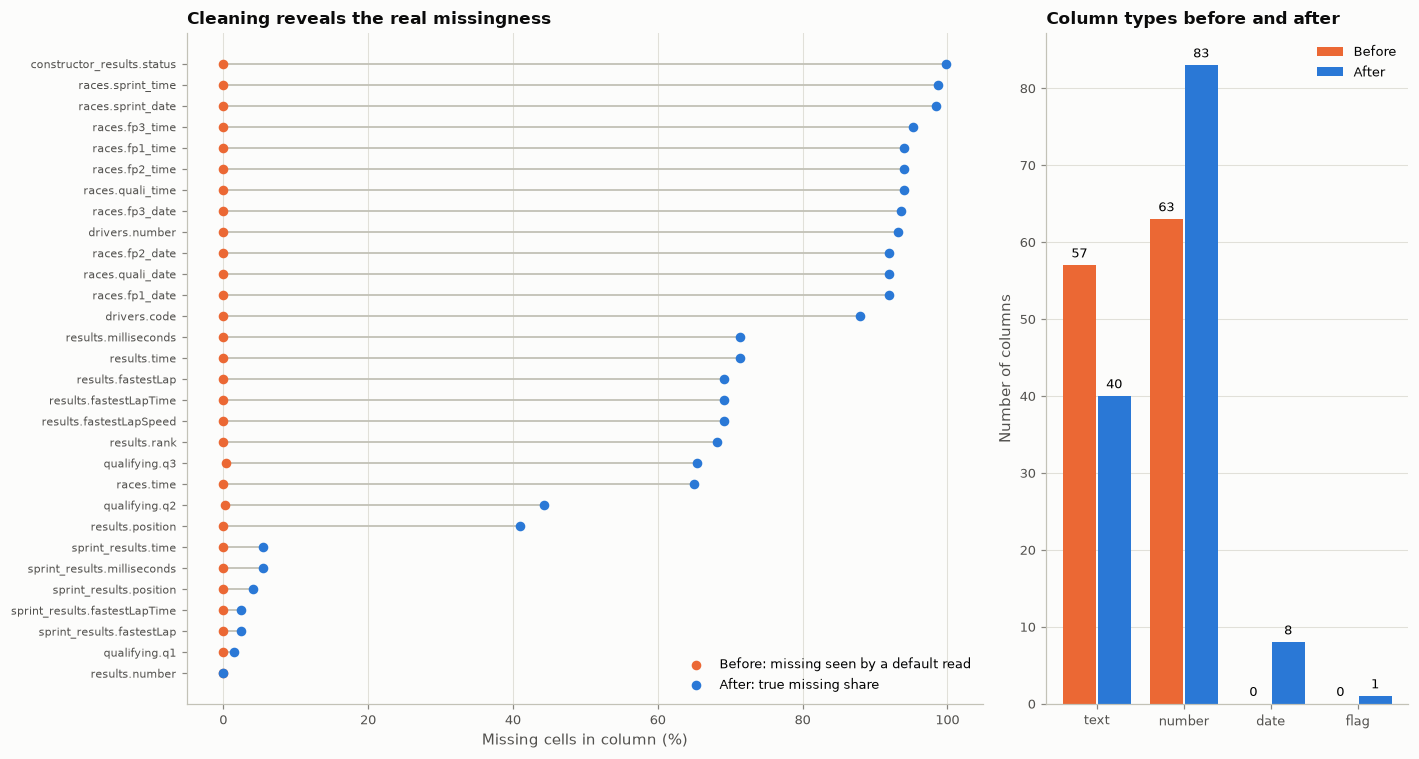

,before,after
missing cells visible to pandas,68.0,160144.0
columns typed as text,57.0,40.0
"duplicate (raceId, driverId) rows in results",91.0,0.0
nationality categories,43.0,42.0
circuit countries,35.0,34.0
max qualifying Q1 time (s),NaN,153.9


In [16]:
def type_family(series):
    if pd.api.types.is_datetime64_any_dtype(series): return "date"
    if pd.api.types.is_bool_dtype(series): return "flag"
    if pd.api.types.is_numeric_dtype(series): return "number"
    return "text"

before_types = pd.Series([type_family(naive[t][c]) for t in TABLES for c in naive[t].columns]).value_counts()
after_types = pd.Series([type_family(CLEAN[t][c]) for t in TABLES for c in CLEAN[t].columns]).value_counts()
type_cmp = pd.DataFrame({"before (default read)": before_types, "after cleaning": after_types}).fillna(0).astype(int)

miss_before = {f"{t}.{c}": naive[t][c].isna().mean() for t in TABLES for c in naive[t].columns}
miss_after = {f"{t}.{c}": CLEAN[t][c].isna().mean() for t in TABLES for c in RAW[t].columns}
miss = pd.DataFrame({"before": miss_before, "after": miss_after}).fillna(0) * 100
miss = miss[miss["after"] > 0].sort_values("after")

fig, axes = plt.subplots(1, 2, figsize=(13, 7), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
y = np.arange(len(miss))
ax.hlines(y, miss["before"], miss["after"], color=C["axis"], linewidth=1.2, zorder=1)
ax.scatter(miss["before"], y, color=C["orange"], s=28, label="Before: missing seen by a default read", zorder=2)
ax.scatter(miss["after"], y, color=C["blue"], s=28, label="After: true missing share", zorder=2)
ax.set_yticks(y)
ax.set_yticklabels(miss.index, fontsize=7.5)
ax.set_xlabel("Missing cells in column (%)")
ax.set_title("Cleaning reveals the real missingness")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)

ax = axes[1]
order = ["text", "number", "date", "flag"]
type_cmp = type_cmp.reindex(order).fillna(0).astype(int)
x = np.arange(len(order))
ax.bar(x - 0.2, type_cmp["before (default read)"], width=0.38, color=C["orange"], label="Before")
ax.bar(x + 0.2, type_cmp["after cleaning"], width=0.38, color=C["blue"], label="After")
for i, k in enumerate(order):
    ax.text(i - 0.2, type_cmp.loc[k, "before (default read)"] + 1, str(type_cmp.loc[k, "before (default read)"]), ha="center", fontsize=8.5)
    ax.text(i + 0.2, type_cmp.loc[k, "after cleaning"] + 1, str(type_cmp.loc[k, "after cleaning"]), ha="center", fontsize=8.5)
ax.set_xticks(x)
ax.set_xticklabels(order)
ax.set_ylabel("Number of columns")
ax.set_title("Column types before and after")
ax.legend()
ax.grid(axis="x", visible=False)
savefig("eda_after_cleaning_impact")

impact = pd.DataFrame({
    "before": {"missing cells visible to pandas": naive_missing, "columns typed as text": int(type_cmp.loc["text", "before (default read)"]),
               "duplicate (raceId, driverId) rows in results": int(RAW["results"].duplicated(["raceId", "driverId"]).sum()),
               "nationality categories": RAW["drivers"]["nationality"].nunique(), "circuit countries": RAW["circuits"]["country"].nunique(),
               "max qualifying Q1 time (s)": np.nan},
    "after": {"missing cells visible to pandas": sum(int(CLEAN[t][RAW[t].columns].isna().sum().sum()) for t in TABLES),
              "columns typed as text": int(type_cmp.loc["text", "after cleaning"]),
              "duplicate (raceId, driverId) rows in results": int(results_clean.duplicated(["raceId", "driverId"]).sum()),
              "nationality categories": CLEAN["drivers"]["nationality"].nunique(), "circuit countries": CLEAN["circuits"]["country"].nunique(),
              "max qualifying Q1 time (s)": round(float(CLEAN["qualifying"]["q1_s"].max()), 1)},
})
display(impact)

**Impact of cleaning.** The true missingness is now visible to pandas (orange dots at zero move to their real position in blue), the text-typed columns that held numbers, dates and durations are now usable types, the grain is unique, and two false categories are gone. The maximum Q1 time could not even be computed before cleaning, because the column was text.

### 4.2 Distributions that only exist after typing

Durations were text before cleaning, so they could not be plotted at all. After conversion we can inspect them and confirm the values are plausible.

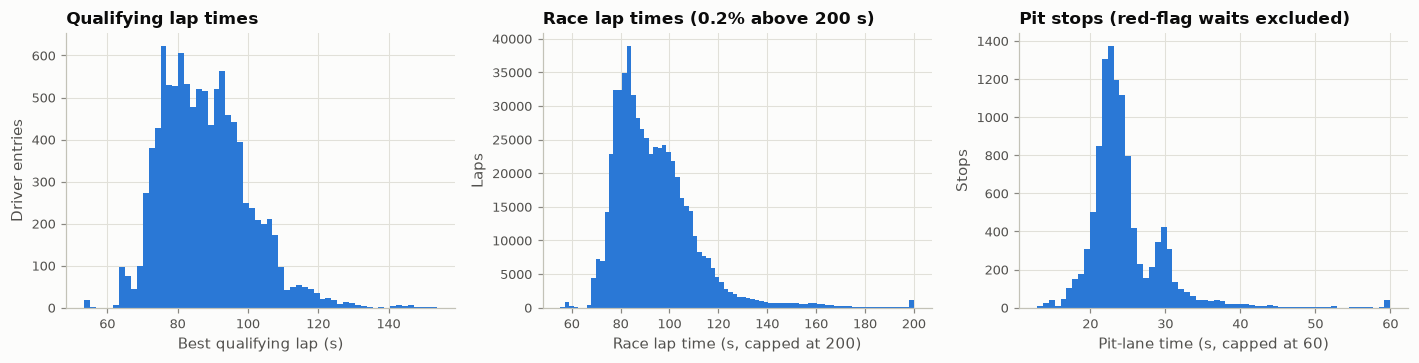

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
ax = axes[0]
ax.hist(CLEAN["qualifying"]["best_s"].dropna(), bins=60, color=C["blue"])
ax.set_xlabel("Best qualifying lap (s)")
ax.set_ylabel("Driver entries")
ax.set_title("Qualifying lap times")

ax = axes[1]
laps = CLEAN["lap_times"]["lap_time_s"]
ax.hist(laps.clip(upper=200), bins=80, color=C["blue"])
ax.set_xlabel("Race lap time (s, capped at 200)")
ax.set_ylabel("Laps")
ax.set_title(f"Race lap times ({(laps > 200).mean() * 100:.1f}% above 200 s)")

ax = axes[2]
pits = CLEAN["pit_stops"]
ax.hist(pits.loc[~pits["red_flag_wait"], "duration_s"].clip(upper=60), bins=60, color=C["blue"])
ax.set_xlabel("Pit-lane time (s, capped at 60)")
ax.set_ylabel("Stops")
ax.set_title("Pit stops (red-flag waits excluded)")
savefig("eda_after_durations")

Qualifying laps fall between roughly 55 s and 130 s, depending on the circuit length. Race laps have a long right tail from safety-car and in/out laps. Pit-lane times centre around 20–25 s. None of these contain impossible values after cleaning.

### 4.3 Coverage over time: which tables exist for which seasons?

This decides which seasons can support qualifying-based features.

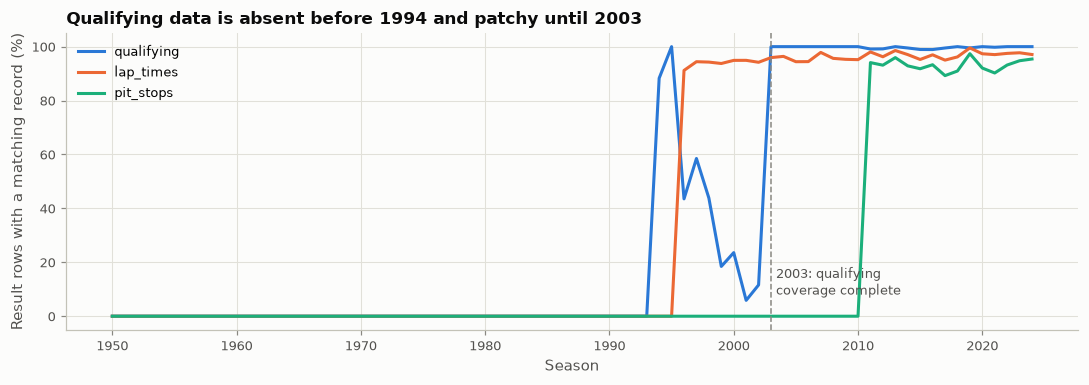

year,1993,1994,1996,1999,2002,2003,2010,2024
qualifying,0.0,88.3,43.5,18.5,11.6,100.0,100.0,100.0


First season from which qualifying coverage stays at or above 95%: 2003


In [18]:
races = CLEAN["races"]
base = results_clean.merge(races[["raceId", "year", "round", "circuitId", "date"]], on="raceId", how="left", validate="many_to_one")
assert len(base) == len(results_clean)

cov = base[["raceId", "driverId", "year"]].copy()
for name, keys in [("qualifying", CLEAN["qualifying"]), ("lap_times", CLEAN["lap_times"]), ("pit_stops", CLEAN["pit_stops"])]:
    present = keys[["raceId", "driverId"]].drop_duplicates().assign(**{name: 1})
    cov = cov.merge(present, on=["raceId", "driverId"], how="left")
    cov[name] = cov[name].fillna(0)
cov_year = cov.groupby("year")[["qualifying", "lap_times", "pit_stops"]].mean() * 100

fig, ax = plt.subplots(figsize=(10, 3.6))
for col, color in zip(["qualifying", "lap_times", "pit_stops"], SERIES):
    ax.plot(cov_year.index, cov_year[col], color=color, label=col)
ax.axvline(2003, color=C["muted"], linestyle="--", linewidth=1)
ax.text(2003.4, 8, "2003: qualifying\ncoverage complete", fontsize=8.5, color=C["ink2"])
ax.set_xlabel("Season")
ax.set_ylabel("Result rows with a matching record (%)")
ax.set_title("Qualifying data is absent before 1994 and patchy until 2003")
ax.legend(loc="upper left")
savefig("eda_after_coverage")

display(cov_year.loc[[1993, 1994, 1996, 1999, 2002, 2003, 2010, 2024], ["qualifying"]].round(1).T)
first_full = int(cov_year.index[(cov_year["qualifying"] >= 95)[::-1].cummin()[::-1]].min())
print("First season from which qualifying coverage stays at or above 95%:", first_full)

**What this shows.** The `qualifying` table has no rows before 1994 and covers only a fraction of entries from 1996 to 2002. From **2003** onward it covers essentially every entry. Because the prediction cutoff is "after qualifying", qualifying information is central to the task — so the modeling table is restricted to **2003–2024**. Earlier seasons are still used as *history* when computing form features (a driver racing in 2003 has a record from before 2003).

### 4.4 Target and field size

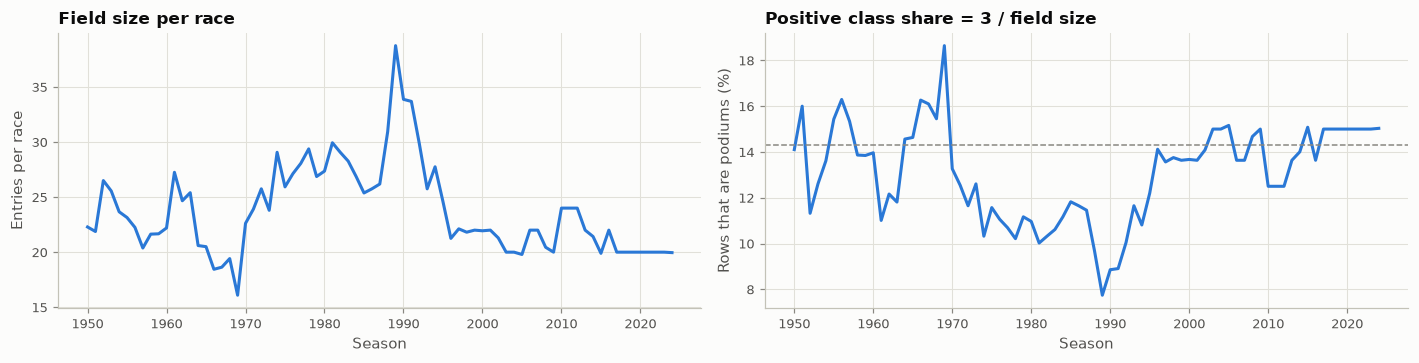

2003-2024: 8,970 driver-race rows, 428 races, podium share 14.3%


In [19]:
base["podium"] = (base["positionOrder"] <= 3).astype(int)
per_year = base.groupby("year").agg(entries=("driverId", "size"), races=("raceId", "nunique"), podium_rate=("podium", "mean"))
per_year["entries_per_race"] = per_year["entries"] / per_year["races"]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
ax = axes[0]
ax.plot(per_year.index, per_year["entries_per_race"], color=C["blue"])
ax.set_xlabel("Season")
ax.set_ylabel("Entries per race")
ax.set_title("Field size per race")
ax = axes[1]
ax.plot(per_year.index, per_year["podium_rate"] * 100, color=C["blue"])
ax.axhline(base.loc[base["year"] >= 2003, "podium"].mean() * 100, color=C["muted"], linestyle="--", linewidth=1)
ax.set_xlabel("Season")
ax.set_ylabel("Rows that are podiums (%)")
ax.set_title("Positive class share = 3 / field size")
savefig("eda_after_target")

modern = base[base["year"] >= 2003]
print(f"2003-2024: {len(modern):,} driver-race rows, {modern['raceId'].nunique()} races, podium share {modern['podium'].mean() * 100:.1f}%")

**What this shows.** There are exactly three podium places per race, so the share of positive rows is simply 3 divided by the field size. With 20–22 cars it is about **14–15%**. The classes are imbalanced, which is why accuracy is a poor metric here (always predicting "no podium" would already be about 85% accurate) and why precision–recall based metrics are preferred later.

### 4.5 Starting position and the target

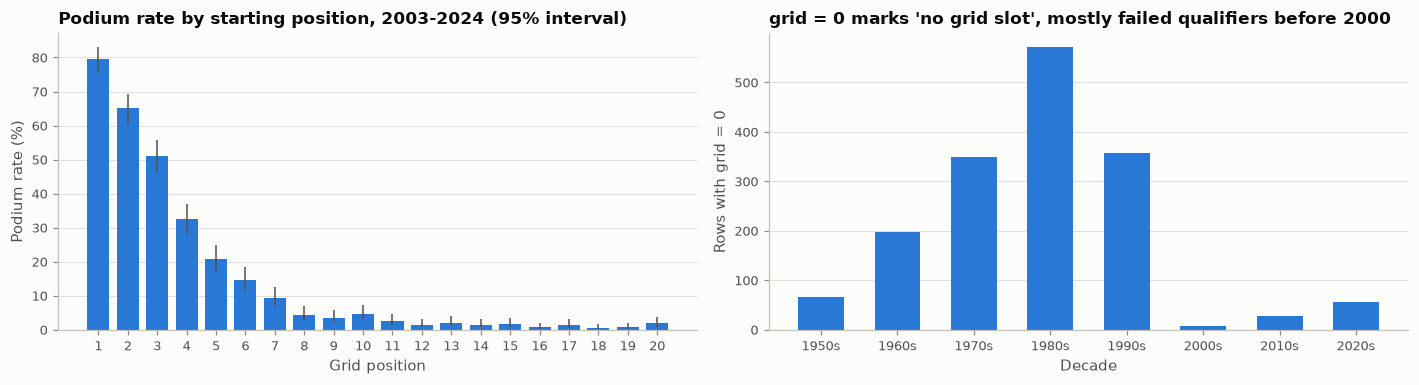

Podium rate of grid = 0 rows, 2003-2024: 0.0%  (n = 86)


In [20]:
started = modern[modern["grid"] > 0]
by_grid = started.groupby("grid")["podium"].agg(["mean", "sum", "size"])
lo, hi = wilson(by_grid["sum"], by_grid["size"])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
ax = axes[0]
g = by_grid.loc[:20]
ax.bar(g.index, g["mean"] * 100, color=C["blue"], width=0.75)
ax.errorbar(g.index, g["mean"] * 100, yerr=[(g["mean"] - lo[:20]) * 100, (hi[:20] - g["mean"]) * 100], fmt="none", ecolor=C["ink2"], linewidth=1)
ax.set_xticks(range(1, 21))
ax.set_xlabel("Grid position")
ax.set_ylabel("Podium rate (%)")
ax.set_title("Podium rate by starting position, 2003-2024 (95% interval)")
ax.grid(axis="x", visible=False)

ax = axes[1]
zero = base[base["grid"] == 0].groupby((base["year"] // 10) * 10).size()
ax.bar(zero.index.astype(str) + "s", zero.values, color=C["blue"], width=0.6)
ax.set_xlabel("Decade")
ax.set_ylabel("Rows with grid = 0")
ax.set_title("grid = 0 marks 'no grid slot', mostly failed qualifiers before 2000")
ax.grid(axis="x", visible=False)
savefig("eda_after_grid")

print("Podium rate of grid = 0 rows, 2003-2024:", f"{modern.loc[modern['grid'] == 0, 'podium'].mean() * 100:.1f}%  (n = {(modern['grid'] == 0).sum()})")

**What this shows.**

- Podium probability falls steeply and smoothly with grid position: pole converts about three times in four, and from tenth place back it is a rare event. Grid position will be the strongest single predictor, and the relationship is non-linear.
- `grid = 0` does **not** mean "ahead of pole". Before 2000 it mostly marks drivers who failed to qualify; in recent seasons it marks pit-lane starts. Treating 0 as a number would tell a model these are the best starters, so Section 6 recodes it.

## 5. Data-engineering questions

Each answer states the **joins**, the **grain**, how **missing data** was handled and whether the **pre-race cutoff** matters, followed by the result and a plot. All three questions describe the past using race outcomes, so they are descriptive analyses — the cutoff applies to *features for prediction*, not to these summaries.

One shared base table is used: de-duplicated `results` joined to `races` (season, round, circuit, date). Its grain is one row per driver per race.

In [21]:
circuits, drivers, constructors, status, qualifying = (CLEAN[t] for t in ["circuits", "drivers", "constructors", "status", "qualifying"])

fact = (base
        .merge(circuits[["circuitId", "name", "country"]].rename(columns={"name": "circuit", "country": "circuit_country"}),
               on="circuitId", how="left", validate="many_to_one")
        .merge(qualifying[["raceId", "driverId", "position"]].rename(columns={"position": "quali_pos"}),
               on=["raceId", "driverId"], how="left", validate="one_to_one")
        .merge(drivers[["driverId", "forename", "surname", "nationality", "dob"]], on="driverId", how="left", validate="many_to_one")
        .merge(constructors[["constructorId", "name"]].rename(columns={"name": "constructor"}), on="constructorId", how="left", validate="many_to_one")
        .merge(status, on="statusId", how="left", validate="many_to_one"))
fact["driver"] = fact["forename"] + " " + fact["surname"]
assert len(fact) == len(base) and not fact.duplicated(["raceId", "driverId"]).any()
print(f"Base fact table: {len(fact):,} rows, one per driver per race; joins added no rows.")

Base fact table: 26,668 rows, one per driver per race; joins added no rows.


### Question 1 — Which circuits convert a front-row start into a podium most often, and does the ranking change in the hybrid era?

**Joins.** `results → races → circuits` (three tables) for the circuit of each result, plus `results → qualifying` on `(raceId, driverId)` for the qualifying position.

**Qualifying position vs. grid.** These are two different things:

- `qualifying.position` — where the driver finished the qualifying session.
- `results.grid` — where the driver actually started, after penalties, and on sprint weekends in 2021–2022 after the sprint.

A "front-row start" is defined on the **grid** (`grid` is 1 or 2), because that is the position the car really started from. The qualifying-based version is reported next to it to show how much the two differ.

**Grain.** One row per front-row starter per race; aggregated to circuit × era. Each race contributes two rows.

**Missingness.** `grid` is never missing. `qualifying.position` only has full coverage from 2003, so everything that uses it is limited to 2003–2024.

**Small samples.** A circuit with three races has six front-row starts, so its rate is mostly noise. We require a minimum number of races and show 95% Wilson intervals.

All seasons: front-row starters reach the podium in 60.1% of starts (34 circuits with >= 10 races).


,races,starts,podiums,rate,lo,hi
circuit,,,,,,
Circuit of the Americas,12,24,20,83.3,64.1,93.3
Circuit de Nevers Magny-Cours,18,36,29,80.6,65.0,90.2
Yas Marina Circuit,16,32,25,78.1,61.2,89.0
Suzuka Circuit,34,68,51,75.0,63.6,83.8
Sepang International Circuit,19,37,27,73.0,57.0,84.6
Shanghai International Circuit,17,34,24,70.6,53.8,83.2
Circuit de Barcelona-Catalunya,34,68,48,70.6,58.9,80.1
Bahrain International Circuit,21,42,28,66.7,51.6,79.0
Reims-Gueux,11,21,10,47.6,28.3,67.6


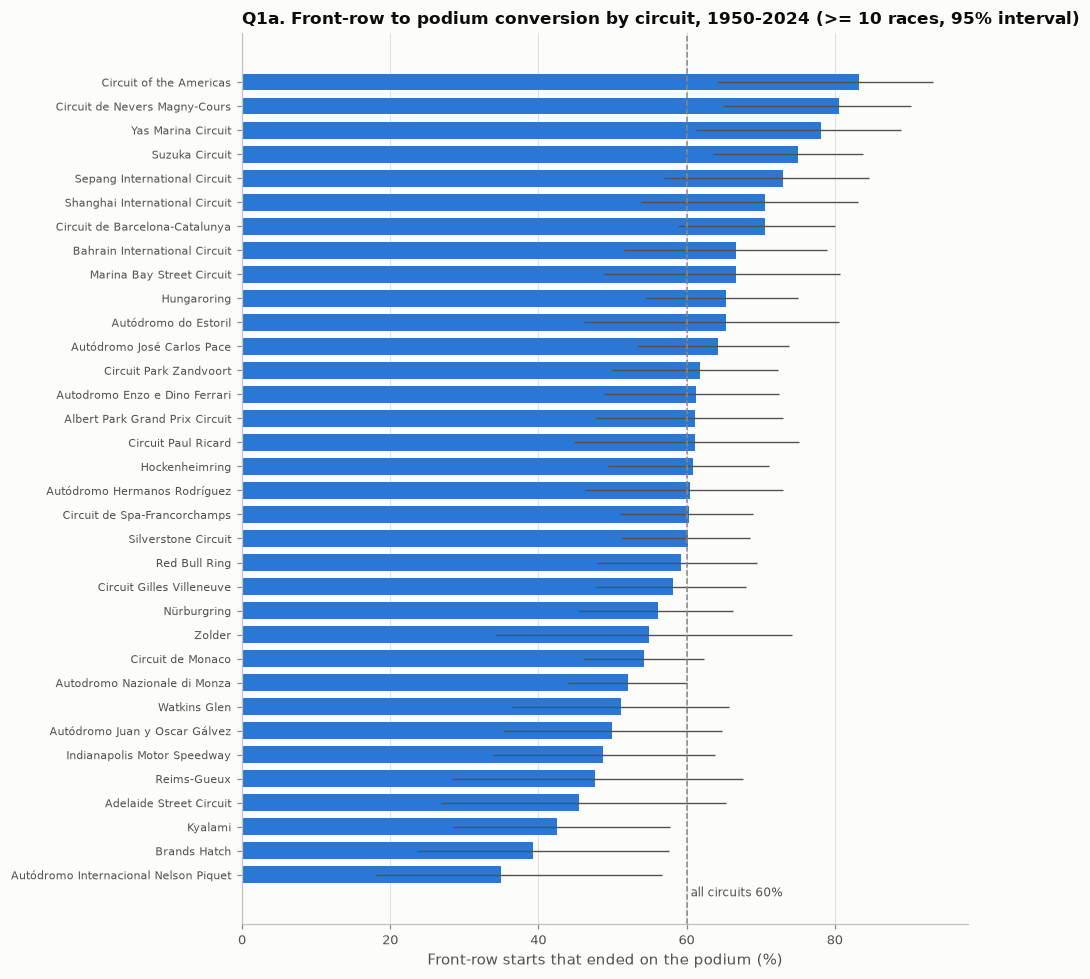

In [22]:
HYBRID_START = 2014
fact["front_row_grid"] = fact["grid"].isin([1, 2])
fact["front_row_quali"] = fact["quali_pos"].isin([1, 2])

def conversion(df, flag, by):
    out = df[df[flag]].groupby(by).agg(races=("raceId", "nunique"), starts=("podium", "size"), podiums=("podium", "sum"))
    out["rate"] = out["podiums"] / out["starts"]
    out["lo"], out["hi"] = wilson(out["podiums"], out["starts"])
    return out

# (a) Long-run ranking, all seasons, circuits with at least 10 races
MIN_RACES_ALL = 10
all_time = conversion(fact, "front_row_grid", "circuit")
ranked = all_time[all_time["races"] >= MIN_RACES_ALL].sort_values("rate", ascending=False)
overall_rate = fact.loc[fact["front_row_grid"], "podium"].mean()
print(f"All seasons: front-row starters reach the podium in {overall_rate * 100:.1f}% of starts "
      f"({len(ranked)} circuits with >= {MIN_RACES_ALL} races).")
display(pd.concat([ranked.head(8), ranked.tail(5)]).assign(rate=lambda d: (d["rate"] * 100).round(1), lo=lambda d: (d["lo"] * 100).round(1), hi=lambda d: (d["hi"] * 100).round(1)))

fig, ax = plt.subplots(figsize=(9, 9))
rk = ranked.sort_values("rate")
ax.barh(rk.index, rk["rate"] * 100, color=C["blue"], height=0.7)
ax.errorbar(rk["rate"] * 100, np.arange(len(rk)), xerr=[(rk["rate"] - rk["lo"]) * 100, (rk["hi"] - rk["rate"]) * 100],
            fmt="none", ecolor=C["ink2"], linewidth=0.9)
ax.axvline(overall_rate * 100, color=C["muted"], linestyle="--", linewidth=1)
ax.text(overall_rate * 100 + 0.5, -0.9, f"all circuits {overall_rate * 100:.0f}%", fontsize=8, color=C["ink2"])
ax.set_xlabel("Front-row starts that ended on the podium (%)")
ax.set_title(f"Q1a. Front-row to podium conversion by circuit, 1950-2024 (>= {MIN_RACES_ALL} races, 95% interval)")
ax.set_yticklabels(rk.index, fontsize=7.5)
ax.grid(axis="y", visible=False)
savefig("q1_all_time")

,races_pre,rate_pre,races_hybrid,rate_hybrid,rank_pre,rank_hybrid,change_pts
circuit,,,,,,,
Suzuka Circuit,9,72.2,9,88.9,4,1,16.7
Yas Marina Circuit,5,60.0,11,86.4,10,2,26.4
Circuit de Monaco,11,77.3,10,85.0,1,3,7.7
Circuit de Barcelona-Catalunya,11,68.2,11,81.8,6,4,13.6
Circuit de Spa-Francorchamps,9,72.2,11,81.8,4,4,9.6
Autódromo José Carlos Pace,11,59.1,10,78.9,12,6,19.9
Shanghai International Circuit,10,65.0,7,78.6,8,7,13.6
Circuit Gilles Villeneuve,10,60.0,9,77.8,10,8,17.8
Silverstone Circuit,11,72.7,12,75.0,3,9,2.3


Overall conversion: 2003-2013 68.0%  ->  2014-2024 76.0%
Spearman rank correlation between the two eras' circuit rankings: rho = 0.30 (p = 0.29, 14 circuits)


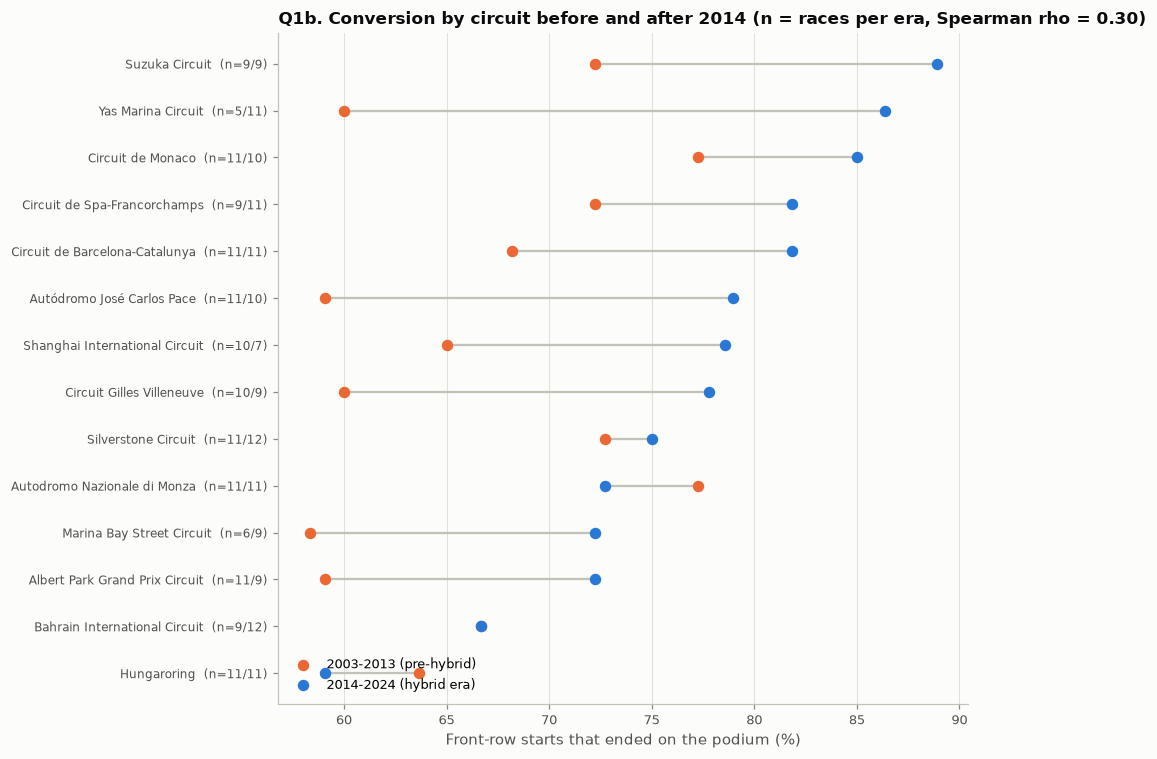

In [23]:
# (b) Era comparison on two equal 11-season windows with the same data quality
PRE, HYB = (2003, 2013), (2014, 2024)
MIN_RACES_ERA = 5
era = fact[fact["year"].between(PRE[0], HYB[1])].copy()
era["era"] = np.where(era["year"] >= HYBRID_START, "hybrid", "pre")
by_era = conversion(era, "front_row_grid", ["circuit", "era"]).unstack("era")
both = by_era[(by_era[("races", "pre")] >= MIN_RACES_ERA) & (by_era[("races", "hybrid")] >= MIN_RACES_ERA)].copy()
q1 = pd.DataFrame({
    "races_pre": both[("races", "pre")].astype(int), "rate_pre": both[("rate", "pre")],
    "races_hybrid": both[("races", "hybrid")].astype(int), "rate_hybrid": both[("rate", "hybrid")]})
q1["rank_pre"] = q1["rate_pre"].rank(ascending=False, method="min").astype(int)
q1["rank_hybrid"] = q1["rate_hybrid"].rank(ascending=False, method="min").astype(int)
q1["change_pts"] = (q1["rate_hybrid"] - q1["rate_pre"]) * 100
q1 = q1.sort_values("rate_hybrid", ascending=False)

from scipy.stats import spearmanr
rho, rho_p = spearmanr(q1["rate_pre"], q1["rate_hybrid"])
era_rates = era[era["front_row_grid"]].groupby("era")["podium"].agg(["mean", "size"])
display(q1.assign(rate_pre=(q1["rate_pre"] * 100).round(1), rate_hybrid=(q1["rate_hybrid"] * 100).round(1), change_pts=q1["change_pts"].round(1)))
print(f"Overall conversion: {PRE[0]}-{PRE[1]} {era_rates.loc['pre', 'mean'] * 100:.1f}%  ->  {HYB[0]}-{HYB[1]} {era_rates.loc['hybrid', 'mean'] * 100:.1f}%")
print(f"Spearman rank correlation between the two eras' circuit rankings: rho = {rho:.2f} (p = {rho_p:.2f}, {len(q1)} circuits)")

fig, ax = plt.subplots(figsize=(9, 7))
d = q1.sort_values("rate_hybrid")
y = np.arange(len(d))
ax.hlines(y, d["rate_pre"] * 100, d["rate_hybrid"] * 100, color=C["axis"], linewidth=1.5, zorder=1)
ax.scatter(d["rate_pre"] * 100, y, color=C["orange"], s=42, zorder=2, label=f"{PRE[0]}-{PRE[1]} (pre-hybrid)")
ax.scatter(d["rate_hybrid"] * 100, y, color=C["blue"], s=42, zorder=2, label=f"{HYB[0]}-{HYB[1]} (hybrid era)")
ax.set_yticks(y)
ax.set_yticklabels([f"{name}  (n={a}/{b})" for name, a, b in zip(d.index, d["races_pre"], d["races_hybrid"])], fontsize=8)
ax.set_xlabel("Front-row starts that ended on the podium (%)")
ax.set_title(f"Q1b. Conversion by circuit before and after 2014 (n = races per era, Spearman rho = {rho:.2f})")
ax.legend(loc="lower left")
ax.grid(axis="y", visible=False)
savefig("q1_era_change")

Entries where grid differs from qualifying position, 2003-2024: 27.0%
Front-row qualifiers who did not start on the front row: 38 of 856
Conversion by definition: grid front row 72.2%  vs  qualifying front row 70.7%


,starts,podiums,rate,lo,hi
Qualified top 2 and started on front row,818.0,594.0,72.6,69.5,75.6
Qualified top 2 but started lower (penalty / sprint),38.0,11.0,28.9,17.0,44.8
Promoted to front row (qualified 3rd or lower),36.0,23.0,63.9,47.6,77.5


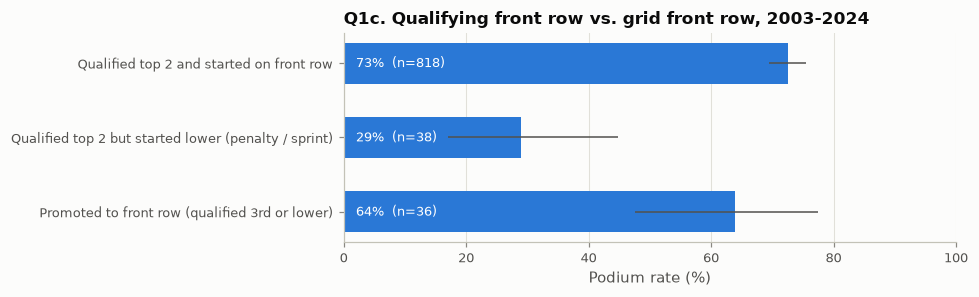

Rank agreement between grid-based and qualifying-based circuit rankings (2003-2024, >= 10 races): rho = 0.89


In [24]:
# (c) Qualifying position vs. grid, 2003-2024 (full qualifying coverage)
mod = fact[fact["year"] >= 2003]
cross = pd.crosstab(mod["front_row_quali"], mod["front_row_grid"])
groups = {
    "Qualified top 2 and started on front row": mod[mod["front_row_quali"] & mod["front_row_grid"]],
    "Qualified top 2 but started lower (penalty / sprint)": mod[mod["front_row_quali"] & ~mod["front_row_grid"]],
    "Promoted to front row (qualified 3rd or lower)": mod[~mod["front_row_quali"] & mod["front_row_grid"]],
}
q1c = pd.DataFrame({k: {"starts": len(v), "podiums": int(v["podium"].sum()), "rate": v["podium"].mean()} for k, v in groups.items()}).T
q1c["lo"], q1c["hi"] = wilson(q1c["podiums"].astype(float), q1c["starts"].astype(float))
both_known = mod[mod["quali_pos"].notna() & (mod["grid"] > 0)]
print(f"Entries where grid differs from qualifying position, 2003-2024: {(both_known['grid'] != both_known['quali_pos']).mean() * 100:.1f}%")
print(f"Front-row qualifiers who did not start on the front row: {len(groups['Qualified top 2 but started lower (penalty / sprint)'])} of {int(mod['front_row_quali'].sum())}")
print(f"Conversion by definition: grid front row {mod.loc[mod['front_row_grid'], 'podium'].mean() * 100:.1f}%  vs  qualifying front row {mod.loc[mod['front_row_quali'], 'podium'].mean() * 100:.1f}%")
display(q1c.assign(rate=(q1c["rate"].astype(float) * 100).round(1), lo=(q1c["lo"] * 100).round(1), hi=(q1c["hi"] * 100).round(1)))

fig, ax = plt.subplots(figsize=(9, 2.8))
rates = q1c["rate"].astype(float) * 100
ax.barh(q1c.index[::-1], rates[::-1], color=C["blue"], height=0.55)
ax.errorbar(rates[::-1], np.arange(3), xerr=[(rates - q1c["lo"] * 100)[::-1], (q1c["hi"] * 100 - rates)[::-1]], fmt="none", ecolor=C["ink2"], linewidth=1)
for yy, (v, n) in enumerate(zip(rates[::-1], q1c["starts"][::-1])):
    ax.text(2, yy, f"{v:.0f}%  (n={int(n)})", va="center", fontsize=8.5, color="white")
ax.set_xlim(0, 100)
ax.set_xlabel("Podium rate (%)")
ax.set_title("Q1c. Qualifying front row vs. grid front row, 2003-2024")
ax.grid(axis="y", visible=False)
savefig("q1_quali_vs_grid")

# Does the circuit ranking depend on which definition is used?
rk_grid = conversion(mod, "front_row_grid", "circuit")
rk_quali = conversion(mod, "front_row_quali", "circuit")
common = rk_grid[rk_grid["races"] >= MIN_RACES_ALL].index
rho_def, _ = spearmanr(rk_grid.loc[common, "rate"], rk_quali.loc[common, "rate"])
print(f"Rank agreement between grid-based and qualifying-based circuit rankings (2003-2024, >= {MIN_RACES_ALL} races): rho = {rho_def:.2f}")

In [25]:
top3 = ", ".join(f"{n} ({r * 100:.0f}%)" for n, r in ranked["rate"].head(3).items())
bottom3 = ", ".join(f"{n} ({r * 100:.0f}%)" for n, r in ranked["rate"].tail(3).items())
top_hyb = ", ".join(f"{n} ({r * 100:.0f}%)" for n, r in q1["rate_hybrid"].head(3).items())
top_pre = ", ".join(f"{n} ({r * 100:.0f}%)" for n, r in q1.sort_values("rate_pre", ascending=False)["rate_pre"].head(3).items())
risers = ", ".join(f"{n} ({c:+.0f} pts)" for n, c in q1["change_pts"].sort_values(ascending=False).head(3).items())
fallers = ", ".join(f"{n} ({c:+.0f} pts)" for n, c in q1.loc[q1["change_pts"] < 0, "change_pts"].sort_values().head(3).items())
md(f"""
**Answer to Question 1**

- **Which circuits convert most often?** Over all seasons a front-row starter reaches the podium in **{overall_rate * 100:.0f}%** of starts. Among circuits with at least {MIN_RACES_ALL} races, the highest conversion is at {top3}; the lowest at {bottom3}.
- **Does the ranking change in the hybrid era?** Yes, substantially. Front-row conversion rose overall from **{era_rates.loc['pre', 'mean'] * 100:.0f}%** ({PRE[0]}–{PRE[1]}) to **{era_rates.loc['hybrid', 'mean'] * 100:.0f}%** ({HYB[0]}–{HYB[1]}), and the circuit order was reshuffled: the rank correlation between the two eras is only **ρ = {rho:.2f}** (p = {rho_p:.2f}), i.e. a circuit's pre-2014 rank says little about its hybrid-era rank. Pre-hybrid leaders: {top_pre}. Hybrid-era leaders: {top_hyb}. Largest gains: {risers}. Only {int((q1['change_pts'] < 0).sum())} of {len(q1)} circuits went down: {fallers}.
- **Qualifying vs. grid.** In 2003–2024 the grid differs from the qualifying position for {(both_known['grid'] != both_known['quali_pos']).mean() * 100:.0f}% of entries. Drivers who qualified in the top two but started lower converted only {q1c['rate'].astype(float).iloc[1] * 100:.0f}% of the time, against {q1c['rate'].astype(float).iloc[0] * 100:.0f}% for those who kept their front-row slot — so the *grid* is the position that matters, and the two must not be mixed. The circuit ranking itself is similar under both definitions (ρ = {rho_def:.2f}).
- **Caution.** Each circuit–era cell holds only 10–22 front-row starts, so individual circuit rates have wide intervals (see the error bars in Q1a). The overall rise and the lack of rank stability are robust; the exact position of a single circuit is not.
""")


**Answer to Question 1**

- **Which circuits convert most often?** Over all seasons a front-row starter reaches the podium in **60%** of starts. Among circuits with at least 10 races, the highest conversion is at Circuit of the Americas (83%), Circuit de Nevers Magny-Cours (81%), Yas Marina Circuit (78%); the lowest at Kyalami (42%), Brands Hatch (39%), Autódromo Internacional Nelson Piquet (35%).
- **Does the ranking change in the hybrid era?** Yes, substantially. Front-row conversion rose overall from **68%** (2003–2013) to **76%** (2014–2024), and the circuit order was reshuffled: the rank correlation between the two eras is only **ρ = 0.30** (p = 0.29), i.e. a circuit's pre-2014 rank says little about its hybrid-era rank. Pre-hybrid leaders: Circuit de Monaco (77%), Autodromo Nazionale di Monza (77%), Silverstone Circuit (73%). Hybrid-era leaders: Suzuka Circuit (89%), Yas Marina Circuit (86%), Circuit de Monaco (85%). Largest gains: Yas Marina Circuit (+26 pts), Autódromo José Carlos Pace (+20 pts), Circuit Gilles Villeneuve (+18 pts). Only 2 of 14 circuits went down: Autodromo Nazionale di Monza (-5 pts), Hungaroring (-5 pts).
- **Qualifying vs. grid.** In 2003–2024 the grid differs from the qualifying position for 27% of entries. Drivers who qualified in the top two but started lower converted only 29% of the time, against 73% for those who kept their front-row slot — so the *grid* is the position that matters, and the two must not be mixed. The circuit ranking itself is similar under both definitions (ρ = 0.89).
- **Caution.** Each circuit–era cell holds only 10–22 front-row starts, so individual circuit rates have wide intervals (see the error bars in Q1a). The overall rise and the lack of rank stability are robust; the exact position of a single circuit is not.


**Why the ranking moves.** The hybrid era had long spells of one-team dominance (Mercedes 2014–2020, Red Bull 2022–2023) and much better reliability, so the two fastest cars more often simply finished where they started. With so few front-row starts per circuit, a circuit's position in the table mainly reflects *which seasons it hosted* and how dominant the leading car was in them, not a fixed property of the track. This is why circuit identity is **not** used as a raw feature later; a smoothed, past-only circuit conversion rate is tested instead.

### Question 2 — Do drivers reach the podium more often at home, after controlling for starting position?

**Joins.** `results → drivers` gives the driver's nationality; `results → races → circuits` gives the country of the circuit (four tables). The two use different vocabularies (`British` vs. `UK`), so a nationality-to-country mapping table is needed as a fifth input.

**Grain.** One row per driver per race, restricted to rows with a real grid slot (`grid > 0`), because "starting position" is undefined otherwise.

**Missingness.** Nationality and circuit country are never missing. Nationalities with no circuit in the data (for example Finnish or Danish) are always "away". Dual nationalities count as home in either country.

**Control.** Home drivers could do better simply because they tend to be in better cars and qualify higher. We therefore compare home and away drivers **at the same grid position**, in three ways of increasing strictness.

In [26]:
NATIONALITY_TO_COUNTRY = {
    "American": ["USA"], "American-Italian": ["USA", "Italy"], "Argentine": ["Argentina"], "Argentine-Italian": ["Argentina", "Italy"],
    "Australian": ["Australia"], "Austrian": ["Austria"], "Belgian": ["Belgium"], "Brazilian": ["Brazil"], "British": ["UK"],
    "Canadian": ["Canada"], "Chinese": ["China"], "Dutch": ["Netherlands"], "East German": ["Germany"], "French": ["France"],
    "German": ["Germany"], "Hungarian": ["Hungary"], "Indian": ["India"], "Italian": ["Italy"], "Japanese": ["Japan"],
    "Malaysian": ["Malaysia"], "Mexican": ["Mexico"], "Monegasque": ["Monaco"], "Portuguese": ["Portugal"], "Russian": ["Russia"],
    "South African": ["South Africa"], "Spanish": ["Spain"], "Swedish": ["Sweden"], "Swiss": ["Switzerland"],
}
circuit_countries = set(circuits["country"])
unmapped = sorted(set(drivers["nationality"]) - set(NATIONALITY_TO_COUNTRY))
assert all(c in circuit_countries for v in NATIONALITY_TO_COUNTRY.values() for c in v), "mapping points to a country with no circuit"
print("Nationalities with no home circuit in the data (always 'away'):", unmapped)

def is_home(nationality, country):
    return country in NATIONALITY_TO_COUNTRY.get(nationality, [])

fact["is_home"] = [is_home(n, c) for n, c in zip(fact["nationality"], fact["circuit_country"])]
home = fact[fact["grid"] > 0].copy()
raw = home.groupby("is_home")["podium"].agg(["mean", "sum", "size"])
print(f"Home rows: {int(raw.loc[True, 'size']):,} of {len(home):,} ({raw.loc[True, 'size'] / len(home) * 100:.1f}%)")
print(f"Raw podium rate  home {raw.loc[True, 'mean'] * 100:.1f}%  vs  away {raw.loc[False, 'mean'] * 100:.1f}%")
print(f"Mean grid position  home {home.loc[home['is_home'], 'grid'].mean():.2f}  vs  away {home.loc[~home['is_home'], 'grid'].mean():.2f}")

Nationalities with no home circuit in the data (always 'away'): ['Chilean', 'Colombian', 'Czech', 'Danish', 'Finnish', 'Indonesian', 'Irish', 'Liechtensteiner', 'New Zealander', 'Polish', 'Rhodesian', 'Thai', 'Uruguayan', 'Venezuelan']
Home rows: 2,324 of 25,033 (9.3%)
Raw podium rate  home 11.4%  vs  away 13.8%
Mean grid position  home 13.40  vs  away 11.71


In [27]:
import statsmodels.api as sm
from statsmodels.stats.contingency_tables import StratifiedTable

def mantel_haenszel(df, strata):
    """Pooled home-vs-away odds ratio across strata (each stratum is one 2x2 table)."""
    tables = []
    for _, g in df.groupby(strata):
        t = pd.crosstab(g["is_home"], g["podium"]).reindex(index=[True, False], columns=[1, 0], fill_value=0).values
        if t.sum(axis=1).min() > 0:                       # stratum needs both home and away rows
            tables.append(t)
    st = StratifiedTable(tables)
    lo, hi = st.oddsratio_pooled_confint()
    return {"odds_ratio": st.oddsratio_pooled, "lo": lo, "hi": hi, "p_value": st.test_null_odds().pvalue, "strata": len(tables)}

home["grid_c"] = home["grid"].clip(upper=20).astype(int)
home["decade"] = (home["year"] // 10) * 10
home["grid_band"] = pd.cut(home["grid"].astype(int), [0, 1, 2, 3, 6, 10, 40], labels=["1", "2", "3", "4-6", "7-10", "11+"]).astype(str)
home["podium_i"] = home["podium"].astype(int)
home["home_i"] = home["is_home"].astype(int)

# 0) no control
t0 = pd.crosstab(home["is_home"], home["podium"]).reindex(index=[True, False], columns=[1, 0]).values
or0 = sm.stats.Table2x2(t0)
results_q2 = {"No control (raw)": {"odds_ratio": or0.oddsratio, "lo": or0.oddsratio_confint()[0], "hi": or0.oddsratio_confint()[1],
                                   "p_value": or0.oddsratio_pvalue(), "strata": 1}}
# 1) same grid position
results_q2["Same grid position"] = mantel_haenszel(home, ["grid_c"])
# 2) same grid position and same decade (field size, reliability and calendars changed over time)
results_q2["Same grid position and decade"] = mantel_haenszel(home, ["grid_c", "decade"])
# 3) same driver and same grid band: each driver is compared only with himself, home vs. away
results_q2["Same driver and grid band"] = mantel_haenszel(home, ["driverId", "grid_band"])
# 4) same constructor-season and grid band: same car, same year
results_q2["Same car-season and grid band"] = mantel_haenszel(home, ["constructorId", "year", "grid_band"])
# 5) modern era only, same grid position
results_q2["Same grid position, 2003-2024 only"] = mantel_haenszel(home[home["year"] >= 2003], ["grid_c"])
q2 = pd.DataFrame(results_q2).T
display(q2.round(3))

# Logistic regression cross-check: podium ~ home + grid position (categorical) + decade
design = pd.get_dummies(home[["grid_c", "decade"]].astype(str), drop_first=True).astype(float)
design.insert(0, "home_i", home["home_i"].astype(float))
logit = sm.Logit(home["podium_i"].astype(float), sm.add_constant(design)).fit(disp=0)
ci = np.exp(logit.conf_int().loc["home_i"])
print(f"Logistic regression, home effect given grid and decade: odds ratio {np.exp(logit.params['home_i']):.2f} "
      f"(95% CI {ci[0]:.2f}-{ci[1]:.2f}, p = {logit.pvalues['home_i']:.3f})")

,odds_ratio,lo,hi,p_value,strata
No control (raw),0.809,0.708,0.924,0.002,1.0
Same grid position,0.969,0.826,1.137,0.699,20.0
Same grid position and decade,0.914,0.775,1.078,0.288,159.0
Same driver and grid band,1.020,0.843,1.235,0.840,727.0
Same car-season and grid band,1.066,0.871,1.305,0.541,1153.0
"Same grid position, 2003-2024 only",0.761,0.510,1.135,0.178,20.0


Logistic regression, home effect given grid and decade: odds ratio 0.94 (95% CI 0.80-1.11, p = 0.452)


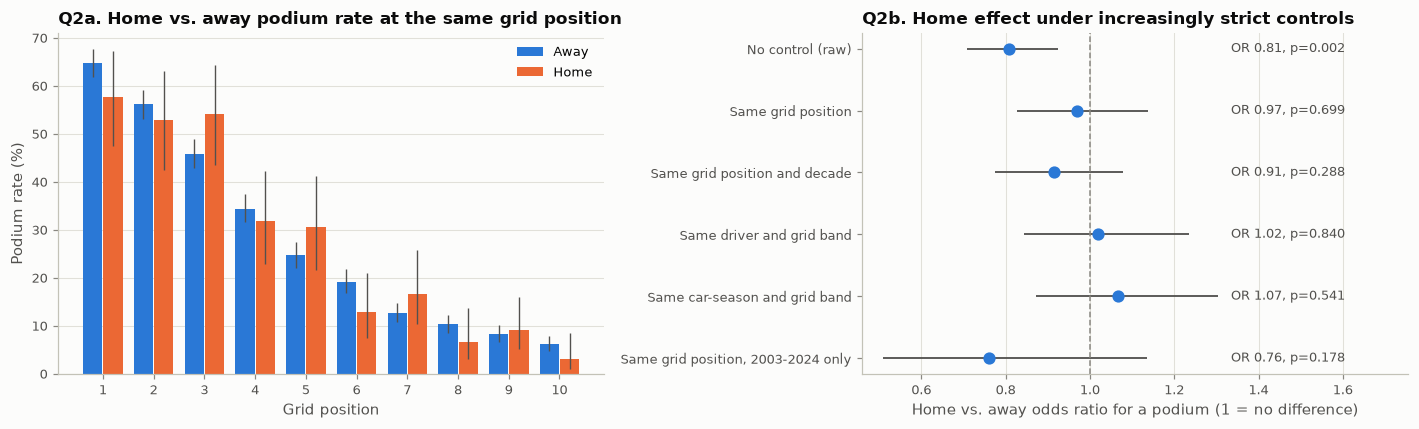

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
g = home[home["grid"] <= 10].groupby(["grid", "is_home"])["podium"].agg(["mean", "sum", "size"]).reset_index()
for flag, color, label, off in [(False, C["blue"], "Away", -0.2), (True, C["orange"], "Home", 0.2)]:
    s = g[g["is_home"] == flag]
    lo, hi = wilson(s["sum"], s["size"])
    ax.bar(s["grid"].astype(int) + off, s["mean"] * 100, width=0.38, color=color, label=label)
    ax.errorbar(s["grid"].astype(int) + off, s["mean"] * 100, yerr=[(s["mean"] - lo) * 100, (hi - s["mean"]) * 100], fmt="none", ecolor=C["ink2"], linewidth=0.9)
ax.set_xticks(range(1, 11))
ax.set_xlabel("Grid position")
ax.set_ylabel("Podium rate (%)")
ax.set_title("Q2a. Home vs. away podium rate at the same grid position")
ax.legend()
ax.grid(axis="x", visible=False)

ax = axes[1]
d = q2.iloc[::-1]
y = np.arange(len(d))
ax.errorbar(d["odds_ratio"], y, xerr=[d["odds_ratio"] - d["lo"], d["hi"] - d["odds_ratio"]], fmt="o", color=C["blue"], ecolor=C["ink2"], markersize=7, linewidth=1.2)
ax.axvline(1, color=C["muted"], linestyle="--", linewidth=1)
for yy, (o, p) in enumerate(zip(d["odds_ratio"], d["p_value"])):
    ax.text(d["hi"].max() + 0.03, yy, f"OR {o:.2f}, p={p:.3f}", va="center", fontsize=8.5, color=C["ink2"])
ax.set_yticks(y)
ax.set_yticklabels(d.index)
ax.set_xlim(min(0.8, d["lo"].min() - 0.05), d["hi"].max() + 0.45)
ax.set_xlabel("Home vs. away odds ratio for a podium (1 = no difference)")
ax.set_title("Q2b. Home effect under increasingly strict controls")
ax.grid(axis="y", visible=False)
savefig("q2_home_effect")

In [29]:
r0, r1, r3, r4, r5 = (q2.loc[k] for k in ["No control (raw)", "Same grid position", "Same driver and grid band",
                                           "Same car-season and grid band", "Same grid position, 2003-2024 only"])
def verdict(row):
    return "a real difference" if row["lo"] > 1 or row["hi"] < 1 else "no detectable difference (the interval includes 1)"
md(f"""
**Answer to Question 2 — No. Once starting position is held fixed, there is no home advantage.**

- **Raw comparison.** Drivers reach the podium in **{raw.loc[True, 'mean'] * 100:.1f}%** of home races against **{raw.loc[False, 'mean'] * 100:.1f}%** elsewhere (odds ratio {r0['odds_ratio']:.2f}, 95% CI {r0['lo']:.2f}–{r0['hi']:.2f}). Taken at face value, drivers do *worse* at home.
- **Why the raw number misleads.** Home drivers start further back on average (mean grid {home.loc[home['is_home'], 'grid'].mean():.1f} vs {home.loc[~home['is_home'], 'grid'].mean():.1f}). The raw gap is a starting-position gap, not a home effect.
- **Same grid position.** Comparing only drivers who started from the same grid slot, the odds ratio is **{r1['odds_ratio']:.2f}** (95% CI {r1['lo']:.2f}–{r1['hi']:.2f}): {verdict(r1)}.
- **Same driver, similar grid position.** Comparing each driver only with himself, home vs. away: **{r3['odds_ratio']:.2f}** (95% CI {r3['lo']:.2f}–{r3['hi']:.2f}): {verdict(r3)}.
- **Same car and season, similar grid position.** **{r4['odds_ratio']:.2f}** (95% CI {r4['lo']:.2f}–{r4['hi']:.2f}): {verdict(r4)}.
- **Modern era only (2003–2024), same grid position.** **{r5['odds_ratio']:.2f}** (95% CI {r5['lo']:.2f}–{r5['hi']:.2f}): {verdict(r5)}.
- A logistic regression with grid position and decade as controls gives the same picture: odds ratio {np.exp(logit.params['home_i']):.2f} (95% CI {ci[0]:.2f}–{ci[1]:.2f}).
""")


**Answer to Question 2 — No. Once starting position is held fixed, there is no home advantage.**

- **Raw comparison.** Drivers reach the podium in **11.4%** of home races against **13.8%** elsewhere (odds ratio 0.81, 95% CI 0.71–0.92). Taken at face value, drivers do *worse* at home.
- **Why the raw number misleads.** Home drivers start further back on average (mean grid 13.4 vs 11.7). The raw gap is a starting-position gap, not a home effect.
- **Same grid position.** Comparing only drivers who started from the same grid slot, the odds ratio is **0.97** (95% CI 0.83–1.14): no detectable difference (the interval includes 1).
- **Same driver, similar grid position.** Comparing each driver only with himself, home vs. away: **1.02** (95% CI 0.84–1.23): no detectable difference (the interval includes 1).
- **Same car and season, similar grid position.** **1.07** (95% CI 0.87–1.30): no detectable difference (the interval includes 1).
- **Modern era only (2003–2024), same grid position.** **0.76** (95% CI 0.51–1.13): no detectable difference (the interval includes 1).
- A logistic regression with grid position and decade as controls gives the same picture: odds ratio 0.94 (95% CI 0.80–1.11).


**Interpretation.** The raw comparison points the "wrong" way because of *who* races at home. Across F1 history, home races attracted many local one-off and privateer entries — drivers who entered only their national Grand Prix, in uncompetitive cars, and started at the back (the Indianapolis 500 of the 1950s, counted in the championship, is the extreme case). These entries pull the home podium rate down. This is a selection effect in the data, not evidence that racing at home hurts.

Holding grid position fixed removes that selection, and every controlled estimate sits close to 1 with an interval that includes 1. Panel Q2a shows the same thing: at any given grid slot the home and away bars are close and their intervals overlap. The data give no support for a home-race effect on podium chances in either direction.

For modeling, this predicts that a home-race flag adds little once grid position is known. It is kept as a candidate feature and tested in Section 7 rather than dropped on assumption.

### Question 3 — Which constructors have the highest mechanical-retirement rate in 2014–2021 vs. 2022–2024?

**Joins.** `results → status` gives the reason each race ended; `results → constructors` gives the team; `results → races` gives the season (four tables).

**Definition.** The `status` table has 139 free-text reasons, so "mechanical retirement" has to be built from them. Every status is assigned to exactly one class:

| Class | Meaning | Counts as mechanical retirement? |
|---|---|---|
| finished | `Finished`, `+n Laps`, `Not classified` | No |
| mechanical | A car component failed (engine, power unit, gearbox, brakes, hydraulics, …) | **Yes** |
| crash | Accident, collision, spin, damage, debris, puncture | No |
| driver | Illness, injury | No |
| regulation | Disqualified, excluded, underweight, safety decision | No |
| not started | Withdrew, did not qualify, 107% rule | No — and removed from the denominator |
| ambiguous | Could be a failure, damage or a team/pit error (`Retired`, wing failures, wheel / wheel nut, tyre, out of fuel, …) | No in the main analysis; **yes** in the sensitivity check |

**Rate.** Mechanical retirements ÷ race starts. A race start is an entry that was not withdrawn or excluded before the race.

**Grain.** One row per driver per race, aggregated to constructor × era. **Missingness.** `statusId` is never missing and every value matches the `status` table (Section 2.4). **Minimum sample.** A constructor needs at least 40 starts in an era (one full season of two cars) to be ranked.

In [30]:
CRASH = {"Accident", "Collision", "Collision damage", "Spun off", "Fatal accident", "Damage", "Debris", "Puncture", "Tyre puncture"}
DRIVER = {"Illness", "Driver unwell", "Injury", "Injured", "Physical", "Eye injury"}
REGULATION = {"Disqualified", "Excluded", "Underweight", "Safety concerns", "Safety", "Not restarted"}
NOT_STARTED = {"Withdrew", "Did not qualify", "Did not prequalify", "107% Rule"}
AMBIGUOUS = {"Retired", "Tyre", "Wheel", "Wheel nut", "Wheel rim", "Front wing", "Rear wing", "Broken wing", "Undertray", "Out of fuel",
             "Fuel", "Refuelling", "Fuel rig", "Stalled", "Handling", "Launch control", "Driver Seat", "Seat", "Safety belt"}

def status_class(s):
    if s in ("Finished", "Not classified") or re.fullmatch(r"\+\d+ Laps?", s): return "finished"
    if s in CRASH: return "crash"
    if s in DRIVER: return "driver"
    if s in REGULATION: return "regulation"
    if s in NOT_STARTED: return "not started"
    if s in AMBIGUOUS: return "ambiguous"
    return "mechanical"

status["status_class"] = status["status"].map(status_class)
fact["status_class"] = fact["status"].map(status_class)
print("Statuses per class:", status["status_class"].value_counts().to_dict())

window = fact[fact["year"].between(2014, 2024)].copy()
window["era"] = np.where(window["year"] <= 2021, "2014-2021", "2022-2024")
print("\nStatuses counted as MECHANICAL in 2014-2024 (count):")
print(window.loc[window["status_class"] == "mechanical", "status"].value_counts().to_dict())
print("\nStatuses classed AMBIGUOUS in 2014-2024 (count):")
print(window.loc[window["status_class"] == "ambiguous", "status"].value_counts().to_dict())

Statuses per class: {'mechanical': 60, 'finished': 35, 'ambiguous': 19, 'crash': 9, 'regulation': 6, 'driver': 6, 'not started': 4}

Statuses counted as MECHANICAL in 2014-2024 (count):
{'Engine': 81, 'Brakes': 49, 'Gearbox': 42, 'Power Unit': 42, 'Suspension': 25, 'Hydraulics': 15, 'Electrical': 14, 'Power loss': 13, 'Oil leak': 10, 'Overheating': 8, 'Mechanical': 7, 'Water pressure': 7, 'Turbo': 6, 'ERS': 5, 'Exhaust': 5, 'Battery': 5, 'Fuel pressure': 5, 'Water leak': 4, 'Electronics': 4, 'Transmission': 3, 'Radiator': 3, 'Oil pressure': 2, 'Technical': 2, 'Clutch': 2, 'Throttle': 2, 'Vibrations': 2, 'Driveshaft': 2, 'Steering': 2, 'Fuel leak': 2, 'Drivetrain': 1, 'Fuel system': 1, 'Brake duct': 1, 'Spark plugs': 1, 'Cooling system': 1, 'Water pump': 1, 'Fuel pump': 1, 'Differential': 1}

Statuses classed AMBIGUOUS in 2014-2024 (count):
{'Retired': 50, 'Wheel': 11, 'Tyre': 4, 'Undertray': 4, 'Rear wing': 3, 'Front wing': 3, 'Wheel nut': 3, 'Seat': 1, 'Out of fuel': 1}


Overall mechanical-retirement rate per start: {'2014-2021': '9.2%', '2022-2024': '5.7%'}


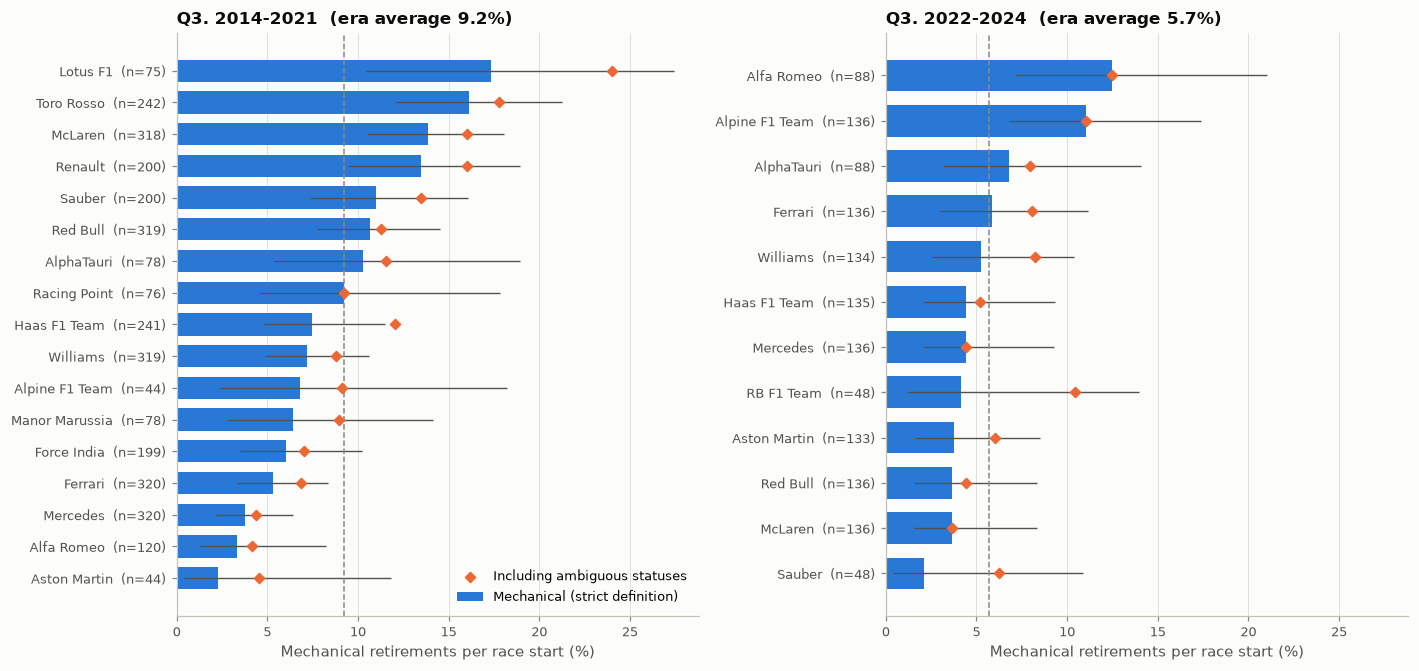


2014-2021: highest mechanical-retirement rates


,starts,mech,mech_broad,rate,rate_broad,lo,hi
constructor,,,,,,,
Lotus F1,75,13,18,17.3,24.0,10.4,27.4
Toro Rosso,242,39,43,16.1,17.8,12.0,21.3
McLaren,318,44,51,13.8,16.0,10.5,18.1
Renault,200,27,32,13.5,16.0,9.4,18.9
Sauber,200,22,27,11.0,13.5,7.4,16.1
Red Bull,319,34,36,10.7,11.3,7.7,14.5



2022-2024: highest mechanical-retirement rates


,starts,mech,mech_broad,rate,rate_broad,lo,hi
constructor,,,,,,,
Alfa Romeo,88,11,11,12.5,12.5,7.1,21.0
Alpine F1 Team,136,15,15,11.0,11.0,6.8,17.4
AlphaTauri,88,6,7,6.8,8.0,3.2,14.1
Ferrari,136,8,11,5.9,8.1,3.0,11.2
Williams,134,7,11,5.2,8.2,2.6,10.4
Haas F1 Team,135,6,7,4.4,5.2,2.1,9.4


In [31]:
MIN_STARTS = 40
starts = window[window["status_class"] != "not started"].copy()
starts["mech"] = (starts["status_class"] == "mechanical").astype(int)
starts["mech_broad"] = starts["status_class"].isin(["mechanical", "ambiguous"]).astype(int)

q3 = starts.groupby(["era", "constructor"]).agg(starts=("mech", "size"), mech=("mech", "sum"), mech_broad=("mech_broad", "sum")).reset_index()
q3["rate"] = q3["mech"] / q3["starts"]
q3["rate_broad"] = q3["mech_broad"] / q3["starts"]
q3["lo"], q3["hi"] = wilson(q3["mech"], q3["starts"])
q3 = q3[q3["starts"] >= MIN_STARTS]
era_overall = starts.groupby("era")[["mech", "mech_broad"]].mean()
print("Overall mechanical-retirement rate per start:", {k: f"{v * 100:.1f}%" for k, v in era_overall["mech"].items()})

fig, axes = plt.subplots(1, 2, figsize=(13, 6.2), sharex=True)
for ax, e in zip(axes, ["2014-2021", "2022-2024"]):
    d = q3[q3["era"] == e].sort_values("rate")
    y = np.arange(len(d))
    ax.barh(y, d["rate"] * 100, color=C["blue"], height=0.7, label="Mechanical (strict definition)")
    ax.errorbar(d["rate"] * 100, y, xerr=[(d["rate"] - d["lo"]) * 100, (d["hi"] - d["rate"]) * 100], fmt="none", ecolor=C["ink2"], linewidth=0.9)
    ax.scatter(d["rate_broad"] * 100, y, marker="D", s=22, color=C["orange"], zorder=3, label="Including ambiguous statuses")
    ax.axvline(era_overall.loc[e, "mech"] * 100, color=C["muted"], linestyle="--", linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{n}  (n={s})" for n, s in zip(d["constructor"], d["starts"])], fontsize=8.5)
    ax.set_xlabel("Mechanical retirements per race start (%)")
    ax.set_title(f"Q3. {e}  (era average {era_overall.loc[e, 'mech'] * 100:.1f}%)")
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="lower right")
savefig("q3_mechanical_retirements")

for e in ["2014-2021", "2022-2024"]:
    d = q3[q3["era"] == e].sort_values("rate", ascending=False)
    print(f"\n{e}: highest mechanical-retirement rates")
    display(d.head(6).assign(rate=(d["rate"] * 100).round(1), rate_broad=(d["rate_broad"] * 100).round(1), lo=(d["lo"] * 100).round(1), hi=(d["hi"] * 100).round(1)).set_index("constructor").drop(columns="era"))

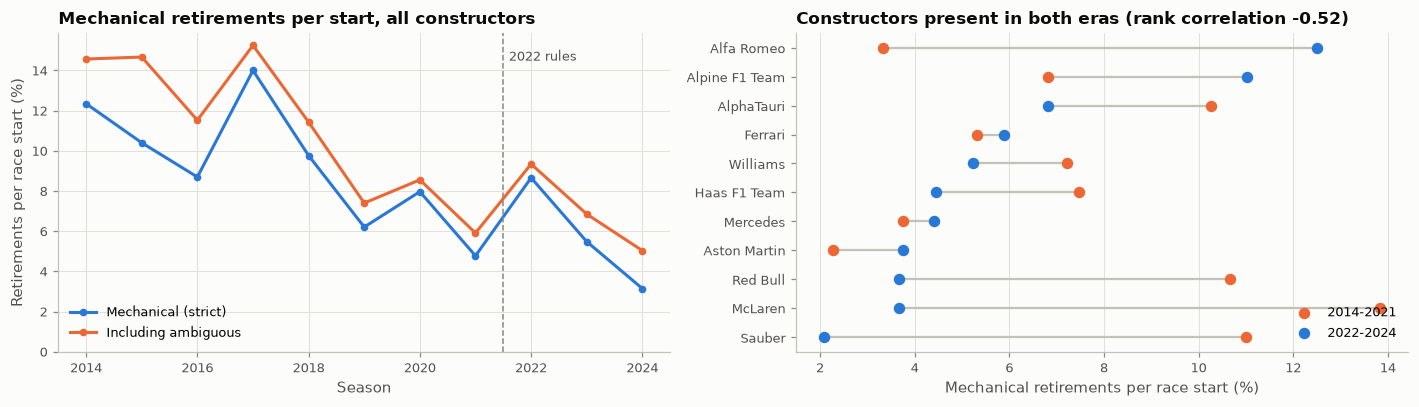

Rank agreement strict vs. broad definition: {'2014-2021': np.float64(0.97), '2022-2024': np.float64(0.7)}


In [32]:
# Trend by season, and how stable the constructor ranking is across the two eras and the two definitions
by_year = starts.groupby("year")[["mech", "mech_broad"]].mean() * 100
wide = q3.pivot(index="constructor", columns="era", values="rate").dropna()
rho_era, p_era = spearmanr(wide["2014-2021"], wide["2022-2024"])
rho_defn = {e: spearmanr(q3.loc[q3["era"] == e, "rate"], q3.loc[q3["era"] == e, "rate_broad"])[0] for e in ["2014-2021", "2022-2024"]}

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ax = axes[0]
ax.plot(by_year.index, by_year["mech"], color=C["blue"], marker="o", markersize=4, label="Mechanical (strict)")
ax.plot(by_year.index, by_year["mech_broad"], color=C["orange"], marker="o", markersize=4, label="Including ambiguous")
ax.axvline(2021.5, color=C["muted"], linestyle="--", linewidth=1)
ax.text(2021.6, by_year["mech_broad"].max() * 0.95, "2022 rules", fontsize=8.5, color=C["ink2"])
ax.set_xlabel("Season")
ax.set_ylabel("Retirements per race start (%)")
ax.set_ylim(0, None)
ax.set_title("Mechanical retirements per start, all constructors")
ax.legend()

ax = axes[1]
d = wide.sort_values("2022-2024")
y = np.arange(len(d))
ax.hlines(y, d["2014-2021"] * 100, d["2022-2024"] * 100, color=C["axis"], linewidth=1.5, zorder=1)
ax.scatter(d["2014-2021"] * 100, y, color=C["orange"], s=42, zorder=2, label="2014-2021")
ax.scatter(d["2022-2024"] * 100, y, color=C["blue"], s=42, zorder=2, label="2022-2024")
ax.set_yticks(y)
ax.set_yticklabels(d.index)
ax.set_xlabel("Mechanical retirements per race start (%)")
ax.set_title(f"Constructors present in both eras (rank correlation {rho_era:.2f})")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
savefig("q3_trend_and_change")
print("Rank agreement strict vs. broad definition:", {k: round(v, 2) for k, v in rho_defn.items()})

In [33]:
def top_list(e, n=3):
    d = q3[q3["era"] == e].sort_values("rate", ascending=False).head(n)
    return ", ".join(f"**{c}** {r * 100:.1f}% ({m}/{s})" for c, r, m, s in zip(d["constructor"], d["rate"], d["mech"], d["starts"]))
def bottom_list(e, n=2):
    d = q3[q3["era"] == e].sort_values("rate").head(n)
    return ", ".join(f"{c} {r * 100:.1f}%" for c, r in zip(d["constructor"], d["rate"]))
md(f"""
**Answer to Question 3**

- **2014–2021.** Highest mechanical-retirement rates per race start: {top_list('2014-2021')}. Lowest: {bottom_list('2014-2021')}. Era average: {era_overall.loc['2014-2021', 'mech'] * 100:.1f}%.
- **2022–2024.** Highest: {top_list('2022-2024')}. Lowest: {bottom_list('2022-2024')}. Era average: {era_overall.loc['2022-2024', 'mech'] * 100:.1f}%.
- **Change between eras.** Reliability improved across the field: the average rate fell from {era_overall.loc['2014-2021', 'mech'] * 100:.1f}% to {era_overall.loc['2022-2024', 'mech'] * 100:.1f}% of starts. For the constructors present in both eras, the rank correlation is {rho_era:.2f} (p = {p_era:.2f}), which measures how far the reliability order of one era carries over to the next (1 = same order, 0 = unrelated).
- **Sensitivity.** Counting the ambiguous statuses as mechanical raises the rates but leaves the 2014–2021 order almost unchanged (rank agreement {rho_defn['2014-2021']:.2f}). In 2022–2024 agreement is lower ({rho_defn['2022-2024']:.2f}) because counts are small — a handful of borderline retirements can move a team several places — so the top of that list is reliable but the middle is not.
""")


**Answer to Question 3**

- **2014–2021.** Highest mechanical-retirement rates per race start: **Lotus F1** 17.3% (13/75), **Toro Rosso** 16.1% (39/242), **McLaren** 13.8% (44/318). Lowest: Aston Martin 2.3%, Alfa Romeo 3.3%. Era average: 9.2%.
- **2022–2024.** Highest: **Alfa Romeo** 12.5% (11/88), **Alpine F1 Team** 11.0% (15/136), **AlphaTauri** 6.8% (6/88). Lowest: Sauber 2.1%, McLaren 3.7%. Era average: 5.7%.
- **Change between eras.** Reliability improved across the field: the average rate fell from 9.2% to 5.7% of starts. For the constructors present in both eras, the rank correlation is -0.52 (p = 0.10), which measures how far the reliability order of one era carries over to the next (1 = same order, 0 = unrelated).
- **Sensitivity.** Counting the ambiguous statuses as mechanical raises the rates but leaves the 2014–2021 order almost unchanged (rank agreement 0.97). In 2022–2024 agreement is lower (0.70) because counts are small — a handful of borderline retirements can move a team several places — so the top of that list is reliable but the middle is not.


**Reading the result.** The 2014–2021 list is led by teams that ran the Renault and Honda power units of the early hybrid years (Lotus, Toro Rosso, McLaren, Renault, Red Bull), which is consistent with the well-documented reliability problems of those units; this is context, not something the data alone proves. In 2022–2024 rates are lower overall and the intervals are wide (a team has only about 130 starts in three seasons), so differences between mid-table teams in that era are within noise.

Two caveats. First, team identity follows `constructorId`: a renamed team (Toro Rosso → AlphaTauri → RB, Force India → Racing Point → Aston Martin, Renault → Alpine, Sauber → Alfa Romeo) appears as separate constructors. Second, the result depends on how free-text statuses are classed; that is why the classification is explicit in code and a sensitivity check is shown.

The same status classification is reused in Section 6 to build a past-only constructor reliability feature.

## 6. Leakage audit and feature engineering

### 6.1 Which fields are known at the prediction cutoff?

The prediction is made **after qualifying and before the race starts**. A field may be used as a feature only if its value is fixed by that moment. The audit below classifies every source of information. The test applied to each field is: *"Could this value still change, or does it only come into existence, once the race is running?"*

In [34]:
leakage_audit = pd.DataFrame([
    ("results", "grid", "pre-race", "Final starting grid is published before the start", "Used"),
    ("results", "constructorId, number", "pre-race", "Entry list is known before the weekend", "Used for joins / team features"),
    ("results", "position, positionText, positionOrder", "POST-RACE", "This is the race outcome; positionOrder defines the target", "Target only; past races feed form features"),
    ("results", "points", "POST-RACE", "Awarded for the finishing position", "Excluded"),
    ("results", "laps, time, milliseconds", "POST-RACE", "Race distance and race time", "Excluded"),
    ("results", "fastestLap, rank, fastestLapTime, fastestLapSpeed", "POST-RACE", "Set during the race", "Excluded"),
    ("results", "statusId", "POST-RACE", "Finish / retirement reason", "Excluded; past races feed reliability features"),
    ("qualifying", "position, q1, q2, q3", "pre-race", "Qualifying ends before the cutoff", "Used"),
    ("driver_standings", "points, position, wins (same raceId)", "POST-RACE", "Standings rows are published AFTER the race they are keyed to", "Excluded; the PREVIOUS round's row is used"),
    ("constructor_standings", "points, position, wins (same raceId)", "POST-RACE", "Same as driver standings", "Excluded; the PREVIOUS round's row is used"),
    ("constructor_results", "points", "POST-RACE", "Team points scored in the race", "Excluded"),
    ("lap_times", "all columns", "POST-RACE", "Recorded lap by lap during the race", "Excluded"),
    ("pit_stops", "all columns", "POST-RACE", "Happen during the race", "Excluded"),
    ("sprint_results", "all columns", "ambiguous", "Sprint is run before the race, but its place relative to qualifying changed between 2021 and 2024", "Excluded to keep one consistent cutoff"),
    ("races", "year, round, circuitId, date", "pre-race", "Calendar is fixed in advance", "Used"),
    ("drivers", "dob, nationality", "pre-race", "Static driver attributes", "Used"),
    ("circuits", "country", "pre-race", "Static circuit attribute", "Used"),
], columns=["table", "fields", "available at cutoff?", "reason", "decision"])
display(leakage_audit.style.hide(axis="index").set_properties(**{"text-align": "left"}))

table,fields,available at cutoff?,reason,decision
results,grid,pre-race,Final starting grid is published before the start,Used
results,"constructorId, number",pre-race,Entry list is known before the weekend,Used for joins / team features
results,"position, positionText, positionOrder",POST-RACE,This is the race outcome; positionOrder defines the target,Target only; past races feed form features
results,points,POST-RACE,Awarded for the finishing position,Excluded
results,"laps, time, milliseconds",POST-RACE,Race distance and race time,Excluded
results,"fastestLap, rank, fastestLapTime, fastestLapSpeed",POST-RACE,Set during the race,Excluded
results,statusId,POST-RACE,Finish / retirement reason,Excluded; past races feed reliability features
qualifying,"position, q1, q2, q3",pre-race,Qualifying ends before the cutoff,Used
driver_standings,"points, position, wins (same raceId)",POST-RACE,Standings rows are published AFTER the race they are keyed to,Excluded; the PREVIOUS round's row is used
constructor_standings,"points, position, wins (same raceId)",POST-RACE,Same as driver standings,Excluded; the PREVIOUS round's row is used


**The two traps that are easy to miss.**

1. **Standings are keyed to the race they follow.** `driver_standings` for `raceId = X` already includes the points scored *in* race X. Joining standings on the same `raceId` would hand the model the answer. We therefore join the standings of the **previous round**.
2. **Form features must use past races only.** A "podium rate over the last five races" that includes the current race contains the target. Every rolling or cumulative statistic below is shifted by one race before it is used.

Section 6.3 tests both mechanically.

### 6.2 Feature construction

All features are built by one function, `build_features`, so the exact same code can be re-run on altered data for the leakage test. Features are computed on the **full 1950–2024 history** (so that a driver in 2003 already has a record) and the modeling table then keeps 2003–2024.

| Group | Feature | Definition | Why it is valid at the cutoff |
|---|---|---|---|
| **Grid** | `grid_pos` | Starting slot; `grid = 0` recoded to "behind the last car" | Grid is published before the start |
| | `pit_lane_start` | 1 if `grid = 0` | Same |
| | `grid_drop` | `grid_pos − quali_pos` (positive = lost places to a penalty) | Both known before the start |
| **Qualifying** | `quali_pos` | Qualifying classification | Qualifying is over |
| | `quali_gap_pct` | Best qualifying lap vs. the fastest lap of the session, in % | Same |
| | `mate_quali_gap_pct` | Best lap vs. the team-mate's best lap, in % (driver vs. same car) | Same |
| | `team_best_gap_pct` | Smaller of the two cars' gaps to pole (car pace this weekend) | Same |
| | `quali_missing` | 1 if the driver has no qualifying record | Same |
| **Driver form** | `drv_podium_rate_5`, `drv_avg_finish_5` | Podium rate and mean finishing position over the driver's **previous** 5 races | Past races only (shifted) |
| | `drv_dnf_rate_10` | Share of the previous 10 races not finished | Past races only |
| | `drv_career_podium_rate`, `drv_career_starts` | Career podium rate and number of races **before** this one | Past races only |
| | `drv_circuit_podium_rate`, `drv_circuit_starts` | Same, restricted to earlier visits to this circuit | Past races only |
| **Constructor form** | `con_podium_rate_5`, `con_avg_finish_5` | Team podium rate and mean finish over the team's previous 5 races (both cars) | Past races only |
| | `con_mech_rate_10` | Team mechanical-retirement rate over the previous 10 races (classification from Question 3) | Past races only |
| **Standings** | `drv_stand_pos`, `drv_points_share`, `drv_wins` | Championship position, points as a share of the leader's points, and wins **after the previous round** | Previous round's standings |
| | `con_stand_pos`, `con_points_share` | Same for the constructor | Previous round's standings |
| **Context** | `is_home` | Circuit is in the driver's home country (Question 2) | Static |
| | `season_progress` | Round ÷ rounds in the season | Calendar |
| | `field_size` | Number of entries in the race | Entry list |
| | `driver_age` | Age on race day | Static |
| | `circuit_front_conv_prior` | Smoothed front-row→podium rate at this circuit in **earlier** races (Question 1) | Past races only |

**Design choices.**

- **Points are expressed as a share of the leader's points**, not raw points. The points system changed in 2010 (a win went from 10 to 25 points), so raw points are not comparable across seasons, while a share is.
- **At round 1 there are no standings yet**, so the final standings of the previous season are carried over. A driver or team with no standing at all (a rookie, a new team) is placed one position behind the last ranked entry, with zero points share. This is a domain rule, not a statistical fill: "unranked" genuinely means "behind everyone ranked".
- **Qualifying gaps are capped** at 10% (gap to pole) and ±5% (gap to team-mate). Larger values come from sessions where the weather changed between runs, and say nothing about pace.
- **Rookies have no form history.** Their form features are left missing here and filled inside the model pipeline (Section 9), where the fill value is learned from training data only.

In [35]:
FEATURE_GROUPS = {
    "grid": ["grid_pos", "pit_lane_start", "grid_drop"],
    "qualifying": ["quali_pos", "quali_gap_pct", "mate_quali_gap_pct", "team_best_gap_pct", "quali_missing"],
    "driver_form": ["drv_podium_rate_5", "drv_avg_finish_5", "drv_dnf_rate_10", "drv_career_podium_rate", "drv_career_starts",
                    "drv_circuit_podium_rate", "drv_circuit_starts"],
    "constructor_form": ["con_podium_rate_5", "con_avg_finish_5", "con_mech_rate_10"],
    "standings": ["drv_stand_pos", "drv_points_share", "drv_wins", "con_stand_pos", "con_points_share"],
    "context": ["is_home", "season_progress", "field_size", "driver_age", "circuit_front_conv_prior"],
}
FEATURES = [f for group in FEATURE_GROUPS.values() for f in group]
GROUP_OF = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}
GROUP_COLOR = dict(zip(FEATURE_GROUPS, SERIES))
KEYS = ["raceId", "driverId", "constructorId", "year", "round", "circuitId", "date"]
STATUS_CLASS = dict(zip(status["statusId"].astype(int), status["status_class"]))

def prior_standings(standings, races_tbl, entity):
    """Standings as they stood BEFORE each race: previous round of the same season, or last season's final table at round 1."""
    st = standings.merge(races_tbl[["raceId", "year", "round"]], on="raceId")
    st[["points", "position", "wins"]] = st[["points", "position", "wins"]].astype(float)
    table = st.groupby(["year", "round"]).agg(leader_points=("points", "max"), ranked=("position", "max")).reset_index()
    st = st.merge(table, on=["year", "round"])
    st["points_share"] = np.where(st["leader_points"] > 0, st["points"] / st["leader_points"], 0.0)

    cal = races_tbl[["raceId", "year", "round"]].copy()
    last_round = cal.groupby("year")["round"].max()
    cal["src_year"] = np.where(cal["round"] > 1, cal["year"], cal["year"] - 1)
    cal["src_round"] = np.where(cal["round"] > 1, cal["round"] - 1, cal["year"].map(lambda y: last_round.get(y - 1, np.nan)))
    cal = cal.merge(table.rename(columns={"year": "src_year", "round": "src_round"}), on=["src_year", "src_round"], how="left")
    per_entity = st[["year", "round", entity, "position", "points_share", "wins"]].rename(columns={"year": "src_year", "round": "src_round"})
    return cal[["raceId", "src_year", "src_round", "ranked"]], per_entity

def build_features(results_tbl, races_tbl, qualifying_tbl, driver_standings_tbl, constructor_standings_tbl, drivers_tbl, circuits_tbl):
    """One row per (raceId, driverId) with pre-race features. Outcome columns are only ever used after a one-race shift."""
    order = races_tbl.sort_values(["date", "raceId"]).reset_index(drop=True)
    order["race_seq"] = np.arange(len(order))
    order["season_rounds"] = order.groupby("year")["round"].transform("max")
    df = results_tbl[["raceId", "driverId", "constructorId", "grid", "positionOrder", "statusId"]].merge(
        order[["raceId", "year", "round", "circuitId", "date", "race_seq", "season_rounds"]], on="raceId", how="left")
    df[["grid", "positionOrder"]] = df[["grid", "positionOrder"]].astype(float)

    # ---- outcome columns (post-race). Used ONLY through shifted, past-only aggregates below.
    cls = df["statusId"].astype(int).map(STATUS_CLASS)
    df["o_podium"] = (df["positionOrder"] <= 3).astype(float)
    df["o_finish"] = df["positionOrder"]
    df["o_dnf"] = (~cls.isin(["finished"])).astype(float)
    df["o_mech"] = (cls == "mechanical").astype(float)

    # ---- grid group
    df["field_size"] = df.groupby("raceId")["driverId"].transform("size").astype(float)
    df["pit_lane_start"] = (df["grid"] == 0).astype(float)
    last_slot = df.groupby("raceId")["grid"].transform("max")
    df["grid_pos"] = np.where(df["grid"] > 0, df["grid"], last_slot + 1)

    # ---- qualifying group
    q = qualifying_tbl[["raceId", "driverId", "constructorId", "position", "best_s"]].rename(columns={"position": "quali_pos"})
    q["quali_pos"] = q["quali_pos"].astype(float)
    q["quali_gap_pct"] = ((q["best_s"] / q.groupby("raceId")["best_s"].transform("min") - 1) * 100).clip(upper=10)
    team = q.groupby(["raceId", "constructorId"])["best_s"]
    n_timed, team_sum = team.transform("count"), team.transform("sum")
    mate_best = np.where(n_timed == 2, team_sum - q["best_s"], np.nan)            # the other car's best lap
    q["mate_quali_gap_pct"] = ((q["best_s"] / mate_best - 1) * 100).clip(-5, 5)
    q["team_best_gap_pct"] = q.groupby(["raceId", "constructorId"])["quali_gap_pct"].transform("min")
    df = df.merge(q.drop(columns=["constructorId", "best_s"]), on=["raceId", "driverId"], how="left")
    df["quali_missing"] = df["quali_pos"].isna().astype(float)
    df["grid_drop"] = df["grid_pos"] - df["quali_pos"]

    # ---- driver form: sort by time, shift by one race, then aggregate
    df = df.sort_values(["race_seq", "driverId"]).reset_index(drop=True)
    by_driver = df.groupby("driverId", sort=False)
    past = lambda col, window: by_driver[col].transform(lambda s: s.shift(1).rolling(window, min_periods=1).mean())
    df["drv_podium_rate_5"] = past("o_podium", 5)
    df["drv_avg_finish_5"] = past("o_finish", 5)
    df["drv_dnf_rate_10"] = past("o_dnf", 10)
    df["drv_career_podium_rate"] = by_driver["o_podium"].transform(lambda s: s.shift(1).expanding().mean())
    df["drv_career_starts"] = by_driver.cumcount().astype(float)
    by_dc = df.groupby(["driverId", "circuitId"], sort=False)
    df["drv_circuit_podium_rate"] = by_dc["o_podium"].transform(lambda s: s.shift(1).expanding().mean())
    df["drv_circuit_starts"] = by_dc.cumcount().astype(float)

    # ---- constructor form: aggregate both cars per race, then shift by one race
    team_race = (df.groupby(["constructorId", "race_seq"], sort=False)
                   .agg(cars=("driverId", "size"), podiums=("o_podium", "sum"), finish_sum=("o_finish", "sum"), mech=("o_mech", "sum"))
                   .reset_index().sort_values(["constructorId", "race_seq"]))
    by_team = team_race.groupby("constructorId", sort=False)
    roll = lambda col, window: by_team[col].transform(lambda s: s.shift(1).rolling(window, min_periods=1).sum())
    team_race["con_podium_rate_5"] = roll("podiums", 5) / roll("cars", 5)
    team_race["con_avg_finish_5"] = roll("finish_sum", 5) / roll("cars", 5)
    team_race["con_mech_rate_10"] = roll("mech", 10) / roll("cars", 10)
    df = df.merge(team_race[["constructorId", "race_seq", "con_podium_rate_5", "con_avg_finish_5", "con_mech_rate_10"]],
                  on=["constructorId", "race_seq"], how="left")

    # ---- standings before the race (previous round; previous season's final table at round 1)
    for entity, tbl, prefix in [("driverId", driver_standings_tbl, "drv"), ("constructorId", constructor_standings_tbl, "con")]:
        source, per_entity = prior_standings(tbl, races_tbl, entity)
        df = df.merge(source, on="raceId", how="left").merge(per_entity, on=["src_year", "src_round", entity], how="left")
        unranked = df["position"].isna()
        df[f"{prefix}_stand_pos"] = np.where(unranked, df["ranked"] + 1, df["position"])
        df[f"{prefix}_points_share"] = df["points_share"].fillna(0.0)
        df[f"{prefix}_wins"] = df["wins"].fillna(0.0)
        df = df.drop(columns=["src_year", "src_round", "ranked", "position", "points_share", "wins"])
    df = df.drop(columns=["con_wins"])

    # ---- context
    people = drivers_tbl[["driverId", "dob", "nationality"]]
    df = df.merge(people, on="driverId", how="left").merge(circuits_tbl[["circuitId", "country"]], on="circuitId", how="left")
    df["is_home"] = np.array([is_home(n, c) for n, c in zip(df["nationality"], df["country"])], dtype=float)
    df["driver_age"] = (df["date"] - df["dob"]).dt.days / 365.25
    df["season_progress"] = df["round"].astype(float) / df["season_rounds"].astype(float)

    # circuit front-row conversion from EARLIER races only, shrunk towards the running all-circuit rate
    front = df[df["grid"].isin([1, 2])].groupby(["race_seq", "circuitId"]).agg(k=("o_podium", "sum"), n=("o_podium", "size")).reset_index().sort_values("race_seq")
    global_rate = (front["k"].cumsum().shift(1) / front["n"].cumsum().shift(1)).fillna(0.6)
    past_k = front.groupby("circuitId")["k"].transform(lambda s: s.shift(1).cumsum()).fillna(0)
    past_n = front.groupby("circuitId")["n"].transform(lambda s: s.shift(1).cumsum()).fillna(0)
    SHRINK = 10                                           # behaves like 10 prior front-row starts at the global rate
    front["circuit_front_conv_prior"] = (past_k + SHRINK * global_rate) / (past_n + SHRINK)
    df = df.merge(front[["race_seq", "circuit_front_conv_prior"]], on="race_seq", how="left")

    df["podium"] = df["o_podium"].astype(int)
    return df[KEYS + FEATURES + ["podium"]].sort_values(["date", "raceId", "driverId"]).reset_index(drop=True)

t0 = time.time()
SOURCE = dict(results_tbl=results_clean, races_tbl=CLEAN["races"], qualifying_tbl=CLEAN["qualifying"],
              driver_standings_tbl=CLEAN["driver_standings"], constructor_standings_tbl=CLEAN["constructor_standings"],
              drivers_tbl=CLEAN["drivers"], circuits_tbl=CLEAN["circuits"])
features_all = build_features(**SOURCE)
print(f"Feature table built in {time.time() - t0:.1f}s: {features_all.shape[0]:,} rows x {len(FEATURES)} features")
assert not features_all.duplicated(["raceId", "driverId"]).any() and len(features_all) == len(results_clean)

Feature table built in 1.5s: 26,668 rows x 28 features


### 6.3 Leakage tests

Reading the code is not proof, so leakage safety is tested by experiment.

**Test 1 — "scramble the future".** Pick a race. In a copy of the data, destroy every post-race fact for that race **and every later race**: shuffle finishing positions, overwrite the status, and overwrite the standings published after those races. Rebuild all features. If the features of the chosen race use only pre-race information, they must be **exactly unchanged**. This is repeated for several races.

**Test 2 — negative control.** The same test is applied to a deliberately leaky feature (standings joined on the *same* `raceId`). It must fail; otherwise the test would not be able to detect leakage at all.

In [36]:
def scramble_from(race_id, seed=0):
    """Copy of the source tables with all post-race information destroyed from race_id onwards."""
    rng = np.random.default_rng(seed)
    cutoff = CLEAN["races"].set_index("raceId").loc[race_id, "date"]
    future = set(CLEAN["races"].loc[CLEAN["races"]["date"] >= cutoff, "raceId"])
    res = results_clean.copy()
    hit = res["raceId"].isin(future)
    res.loc[hit, "positionOrder"] = res[hit].groupby("raceId")["positionOrder"].transform(lambda s: rng.permutation(s.values))
    res.loc[hit, "statusId"] = 5                                               # everybody "Engine"
    tables = dict(SOURCE, results_tbl=res)
    for key in ["driver_standings_tbl", "constructor_standings_tbl"]:
        st = SOURCE[key].copy()
        hit = st["raceId"].isin(future)
        st.loc[hit, ["points", "wins"]] = 999
        st.loc[hit, "position"] = 1
        tables[key] = st
    return tables

def leaky_standings(tables):
    """The WRONG join: standings keyed to the same raceId (published after the race)."""
    st = tables["driver_standings_tbl"][["raceId", "driverId", "points"]].rename(columns={"points": "leaky_points"})
    return features_all[["raceId", "driverId"]].merge(st, on=["raceId", "driverId"], how="left")

rng = np.random.default_rng(SEED)
modern_races = CLEAN["races"].loc[CLEAN["races"]["year"] >= 2003, "raceId"].values
test_races = rng.choice(modern_races, size=6, replace=False)
rows = []
for rid in test_races:
    tables = scramble_from(int(rid))
    rebuilt = build_features(**tables)
    a = features_all.loc[features_all["raceId"] == rid].set_index("driverId")[FEATURES]
    b = rebuilt.loc[rebuilt["raceId"] == rid].set_index("driverId")[FEATURES].reindex(a.index)
    changed = [f for f in FEATURES if not np.allclose(a[f].astype(float), b[f].astype(float), equal_nan=True)]
    la = leaky_standings(SOURCE).query("raceId == @rid")["leaky_points"].astype(float).values
    lb = leaky_standings(tables).query("raceId == @rid")["leaky_points"].astype(float).values
    info = CLEAN["races"].set_index("raceId").loc[rid]
    rows.append({"race": f"{int(info['year'])} R{int(info['round'])}", "rows": len(a), "features changed": len(changed),
                 "leak-free": len(changed) == 0, "negative control changed": not np.allclose(la, lb, equal_nan=True)})
leak_test = pd.DataFrame(rows)
display(leak_test)
assert leak_test["leak-free"].all(), "a feature depends on current or future race outcomes"
assert leak_test["negative control changed"].all(), "the test failed to detect a known leak"
print("PASS: all", len(FEATURES), "features are unchanged when current and future outcomes are scrambled;")
print("      the deliberately leaky feature is detected in every case.")

,race,rows,features changed,leak-free,negative control changed
0,2017 R20,20,0,True,True
1,2020 R8,20,0,True,True
2,2013 R4,22,0,True,True
3,2022 R8,20,0,True,True
4,2013 R6,22,0,True,True
5,2007 R3,22,0,True,True


PASS: all 28 features are unchanged when current and future outcomes are scrambled;
      the deliberately leaky feature is detected in every case.


**Result.** For every sampled race, all features are identical before and after the future is scrambled, and the deliberately leaky join is caught each time. The feature set is leakage-safe by test, not only by intention.

### 6.4 The modeling table

Modeling table: 8,970 rows = 428 races x drivers, seasons 2003-2024
Unique (raceId, driverId): True   |   podium share: 14.3%


,raceId,driverId,constructorId,year,round,circuitId,date,grid_pos,pit_lane_start,grid_drop,quali_pos,quali_gap_pct,mate_quali_gap_pct,team_best_gap_pct,quali_missing,drv_podium_rate_5,drv_avg_finish_5,drv_dnf_rate_10,drv_career_podium_rate,drv_career_starts,drv_circuit_podium_rate,drv_circuit_starts,con_podium_rate_5,con_avg_finish_5,con_mech_rate_10,drv_stand_pos,drv_points_share,drv_wins,con_stand_pos,con_points_share,is_home,season_progress,field_size,driver_age,circuit_front_conv_prior,podium
0,108,2,15,2003,1,1,2003-03-09,7.0,0.0,0.0,7.0,1.480963,0.215239,1.263006,0.0,0.0,9.0,0.0,0.020000,50.0,0.0,3.0,0.0,11.6,0.10,10.0,0.048611,0.0,5.0,0.049774,0.0,0.0625,20.0,25.828884,0.510649,0
1,108,4,4,2003,1,1,2003-03-09,10.0,0.0,0.0,10.0,2.013238,-0.233351,2.013238,0.0,0.0,17.0,0.5,0.000000,17.0,0.0,1.0,0.0,10.4,0.35,23.0,0.000000,0.0,4.0,0.104072,0.0,0.0625,20.0,21.609856,0.510649,0
2,108,8,1,2003,1,1,2003-03-09,15.0,0.0,0.0,15.0,2.634990,0.409629,2.216283,0.0,0.2,11.0,0.5,0.117647,34.0,0.5,2.0,0.2,9.2,0.25,6.0,0.166667,0.0,3.0,0.294118,0.0,0.0625,20.0,23.392197,0.510649,1


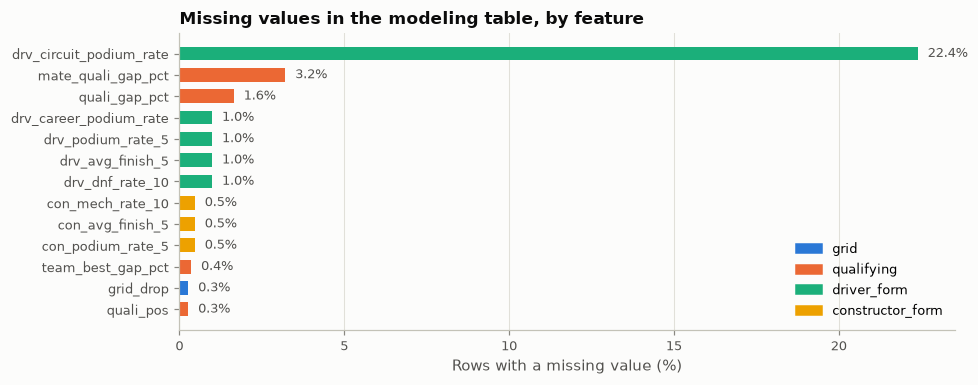

In [37]:
MODEL_START = 2003
table = features_all[features_all["year"] >= MODEL_START].reset_index(drop=True)
table[FEATURES] = table[FEATURES].astype(float)

assert not table.duplicated(["raceId", "driverId"]).any()
assert table.groupby("raceId")["podium"].sum().eq(3).all()          # exactly three podium places per race in this window
table.to_csv(os.path.join(OUT_DIR, "modeling_table.csv"), index=False)

print(f"Modeling table: {len(table):,} rows = {table['raceId'].nunique()} races x drivers, seasons {table['year'].min()}-{table['year'].max()}")
print(f"Unique (raceId, driverId): {not table.duplicated(['raceId', 'driverId']).any()}   |   podium share: {table['podium'].mean() * 100:.1f}%")
display(table.head(3))

missing = (table[FEATURES].isna().mean() * 100).sort_values()
missing = missing[missing > 0]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(missing.index, missing.values, color=[GROUP_COLOR[GROUP_OF[f]] for f in missing.index], height=0.65)
for y, v in enumerate(missing.values):
    ax.text(v + 0.3, y, f"{v:.1f}%", va="center", fontsize=8.5, color=C["ink2"])
ax.legend(handles=[mpl.patches.Patch(color=GROUP_COLOR[g], label=g) for g in FEATURE_GROUPS if any(GROUP_OF[f] == g for f in missing.index)], loc="lower right")
ax.set_xlabel("Rows with a missing value (%)")
ax.set_title("Missing values in the modeling table, by feature")
ax.grid(axis="y", visible=False)
savefig("features_missingness")

**Missingness in the modeling table.** What remains missing has a clear meaning:

- `drv_circuit_podium_rate` — the driver has never raced at this circuit before (first visit). This is the largest group.
- `mate_quali_gap_pct` — the team-mate set no qualifying time, or the team ran one car.
- Form features — a driver's or team's first race (no history yet).
- Qualifying features — the few entries with no qualifying record.

These are filled inside the model pipeline with values learned from the training set (Section 9). `drv_circuit_starts`, `drv_career_starts` and `quali_missing` already tell the model *why* a value is missing.

## 7. Train / validation / test split

**Choice: a chronological split by season.**

| Set | Seasons | Purpose |
|---|---|---|
| Train | 2003–2018 | Fit model parameters |
| Validation | 2019–2021 | Choose features, hyperparameters and the decision threshold |
| Test | 2022–2024 | Final, untouched estimate of performance |

**Why chronological, and not a random split?**

1. **It matches how the model would be used.** The model is trained on past seasons and applied to races that have not happened yet. A random split would train on 2024 races and "predict" 2015, which never happens in practice.
2. **Rows are not independent.** The 20 rows of one race share the same weather, incidents and safety cars, and exactly three of them are positive. A random row split would put some drivers of a race in training and the rest in test, letting the model learn about a race it is being tested on. Splitting by season keeps every race, and every season, whole.
3. **The form features carry the past forward.** With a random split, a test row's "last five races" would overlap with training rows' targets from the same weeks.
4. **The test set is a hard, honest one.** 2022 introduced new technical regulations, so the test seasons differ from the training seasons. This measures how the model copes with a change of era (a limitation discussed in Section 15), instead of hiding it.

The split boundaries are at season ends so that no season is divided. A numerical comparison with a random split is shown in Section 10.8.

,seasons,races,rows,podiums,podium_share,share_of_rows
split,,,,,,
train,2003-2018,300,6411,900,14.0,71.5
val,2019-2021,60,1200,180,15.0,13.4
test,2022-2024,68,1359,204,15.0,15.2


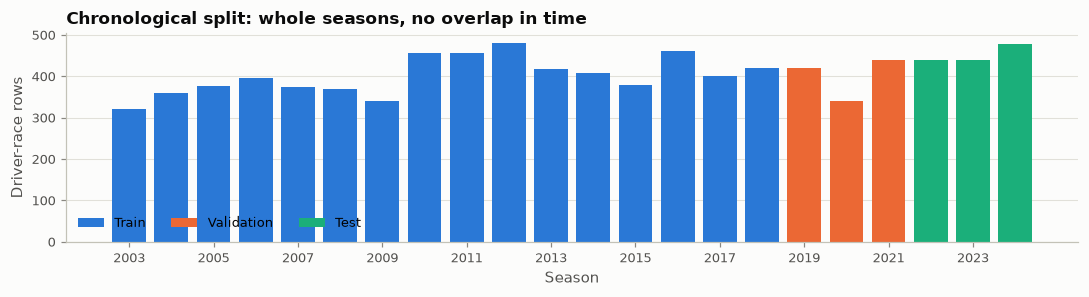

In [38]:
SPLIT = {"train": (2003, 2018), "val": (2019, 2021), "test": (2022, 2024)}
table["split"] = np.select([table["year"] <= SPLIT["train"][1], table["year"] <= SPLIT["val"][1]], ["train", "val"], default="test")
train, val, test = (table[table["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"])
X_train, y_train = train[FEATURES], train["podium"].values
X_val, y_val = val[FEATURES], val["podium"].values
X_test, y_test = test[FEATURES], test["podium"].values

split_summary = table.groupby("split").agg(seasons=("year", lambda s: f"{s.min()}-{s.max()}"), races=("raceId", "nunique"),
                                           rows=("podium", "size"), podiums=("podium", "sum"), podium_share=("podium", "mean")).loc[["train", "val", "test"]]
split_summary["share_of_rows"] = (split_summary["rows"] / len(table) * 100).round(1)
split_summary["podium_share"] = (split_summary["podium_share"] * 100).round(1)
display(split_summary)
assert set(train["raceId"]).isdisjoint(val["raceId"]) and set(val["raceId"]).isdisjoint(test["raceId"])
assert train["date"].max() < val["date"].min() and val["date"].max() < test["date"].min()

fig, ax = plt.subplots(figsize=(10, 2.8))
per_season = table.groupby(["year", "split"]).size().unstack(fill_value=0)
for s, color in zip(["train", "val", "test"], SERIES):
    ax.bar(per_season.index, per_season[s], color=color, width=0.8, label={"train": "Train", "val": "Validation", "test": "Test"}[s])
ax.set_xticks(per_season.index[::2])
ax.set_xlabel("Season")
ax.set_ylabel("Driver-race rows")
ax.set_title("Chronological split: whole seasons, no overlap in time")
ax.legend(ncol=3, loc="lower left")
ax.grid(axis="x", visible=False)
savefig("split_timeline")

The three sets are disjoint in races and strictly ordered in time, and the podium share is nearly the same in each (it is fixed by the field size), so the sets are comparable.

## 8. Feature selection: evidence for each choice

All evidence in this section is computed on the **training seasons only** (and, for trials, scored on validation). The test seasons are not looked at.

Two kinds of evidence are used, as the milestone allows:

- **Hypothesis-driven** — a plot or statistic from EDA that shows the feature is related to the target (8.1–8.3).
- **Trial-and-error** — the feature set is changed, the model is re-trained, and the validation score is compared (8.4).

In [39]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             brier_score_loss, accuracy_score, roc_curve, precision_recall_curve, confusion_matrix, log_loss)

def make_pipeline(model):
    """Median imputation -> standardisation -> model. Every step is fitted on the data passed to .fit() only."""
    return Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()), ("model", model)])

def quick_lr():
    return make_pipeline(LogisticRegression(C=1.0, max_iter=2000))

def quick_gb():
    return make_pipeline(HistGradientBoostingClassifier(max_iter=150, learning_rate=0.05, max_depth=3, early_stopping=False, random_state=SEED))

def val_scores(model, cols, Xtr=None, Xva=None):
    """Fit on train, score on validation. Returns PR-AUC and ROC-AUC."""
    Xtr = X_train if Xtr is None else Xtr
    Xva = X_val if Xva is None else Xva
    model.fit(Xtr[cols], y_train)
    p = model.predict_proba(Xva[cols])[:, 1]
    return {"PR-AUC": average_precision_score(y_val, p), "ROC-AUC": roc_auc_score(y_val, p)}

### 8.1 How strongly is each feature related to the target on its own?

For every feature we report, on the training set:

- **Spearman correlation** with the target (direction and strength of a monotonic relationship),
- **univariate ROC-AUC** — how well the feature alone ranks podium rows above non-podium rows (0.5 = useless, 1 = perfect; direction ignored),
- **mutual information** — picks up relationships that are not monotonic.

,feature,group,missing_%,spearman,univariate_auc,mutual_info
0,quali_pos,qualifying,0.3,-0.494,0.909,0.166
1,grid_pos,grid,0.0,-0.490,0.907,0.165
2,quali_gap_pct,qualifying,1.8,-0.475,0.893,0.148
3,team_best_gap_pct,qualifying,0.4,-0.468,0.888,0.137
4,con_points_share,standings,0.0,0.469,0.888,0.143
5,drv_stand_pos,standings,0.0,-0.464,0.885,0.143
6,drv_points_share,standings,0.0,0.463,0.882,0.134
7,con_avg_finish_5,constructor_form,0.5,-0.452,0.875,0.122
8,con_podium_rate_5,constructor_form,0.5,0.507,0.872,0.128
9,con_stand_pos,standings,0.0,-0.437,0.862,0.129


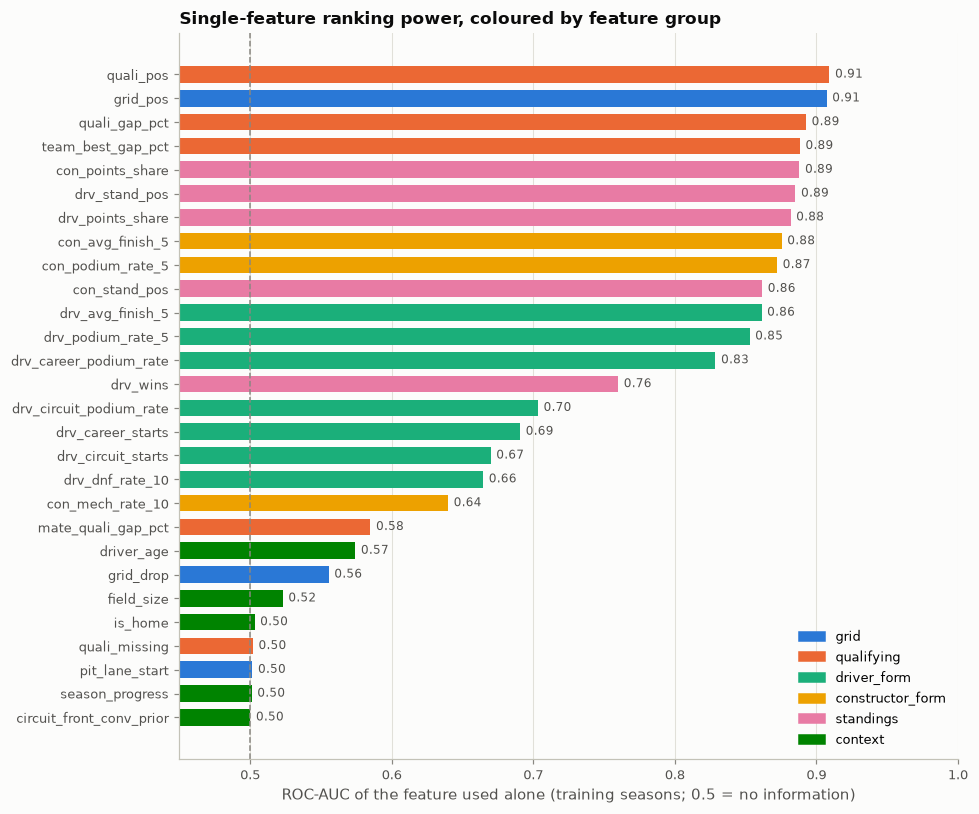

In [40]:
rows = []
filled = X_train.fillna(X_train.median())
mi = mutual_info_classif(filled, y_train, random_state=SEED)
for f, m in zip(FEATURES, mi):
    x = X_train[f]
    ok = x.notna()
    auc = roc_auc_score(y_train[ok], x[ok]) if x[ok].nunique() > 1 else 0.5
    rows.append({"feature": f, "group": GROUP_OF[f], "missing_%": round(x.isna().mean() * 100, 1),
                 "spearman": pd.Series(y_train[ok]).corr(x[ok].reset_index(drop=True), method="spearman"),
                 "univariate_auc": max(auc, 1 - auc), "mutual_info": m})
evidence = pd.DataFrame(rows).sort_values("univariate_auc", ascending=False).reset_index(drop=True)
display(evidence.round(3))

fig, ax = plt.subplots(figsize=(9, 7.5))
d = evidence.sort_values("univariate_auc")
ax.barh(d["feature"], d["univariate_auc"], color=[GROUP_COLOR[g] for g in d["group"]], height=0.7)
for y, v in enumerate(d["univariate_auc"]):
    ax.text(v + 0.004, y, f"{v:.2f}", va="center", fontsize=8, color=C["ink2"])
ax.axvline(0.5, color=C["muted"], linestyle="--", linewidth=1)
ax.set_xlim(0.45, 1.0)
ax.set_xlabel("ROC-AUC of the feature used alone (training seasons; 0.5 = no information)")
ax.set_title("Single-feature ranking power, coloured by feature group")
ax.legend(handles=[mpl.patches.Patch(color=GROUP_COLOR[g], label=g) for g in FEATURE_GROUPS], loc="lower right")
ax.grid(axis="y", visible=False)
savefig("features_univariate_auc")

**Reading the chart.**

- **Grid and qualifying** features are the strongest on their own, as expected from Section 4.5: starting position alone separates podium from non-podium rows very well.
- **Constructor form and standings** come next. The car matters: how the team has been performing recently is almost as informative as where this driver qualified.
- **Driver form** is informative but weaker than team form, which fits the common observation that results in F1 depend heavily on the car.
- **Context features** are weak alone, and for most of them that is unavoidable. `field_size`, `season_progress` and `circuit_front_conv_prior` are **race-level**: every driver in a race has the same value, so on their own they cannot rank one driver above another and must score 0.5. They can only help by changing the *meaning* of other features (standings at round 2 are less reliable than at round 20; a front-row start is worth more at some circuits). `is_home` is close to 0.5, in line with Question 2 (no home effect).
- **Flags** (`pit_lane_start`, `quali_missing`) also sit at 0.5 because they are switched on for fewer than 1% of rows; they exist to describe those rare rows correctly, not to rank the field.
- Whether the weak-alone features earn their place in combination is tested in 8.4 and in the ablation (Section 12).

### 8.2 The shape of the relationship

A correlation gives one number; the plots below show the podium rate across the range of eight features, to check the direction and whether the relationship is linear.

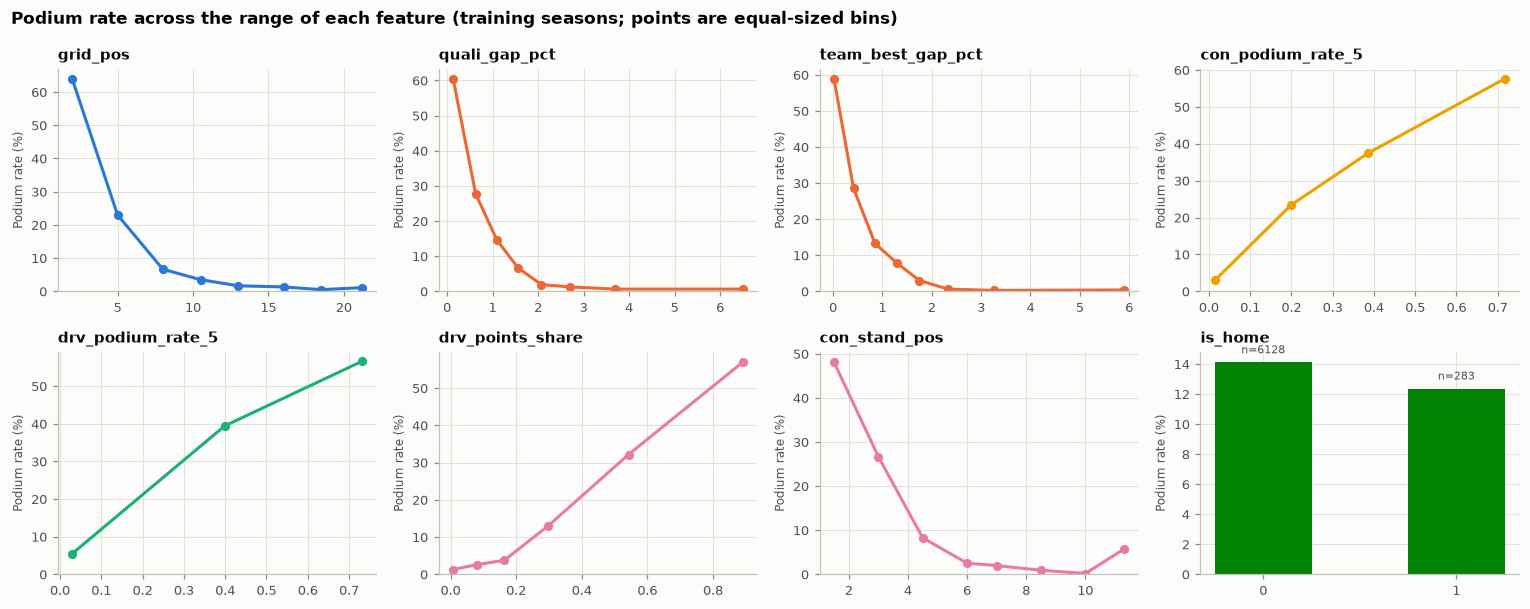

In [41]:
def binned_rate(ax, feature, bins=8):
    x, y = X_train[feature], pd.Series(y_train)
    ok = x.notna().values
    x, y = x[ok].reset_index(drop=True), y[ok].reset_index(drop=True)
    color = GROUP_COLOR[GROUP_OF[feature]]
    if x.nunique() <= 2:
        g = y.groupby(x).agg(["mean", "size"])
        ax.bar([str(int(v)) for v in g.index], g["mean"] * 100, color=color, width=0.5)
        for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
            ax.text(i, m * 100 + 0.6, f"n={n}", ha="center", fontsize=7.5, color=C["ink2"])
    else:
        cut = pd.qcut(x, bins, duplicates="drop")
        g = pd.DataFrame({"x": x, "y": y}).groupby(cut, observed=True).agg(x=("x", "mean"), y=("y", "mean"))
        ax.plot(g["x"], g["y"] * 100, marker="o", markersize=5, color=color)
    ax.set_title(feature, fontsize=9.5)
    ax.set_ylabel("Podium rate (%)", fontsize=8)
    ax.set_ylim(0, None)

show = ["grid_pos", "quali_gap_pct", "team_best_gap_pct", "con_podium_rate_5", "drv_podium_rate_5", "drv_points_share", "con_stand_pos", "is_home"]
fig, axes = plt.subplots(2, 4, figsize=(14, 5.6))
for ax, f in zip(axes.ravel(), show):
    binned_rate(ax, f)
fig.suptitle("Podium rate across the range of each feature (training seasons; points are equal-sized bins)", x=0.01, ha="left", fontsize=11, fontweight="bold")
savefig("features_effect_plots")

**What the shapes say.**

- Every relationship runs in the expected direction (closer to the front, smaller gap to pole, better recent results → higher podium rate).
- Most are **strongly non-linear**: the podium rate is near zero over most of the range and then rises steeply at the front. This is a reason to try tree-based models and a neural network, which can represent such shapes, in addition to a linear model.
- `is_home` shows almost no difference between the two bars, again matching Question 2.

### 8.3 Redundancy between features

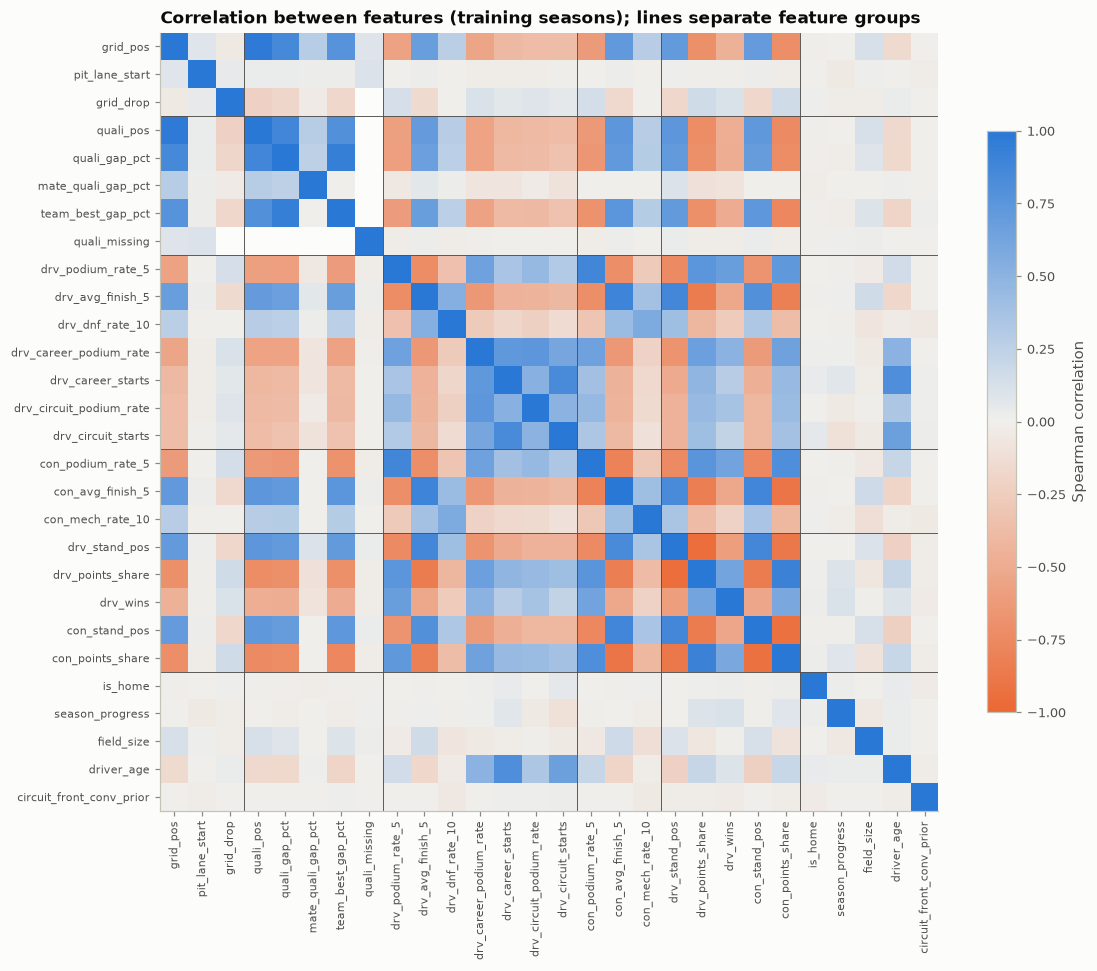

,feature_a,feature_b,spearman
0,grid_pos,quali_pos,0.97
1,drv_stand_pos,drv_points_share,-0.95
2,quali_gap_pct,team_best_gap_pct,0.93
3,con_stand_pos,con_points_share,-0.92
4,drv_points_share,con_points_share,0.91
5,drv_avg_finish_5,con_avg_finish_5,0.90
6,con_avg_finish_5,con_points_share,-0.89
7,quali_pos,quali_gap_pct,0.88
8,con_avg_finish_5,con_stand_pos,0.88
9,drv_podium_rate_5,con_podium_rate_5,0.87


In [42]:
corr = X_train.corr(method="spearman")
fig, ax = plt.subplots(figsize=(10.5, 9))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)))
ax.set_xticklabels(FEATURES, rotation=90, fontsize=7.5)
ax.set_yticks(range(len(FEATURES)))
ax.set_yticklabels(FEATURES, fontsize=7.5)
ax.grid(False)
bounds = np.cumsum([len(v) for v in FEATURE_GROUPS.values()])[:-1] - 0.5
for b in bounds:
    ax.axhline(b, color=C["ink2"], linewidth=0.6)
    ax.axvline(b, color=C["ink2"], linewidth=0.6)
cb = fig.colorbar(im, ax=ax, shrink=0.7)
cb.set_label("Spearman correlation")
ax.set_title("Correlation between features (training seasons); lines separate feature groups")
savefig("features_correlation")

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().rename("spearman").reset_index()
pairs.columns = ["feature_a", "feature_b", "spearman"]
high = pairs[pairs["spearman"].abs() >= 0.8].sort_values("spearman", key=np.abs, ascending=False)
display(high.round(2).reset_index(drop=True))

**What this shows.** Several features are strongly correlated, in two families: (1) `grid_pos`, `quali_pos` and the qualifying gaps, and (2) the "how good is this car/driver lately" features — standings and rolling form. This is expected: they are different measurements of the same underlying things (pace this weekend; strength this season).

**Consequences.**

- Correlated features do not harm the predictions of regularised or tree models, but they **make coefficients and importances unstable**: importance is shared between near-duplicates. For this reason the ablation in Section 12 removes whole **groups**, not single features, and the explanations in Section 13 are read at group level.
- `grid_pos` and `quali_pos` are kept together on purpose. They differ in about a quarter of entries, and Question 1 showed that the difference matters: a driver who qualified on the front row but was moved back converts far less often. `grid_drop` makes that difference explicit.

### 8.4 Trials: does each group, and each encoding choice, earn its place?

**Trial A — add the groups one at a time.** Starting from the grid alone, each group is added and the model re-trained. This shows the value each group adds *on top of* what is already there. Two model types are used so that a conclusion does not depend on one model.

PR-AUC                               ROC-AUC                    
model                         Gradient boosting Logistic regression Gradient boosting Logistic regression
features           n_features                                                                            
grid only          3                     0.6937              0.6923            0.9234              0.9232
+ qualifying       8                     0.7077              0.7030            0.9255              0.9198
+ constructor_form 11                    0.7234              0.7068            0.9371              0.9260
+ standings        16                    0.7513              0.7249            0.9407              0.9307
+ driver_form      23                    0.7450              0.7297            0.9391              0.9308
+ context          28                    0.7450              0.7247            0.9389              0.9309

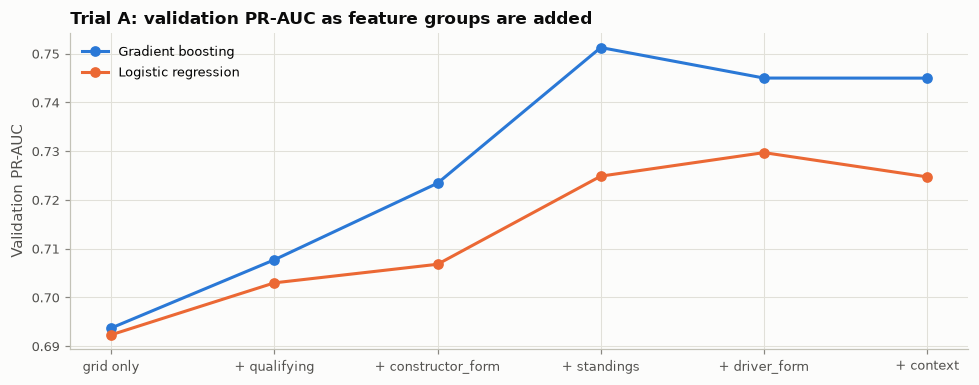

In [43]:
order = ["grid", "qualifying", "constructor_form", "standings", "driver_form", "context"]
rows, cols = [], []
for g in order:
    cols = cols + FEATURE_GROUPS[g]
    for name, maker in [("Logistic regression", quick_lr), ("Gradient boosting", quick_gb)]:
        rows.append({"features": "+ " + g if g != "grid" else "grid only", "n_features": len(cols), "model": name, **val_scores(maker(), cols)})
trial_a = pd.DataFrame(rows)
wide_a = trial_a.pivot(index="features", columns="model", values="PR-AUC").loc[["grid only"] + ["+ " + g for g in order[1:]]]
display(trial_a.pivot(index=["features", "n_features"], columns="model", values=["PR-AUC", "ROC-AUC"]).sort_index(level="n_features").round(4))

fig, ax = plt.subplots(figsize=(9, 3.6))
for name, color in zip(wide_a.columns, SERIES):
    ax.plot(range(len(wide_a)), wide_a[name], marker="o", color=color, label=name)
ax.set_xticks(range(len(wide_a)))
ax.set_xticklabels(wide_a.index, fontsize=8.5)
ax.set_ylabel("Validation PR-AUC")
ax.set_title("Trial A: validation PR-AUC as feature groups are added")
ax.legend()
savefig("features_trial_incremental")

**Trial B — encoding and inclusion choices.** Each row changes one thing relative to the full feature set and reports the change in validation PR-AUC.

| Variant | Question it answers |
|---|---|
| raw `grid` (0 kept as 0) instead of `grid_pos` + `pit_lane_start` | Does recoding `grid = 0` matter? |
| drop `quali_pos` | Is it redundant given `grid_pos`? |
| drop `is_home` | Question 2 suggests it is uninformative |
| drop weak context (`field_size`, `season_progress`, `driver_age`) | Do the weak-alone context features help in combination? |
| add constructor identity (one-hot) | Should the team *name* be a feature, instead of team form? |
| add circuit identity (one-hot) | Should the circuit *name* be a feature? |

model,Gradient boosting,Logistic regression,n_features
variant,,,
Full feature set (reference),0.7450,0.7247,28
Raw grid (0 kept as 0),0.7472,0.7255,27
Drop quali_pos,0.7471,0.7256,27
Drop is_home,0.7451,0.7319,27
Drop weak context features,0.7394,0.7270,25
Add constructor identity (one-hot),0.7469,0.7201,57
Add circuit identity (one-hot),0.7463,0.7298,59


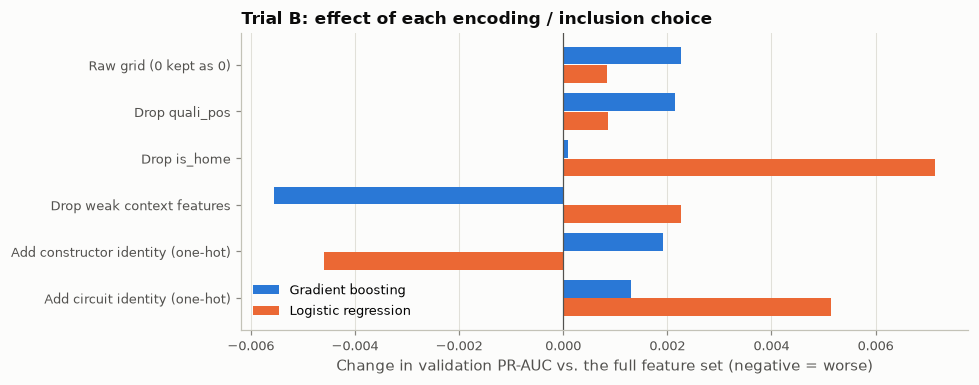

In [44]:
def with_onehot(col):
    """Full feature set plus one-hot identity columns; categories are taken from the training seasons only."""
    cats = sorted(train[col].unique())
    def expand(frame):
        dummies = pd.DataFrame({f"{col}_{c}": (frame[col] == c).astype(float).values for c in cats}, index=frame.index)
        return pd.concat([frame[FEATURES], dummies], axis=1)
    return expand(train), expand(val)

raw_grid_train = X_train.drop(columns=["grid_pos", "pit_lane_start"]).assign(grid_raw=np.where(X_train["pit_lane_start"] == 1, 0, X_train["grid_pos"]))
raw_grid_val = X_val.drop(columns=["grid_pos", "pit_lane_start"]).assign(grid_raw=np.where(X_val["pit_lane_start"] == 1, 0, X_val["grid_pos"]))
con_tr, con_va = with_onehot("constructorId")
cir_tr, cir_va = with_onehot("circuitId")
weak = ["field_size", "season_progress", "driver_age"]
variants = {
    "Full feature set (reference)": (X_train, X_val, FEATURES),
    "Raw grid (0 kept as 0)": (raw_grid_train, raw_grid_val, list(raw_grid_train.columns)),
    "Drop quali_pos": (X_train, X_val, [f for f in FEATURES if f != "quali_pos"]),
    "Drop is_home": (X_train, X_val, [f for f in FEATURES if f != "is_home"]),
    "Drop weak context features": (X_train, X_val, [f for f in FEATURES if f not in weak]),
    "Add constructor identity (one-hot)": (con_tr, con_va, list(con_tr.columns)),
    "Add circuit identity (one-hot)": (cir_tr, cir_va, list(cir_tr.columns)),
}
rows = []
for label, (xtr, xva, cols) in variants.items():
    for name, maker in [("Logistic regression", quick_lr), ("Gradient boosting", quick_gb)]:
        rows.append({"variant": label, "n_features": len(cols), "model": name, **val_scores(maker(), cols, xtr, xva)})
trial_b = pd.DataFrame(rows)
wide_b = trial_b.pivot(index="variant", columns="model", values="PR-AUC").loc[list(variants)]
delta_b = (wide_b - wide_b.iloc[0]).iloc[1:]
display(wide_b.round(4).assign(n_features=trial_b.drop_duplicates("variant").set_index("variant")["n_features"]))

fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(delta_b))
for i, (name, color) in enumerate(zip(delta_b.columns, SERIES)):
    ax.barh(y + (0.2 if i == 0 else -0.2), delta_b[name][::-1], height=0.38, color=color, label=name)
ax.axvline(0, color=C["ink2"], linewidth=0.8)
ax.set_yticks(y)
ax.set_yticklabels(delta_b.index[::-1], fontsize=8.5)
ax.set_xlabel("Change in validation PR-AUC vs. the full feature set (negative = worse)")
ax.set_title("Trial B: effect of each encoding / inclusion choice")
ax.legend(loc="lower left")
ax.grid(axis="y", visible=False)
savefig("features_trial_encoding")

**How to read these trials.** The validation set has 60 races and 180 podiums, so differences of a few thousandths in PR-AUC are within noise. Only changes that are clearly larger than that, or that agree across both model types, are treated as evidence.

**Decisions.**

- **Grid and qualifying carry most of the signal; team form and standings add a clear further gain** (Trial A). Later groups add less because they overlap with what is already included — which is what the correlation matrix predicted. Small *decreases* when a group is added on top are within noise for this sample size.
- **Team and circuit identity are not used.** One-hot identity columns add 30–40 columns for no reliable gain. More importantly, a team's *name* is not a stable signal across seasons — the same constructor can be dominant in one period and mid-field in another, and teams are renamed — whereas rolling form and standings describe how strong the team is *now*. They also cannot handle a team or circuit that is new in the test seasons.
- **`grid = 0` is recoded.** The recoded version is kept on the grounds of meaning (Section 4.5: these rows have a 0% podium rate, yet 0 sorts ahead of pole). The trial shows what difference this makes in practice; with under 1% of rows affected the measured effect is necessarily small.
- **`quali_pos`, `is_home` and the weak context features are kept.** Removing them does not give a consistent improvement across both models, so there is no evidence-based reason to drop them, and a single fixed feature set for all models is a milestone requirement. Their actual contribution is measured again, on the final tuned models, in the ablation (Section 12).

**Selected feature set: the 28 features in the six groups of Section 6.2.**

## 9. Pre-processing and order experiments

### 9.1 The pre-processing pipeline and its effect on the data

Two steps are applied, in this order, **inside a pipeline that is fitted on the training seasons only**:

1. **Median imputation.** Missing values are replaced by the feature's training-set median. The median is used instead of the mean because several features are heavily skewed (many drivers have a podium rate of exactly 0), so the mean would not be a typical value.
2. **Standardisation.** Each feature is rescaled to mean 0 and standard deviation 1 using training-set statistics. The features live on very different scales (`drv_career_starts` goes up to 400, rates lie between 0 and 1). Logistic regression with regularisation and the neural network both need comparable scales: otherwise the penalty and the gradient steps are dominated by the features with the largest numbers. Tree models are unaffected by scaling, but the same pipeline is used for all models so that they see identical inputs.

,missing before,missing after,min before,max before,mean before,std before,min after,max after,mean after,std after
grid_pos,0,0,1.00,24.00,11.25,6.27,-1.64,2.03,-0.0,1.0
pit_lane_start,0,0,0.00,1.00,0.00,0.05,-0.05,19.39,0.0,1.0
grid_drop,21,0,-7.00,23.00,0.01,1.56,-4.50,14.77,0.0,1.0
quali_pos,21,0,1.00,24.00,11.21,6.25,-1.64,2.05,0.0,1.0
quali_gap_pct,115,0,0.00,10.00,2.30,2.01,-1.15,3.87,0.0,1.0
mate_quali_gap_pct,223,0,-5.00,5.00,0.00,1.06,-4.81,4.80,0.0,1.0
team_best_gap_pct,27,0,0.00,10.00,1.97,1.87,-1.05,4.30,0.0,1.0
quali_missing,0,0,0.00,1.00,0.00,0.06,-0.06,17.44,0.0,1.0
drv_podium_rate_5,72,0,0.00,1.00,0.14,0.25,-0.56,3.43,0.0,1.0
drv_avg_finish_5,72,0,1.00,24.00,11.18,4.53,-2.26,2.84,0.0,1.0


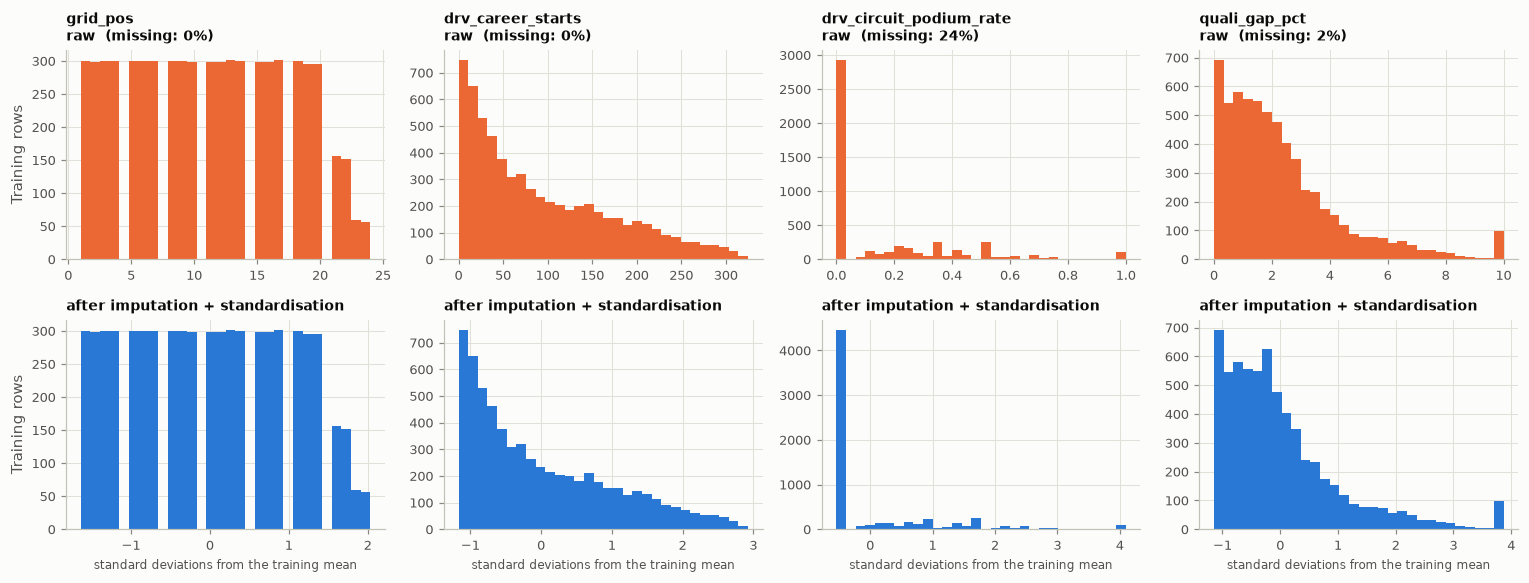

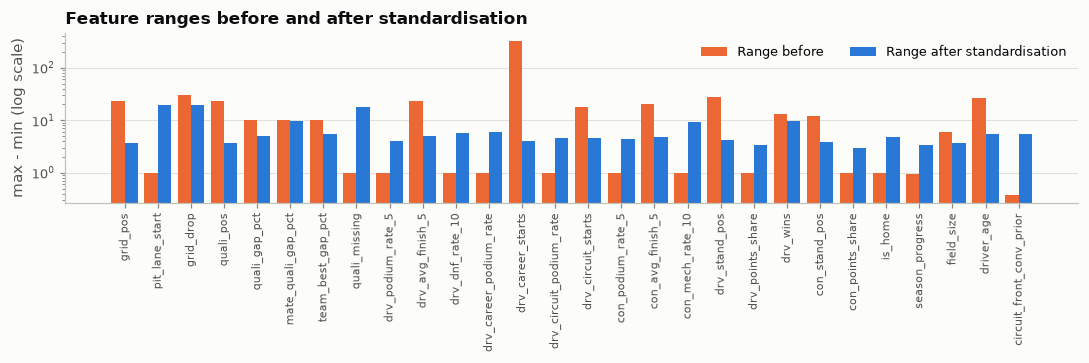

In [45]:
prep = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]).fit(X_train)
X_train_imp = pd.DataFrame(prep.named_steps["impute"].transform(X_train), columns=FEATURES)
X_train_std = pd.DataFrame(prep.transform(X_train), columns=FEATURES)

effect = pd.DataFrame({
    "missing before": X_train.isna().sum(), "missing after": X_train_std.isna().sum(),
    "min before": X_train.min(), "max before": X_train.max(), "mean before": X_train.mean(), "std before": X_train.std(),
    "min after": X_train_std.min(), "max after": X_train_std.max(), "mean after": X_train_std.mean(), "std after": X_train_std.std(),
})
display(effect.round(2))

show = ["grid_pos", "drv_career_starts", "drv_circuit_podium_rate", "quali_gap_pct"]
fig, axes = plt.subplots(2, 4, figsize=(14, 5.4))
for j, f in enumerate(show):
    axes[0, j].hist(X_train[f].dropna(), bins=30, color=C["orange"])
    axes[0, j].set_title(f"{f}\nraw  (missing: {X_train[f].isna().mean() * 100:.0f}%)", fontsize=9)
    axes[1, j].hist(X_train_std[f], bins=30, color=C["blue"])
    axes[1, j].set_title("after imputation + standardisation", fontsize=9)
    axes[1, j].set_xlabel("standard deviations from the training mean", fontsize=8)
axes[0, 0].set_ylabel("Training rows")
axes[1, 0].set_ylabel("Training rows")
savefig("preprocessing_effect")

fig, ax = plt.subplots(figsize=(10, 3.4))
rng_before = (X_train.max() - X_train.min()).replace(0, np.nan)
rng_after = (X_train_std.max() - X_train_std.min())
x = np.arange(len(FEATURES))
ax.bar(x - 0.2, rng_before, width=0.4, color=C["orange"], label="Range before")
ax.bar(x + 0.2, rng_after, width=0.4, color=C["blue"], label="Range after standardisation")
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(FEATURES, rotation=90, fontsize=7.5)
ax.set_ylabel("max - min (log scale)")
ax.set_title("Feature ranges before and after standardisation")
ax.legend(ncol=2)
ax.grid(axis="x", visible=False)
savefig("preprocessing_ranges")

**Effect of the steps.**

- **Missing values:** all removed. The imputed rows appear as a single tall bar at the median (most visible for `drv_circuit_podium_rate`, where about a fifth of the rows are first visits to a circuit).
- **Range and scale:** before, feature ranges span three orders of magnitude (from 1 to about 400); after, all features are on a comparable scale of a few standard deviations, with mean 0 and standard deviation 1.
- **Shape:** standardisation is a shift and a rescale, so it does **not** change the shape of a distribution. Skewed features stay skewed. This is one more reason to include non-linear models.

**Alternatives tried.** The table below compares imputation and scaling variants on validation.

In [46]:
from sklearn.preprocessing import FunctionTransformer, RobustScaler

def pipe_variant(imputer, scaler, model):
    steps = [("impute", imputer)] + ([("scale", scaler)] if scaler is not None else []) + [("model", model)]
    return Pipeline(steps)

lr = lambda: LogisticRegression(C=1.0, max_iter=5000)
gb = lambda: HistGradientBoostingClassifier(max_iter=150, learning_rate=0.05, max_depth=3, early_stopping=False, random_state=SEED)
prep_variants = {
    "Median impute + standardise (chosen)": lambda m: pipe_variant(SimpleImputer(strategy="median"), StandardScaler(), m),
    "Mean impute + standardise": lambda m: pipe_variant(SimpleImputer(strategy="mean"), StandardScaler(), m),
    "Median impute + missing flags + standardise": lambda m: pipe_variant(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), m),
    "Median impute + robust scaling": lambda m: pipe_variant(SimpleImputer(strategy="median"), RobustScaler(), m),
    "Median impute, no scaling": lambda m: pipe_variant(SimpleImputer(strategy="median"), None, m),
}
rows = []
for label, maker in prep_variants.items():
    for name, model in [("Logistic regression", lr), ("Gradient boosting", gb)]:
        rows.append({"pre-processing": label, "model": name, **val_scores(maker(model()), FEATURES)})
prep_trials = pd.DataFrame(rows).pivot(index="pre-processing", columns="model", values=["PR-AUC", "ROC-AUC"]).loc[list(prep_variants)]
display(prep_trials.round(4))

PR-AUC                               ROC-AUC                    
model                                       Gradient boosting Logistic regression Gradient boosting Logistic regression
pre-processing                                                                                                         
Median impute + standardise (chosen)                   0.7450              0.7247            0.9389              0.9309
Mean impute + standardise                              0.7426              0.7257            0.9387              0.9313
Median impute + missing flags + standardise            0.7458              0.7289            0.9390              0.9365
Median impute + robust scaling                         0.7450              0.7259            0.9389              0.9306
Median impute, no scaling                              0.7450              0.7267            0.9389              0.9307

**Reading the table.** The variants differ very little: gradient boosting is unaffected by the choice of scaler (as expected for trees), and logistic regression changes only in the third decimal place. Automatic missing-value flags do not add a reliable gain, because the feature set already contains explicit "why is it missing" features (`quali_missing`, `drv_career_starts`, `drv_circuit_starts`). The simple, standard choice — median imputation followed by standardisation — is therefore kept; nothing more complicated is justified by the evidence.

### 9.2 Pre-processing-order experiments

The *order* of pipeline steps can matter as much as the steps themselves. Three order questions are tested. Each compares two orders on the same validation seasons.

| # | Order question | Order A (used) | Order B (alternative) |
|---|---|---|---|
| 1 | Split vs. fitting the pre-processing | Split first, then fit imputer and scaler on **train only** | Fit imputer and scaler on **all rows**, then split |
| 2 | Split vs. feature engineering | Build form features on the **full history**, then split | Split first, then build form features **inside each split** |
| 3 | Imputation vs. scaling | **Impute → scale** | **Scale → impute** |

Experiment 1: fitting on all rows moves the scaler means by at most 0.264 training standard deviations (field_size).
Experiment 2: share of validation rows whose value changes when history restarts at the split boundary:
   circuit_front_conv_prior 100%, drv_career_starts 78%, drv_career_podium_rate 66%, drv_circuit_starts 61%, drv_circuit_podium_rate 47%, con_mech_rate_10 13%
Experiment 3: largest difference between the two orders in any transformed value: 0.501 (drv_circuit_podium_rate).


PR-AUC                               ROC-AUC                    
model                                                                      Gradient boosting Logistic regression Gradient boosting Logistic regression
experiment                       order                                                                                                                
1. Split vs. fit pre-processing  A: split, then fit on train only                     0.7450              0.7247            0.9389              0.9309
                                 B: fit on all rows, then split                       0.7483              0.7255            0.9381              0.9308
2. Split vs. feature engineering A: engineer on full history, then split              0.7450              0.7247            0.9389              0.9309
                                 B: split, then engineer inside each split            0.7452              0.7209            0.9368              0.9293
3. Impute vs. scale              A: impute, then scale                                0.7450              0.7247            0.9389              0.9309
                                 B: scale, then impute                                0.7450              0.7249            0.9389              0.9308

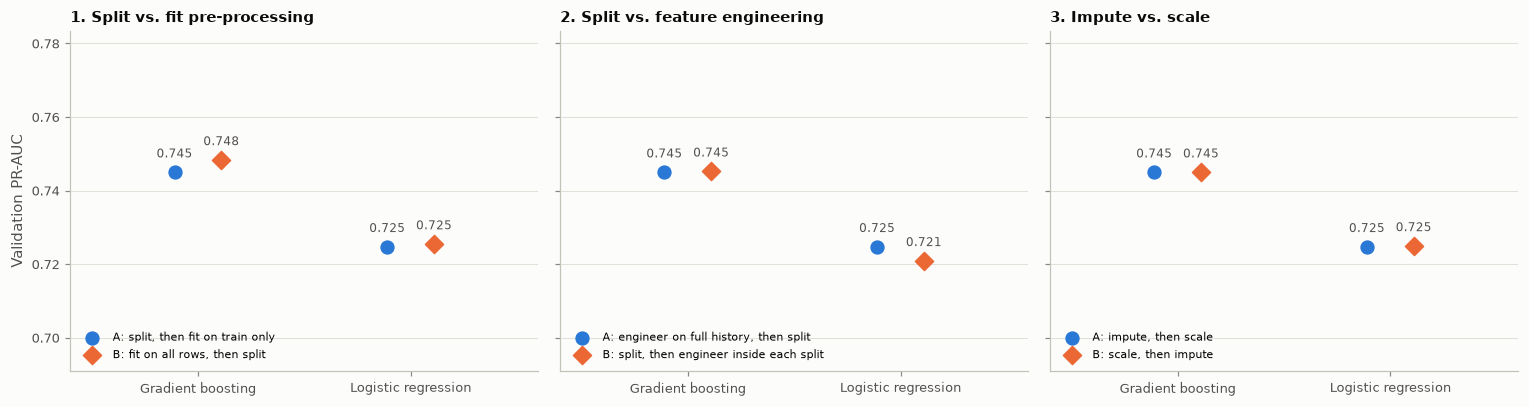

In [47]:
def scores_on_val(model, Xtr, Xva):
    model.fit(Xtr, y_train)
    p = model.predict_proba(Xva)[:, 1]
    return average_precision_score(y_val, p), roc_auc_score(y_val, p)

order_rows = []
def record(experiment, order_label, Xtr, Xva):
    for name, model in [("Logistic regression", lr()), ("Gradient boosting", gb())]:
        pr, roc = scores_on_val(model, Xtr, Xva)
        order_rows.append({"experiment": experiment, "order": order_label, "model": name, "PR-AUC": pr, "ROC-AUC": roc})

# ---- Experiment 1: split -> fit pre-processing (train only)   vs.   fit pre-processing on everything -> split
p_train_only = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]).fit(X_train)
p_all_rows = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]).fit(table[FEATURES])
record("1. Split vs. fit pre-processing", "A: split, then fit on train only", p_train_only.transform(X_train), p_train_only.transform(X_val))
record("1. Split vs. fit pre-processing", "B: fit on all rows, then split", p_all_rows.transform(X_train), p_all_rows.transform(X_val))
shift = np.abs(p_all_rows.named_steps["scale"].mean_ - p_train_only.named_steps["scale"].mean_) / p_train_only.named_steps["scale"].scale_
print(f"Experiment 1: fitting on all rows moves the scaler means by at most {shift.max():.3f} training standard deviations ({FEATURES[int(shift.argmax())]}).")

# ---- Experiment 2: engineer features on full history -> split   vs.   split -> engineer inside each split
def features_within(first_year, last_year):
    """Form features computed using ONLY the seasons of one split: history restarts at the split boundary."""
    race_ids = set(CLEAN["races"].loc[CLEAN["races"]["year"].between(first_year, last_year), "raceId"])
    tables = dict(SOURCE,
                  results_tbl=results_clean[results_clean["raceId"].isin(race_ids)],
                  qualifying_tbl=CLEAN["qualifying"][CLEAN["qualifying"]["raceId"].isin(race_ids)],
                  driver_standings_tbl=CLEAN["driver_standings"][CLEAN["driver_standings"]["raceId"].isin(race_ids)],
                  constructor_standings_tbl=CLEAN["constructor_standings"][CLEAN["constructor_standings"]["raceId"].isin(race_ids)])
    return build_features(**tables)

train_b = features_within(*SPLIT["train"]).merge(train[["raceId", "driverId"]], on=["raceId", "driverId"])
val_b = features_within(*SPLIT["val"]).merge(val[["raceId", "driverId"]], on=["raceId", "driverId"])
assert (train_b[["raceId", "driverId"]].values == train[["raceId", "driverId"]].values).all()
assert (val_b[["raceId", "driverId"]].values == val[["raceId", "driverId"]].values).all()
pa = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]).fit(X_train)
pb = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]).fit(train_b[FEATURES].astype(float))
record("2. Split vs. feature engineering", "A: engineer on full history, then split", pa.transform(X_train), pa.transform(X_val))
record("2. Split vs. feature engineering", "B: split, then engineer inside each split", pb.transform(train_b[FEATURES].astype(float)), pb.transform(val_b[FEATURES].astype(float)))
changed = (~np.isclose(val_b[FEATURES].astype(float), X_val, equal_nan=True)).mean(axis=0)
changed = pd.Series(changed, index=FEATURES).sort_values(ascending=False)
print("Experiment 2: share of validation rows whose value changes when history restarts at the split boundary:")
print("   " + ", ".join(f"{f} {v * 100:.0f}%" for f, v in changed.head(6).items()))

# ---- Experiment 3: impute -> scale   vs.   scale -> impute
imp_then_scale = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]).fit(X_train)
scale_then_imp = Pipeline([("scale", StandardScaler()), ("impute", SimpleImputer(strategy="median"))]).fit(X_train)
record("3. Impute vs. scale", "A: impute, then scale", imp_then_scale.transform(X_train), imp_then_scale.transform(X_val))
record("3. Impute vs. scale", "B: scale, then impute", scale_then_imp.transform(X_train), scale_then_imp.transform(X_val))
gap = np.abs(imp_then_scale.transform(X_train) - scale_then_imp.transform(X_train)).max(axis=0)
print(f"Experiment 3: largest difference between the two orders in any transformed value: {gap.max():.3f} ({FEATURES[int(gap.argmax())]}).")

order_results = pd.DataFrame(order_rows)
order_table = order_results.pivot(index=["experiment", "order"], columns="model", values=["PR-AUC", "ROC-AUC"])
display(order_table.round(4))
order_results.to_csv(os.path.join(OUT_DIR, "preprocessing_order_experiments.csv"), index=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (exp, g) in zip(axes, order_results.groupby("experiment")):
    w = g.pivot(index="model", columns="order", values="PR-AUC")
    w = w[sorted(w.columns)]
    x = np.arange(len(w))
    for i, (col, color, marker) in enumerate(zip(w.columns, [C["blue"], C["orange"]], ["o", "D"])):
        ax.scatter(x + (i - 0.5) * 0.22, w[col], s=70, color=color, marker=marker, label=col, zorder=3)
        for xx, v in zip(x + (i - 0.5) * 0.22, w[col]):
            ax.text(xx, v + 0.004, f"{v:.3f}", ha="center", fontsize=8, color=C["ink2"])
    ax.set_xticks(x)
    ax.set_xticklabels(w.index, fontsize=8.5)
    ax.set_xlim(-0.6, len(w) - 0.4)
    ax.set_ylim(order_results["PR-AUC"].min() - 0.03, order_results["PR-AUC"].max() + 0.035)
    ax.set_title(exp, fontsize=9.5)
    ax.legend(fontsize=7.5, loc="lower left")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Validation PR-AUC")
savefig("preprocessing_order_experiments")

In [48]:
def order_delta(exp, model):
    g = order_results[(order_results["experiment"] == exp) & (order_results["model"] == model)].sort_values("order")
    return g["PR-AUC"].iloc[1] - g["PR-AUC"].iloc[0]
e1, e2, e3 = (sorted(order_results["experiment"].unique())[i] for i in range(3))
md(f"""
**Results of the order experiments** (change in validation PR-AUC when moving from order A to order B)

| Experiment | Logistic regression | Gradient boosting |
|---|---|---|
| 1. Fit pre-processing on all rows instead of train only | {order_delta(e1, 'Logistic regression'):+.4f} | {order_delta(e1, 'Gradient boosting'):+.4f} |
| 2. Engineer features inside each split instead of on full history | {order_delta(e2, 'Logistic regression'):+.4f} | {order_delta(e2, 'Gradient boosting'):+.4f} |
| 3. Scale then impute instead of impute then scale | {order_delta(e3, 'Logistic regression'):+.4f} | {order_delta(e3, 'Gradient boosting'):+.4f} |
""")


**Results of the order experiments** (change in validation PR-AUC when moving from order A to order B)

| Experiment | Logistic regression | Gradient boosting |
|---|---|---|
| 1. Fit pre-processing on all rows instead of train only | +0.0007 | +0.0033 |
| 2. Engineer features inside each split instead of on full history | -0.0038 | +0.0002 |
| 3. Scale then impute instead of impute then scale | +0.0002 | +0.0000 |


**Interpretation.** With 60 validation races, differences below about 0.01 PR-AUC cannot be told apart from noise. None of the three order changes produces a difference clearly larger than that, in either direction. The orders are therefore chosen on correctness, and the experiments show what each choice costs or risks.

1. **Split before fitting the pre-processing.** Fitting the imputer and scaler on all rows lets validation and test statistics into training. The printed check shows this is not a no-op — a scaler mean moves by a quarter of a standard deviation (`field_size`, because recent seasons have 20 cars) — but the scores barely move, because a shifted mean changes the model's inputs by a constant that the model absorbs. The order is fixed as *split first* on principle: the leak is real even when its effect is small, it would grow with any step that uses the target, and avoiding it costs nothing.
2. **Feature engineering before the split.** If form features are built inside each split, every split starts with no memory: at the first validation race every driver looks like a rookie and the standings carried over from the previous season are gone. The printed check shows that career and circuit-history features change for most validation rows. The effect on the scores is nevertheless small, for a reason that is itself informative: the features that are damaged (career totals, circuit history) are the weak ones, while the strong ones (grid, qualifying, five-race form, in-season standings) either do not depend on history or rebuild within a few races. Building on the full chronological history and *then* splitting is kept because it is the correct description of what is known at race time, and it is leakage-safe since every feature only looks backwards (tested in Section 6.3). The general lesson: "split first" is not a universal rule — what matters is that no step uses information from the future of the row it computes.
3. **Impute before scaling.** The two orders give different transformed values for features with many missing entries (scaling first computes the standard deviation from observed values only; imputing first adds a block of identical medians and shrinks it), but the scores are unchanged. *Impute → scale* is kept because it is the conventional order and leaves every feature with exactly unit variance.

## 10. Models

All models are trained on the **same rows** (the training seasons of the modeling table) with the **same 28 features** and the same pre-processing, so their scores are directly comparable.

| Model | Role |
|---|---|
| Grid-frequency rule | Reference with no machine learning: "how often did this grid slot reach the podium in the past?" |
| Logistic regression | **Statistical baseline** — the simplest reasonable model |
| Random forest | Statistical model 2 |
| Gradient boosting | Statistical model 3 |
| Shallow neural network | 1–2 hidden layers, PyTorch |

### 10.1 Metrics and decision threshold

| Metric | What it tells us here | Role |
|---|---|---|
| **PR-AUC** (average precision) | How well the model ranks real podium finishers above the rest, focusing on the rare positive class | **Primary** |
| **F1** at a chosen threshold | Balance of precision and recall once probabilities are turned into yes/no predictions | **Secondary** |
| ROC-AUC | Overall separation of the two classes | Reported |
| Precision, Recall | The two components of F1: "of the predicted podiums, how many were right" / "of the real podiums, how many were found" | Reported |
| Brier score, Accuracy | Quality of the probabilities; share of correct yes/no predictions | Reported for completeness |

**Why PR-AUC is the primary metric.** Only about 15% of rows are podiums. ROC-AUC rewards a model for correctly ranking the ~85% of easy negatives (cars at the back of the grid almost never reach the podium), so every reasonable model scores above 0.9 and differences are compressed. PR-AUC ignores true negatives and measures what matters for this task: when the model says "podium", is it right, and does it find the real ones? A random model scores about 0.15 on PR-AUC (the positive share), so the scale is honest. PR-AUC also does not depend on a threshold, which makes it suitable for selecting hyperparameters.

**Why F1 is the secondary metric.** A user needs a decision, not only a ranking. F1 summarises the quality of the yes/no predictions without being inflated by the majority class, unlike accuracy — a model that always answers "no podium" has 85% accuracy and an F1 of 0.

**Threshold.** For each model the probability threshold is the one that maximises F1 **on the validation seasons**. It is then frozen and applied to the test seasons. The default 0.5 is not used because, with a rare positive class, the F1-optimal threshold is usually lower.

In [49]:
import torch
import torch.nn as nn

torch.manual_seed(SEED)
torch.set_num_threads(1)                     # single thread keeps the small network reproducible

def best_f1_threshold(y_true, p):
    precision, recall, thresholds = precision_recall_curve(y_true, p)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    return float(thresholds[int(np.argmax(f1))])

def all_metrics(y_true, p, threshold):
    pred = (p >= threshold).astype(int)
    return {"ROC-AUC": roc_auc_score(y_true, p), "PR-AUC": average_precision_score(y_true, p),
            "F1": f1_score(y_true, pred, zero_division=0), "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0), "Brier": brier_score_loss(y_true, p),
            "Accuracy": accuracy_score(y_true, pred)}

class ShallowNet:
    """Feed-forward network with 1-2 hidden layers. Trained with Adam; early stopping on validation loss."""
    def __init__(self, hidden=(64, 32), dropout=0.2, lr=1e-3, weight_decay=1e-4, batch_size=64, max_epochs=150, patience=15, seed=SEED):
        self.hidden, self.dropout, self.lr, self.weight_decay = tuple(hidden), dropout, lr, weight_decay
        self.batch_size, self.max_epochs, self.patience, self.seed = batch_size, max_epochs, patience, seed

    def _build(self, n_inputs):
        layers, width = [], n_inputs
        for h in self.hidden:
            layers += [nn.Linear(width, h), nn.ReLU(), nn.Dropout(self.dropout)]
            width = h
        layers.append(nn.Linear(width, 1))                    # one output: the log-odds of a podium
        return nn.Sequential(*layers)

    def fit(self, X, y, X_val=None, y_val=None):
        torch.manual_seed(self.seed)
        rng = np.random.default_rng(self.seed)
        X_t, y_t = torch.tensor(np.asarray(X), dtype=torch.float32), torch.tensor(np.asarray(y), dtype=torch.float32)
        has_val = X_val is not None
        if has_val:
            Xv_t, yv_t = torch.tensor(np.asarray(X_val), dtype=torch.float32), torch.tensor(np.asarray(y_val), dtype=torch.float32)
        self.net = self._build(X_t.shape[1])
        optimiser = torch.optim.Adam(self.net.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        loss_fn = nn.BCEWithLogitsLoss()
        self.history, best_loss, best_state, waited = [], np.inf, None, 0
        for epoch in range(self.max_epochs):
            self.net.train()
            order = rng.permutation(len(X_t))
            for start in range(0, len(order), self.batch_size):
                idx = order[start:start + self.batch_size]
                optimiser.zero_grad()
                loss_fn(self.net(X_t[idx]).squeeze(1), y_t[idx]).backward()
                optimiser.step()
            self.net.eval()
            with torch.no_grad():
                record = {"epoch": epoch + 1, "train_loss": loss_fn(self.net(X_t).squeeze(1), y_t).item()}
                if has_val:
                    record["val_loss"] = loss_fn(self.net(Xv_t).squeeze(1), yv_t).item()
            self.history.append(record)
            if has_val:
                if record["val_loss"] < best_loss - 1e-5:
                    best_loss, waited = record["val_loss"], 0
                    best_state = {k: v.clone() for k, v in self.net.state_dict().items()}
                else:
                    waited += 1
                    if waited >= self.patience:
                        break
        if best_state is not None:
            self.net.load_state_dict(best_state)                # roll back to the best validation epoch
        self.best_epoch = int(np.argmin([h["val_loss"] for h in self.history])) + 1 if has_val else len(self.history)
        self.net.eval()
        return self

    def predict_proba(self, X):
        with torch.no_grad():
            p = torch.sigmoid(self.net(torch.tensor(np.asarray(X), dtype=torch.float32)).squeeze(1)).numpy()
        return np.column_stack([1 - p, p])

class PodiumModel:
    """Median imputation -> standardisation -> classifier. Pre-processing is fitted on the training data given to .fit()."""
    def __init__(self, estimator, cols=None, name=""):
        self.estimator, self.cols, self.name = estimator, list(cols or FEATURES), name

    def fit(self, X, y, X_val=None, y_val=None):
        self.prep = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]).fit(X[self.cols])
        Z = self.prep.transform(X[self.cols])
        if isinstance(self.estimator, ShallowNet):
            self.estimator.fit(Z, y, self.prep.transform(X_val[self.cols]), y_val)   # validation data only decides when to stop
        else:
            self.estimator.fit(Z, y)
        return self

    def transform(self, X):
        X = X if isinstance(X, pd.DataFrame) else pd.DataFrame(np.asarray(X), columns=self.cols)
        return self.prep.transform(X[self.cols])

    def predict_proba(self, X):
        return self.estimator.predict_proba(self.transform(X))

    def proba(self, X):
        return self.predict_proba(X)[:, 1]

TRIALS = []          # every modelling attempt is logged here
def log_trial(model_name, params, model):
    p_tr, p_va = model.proba(X_train), model.proba(X_val)
    TRIALS.append({"model": model_name, "params": params, "train PR-AUC": average_precision_score(y_train, p_tr),
                   "val PR-AUC": average_precision_score(y_val, p_va), "val ROC-AUC": roc_auc_score(y_val, p_va)})
    return TRIALS[-1]["val PR-AUC"]

### 10.2 Reference points: a rule with no machine learning, and the statistical baseline

**Grid-frequency rule.** For each grid slot, the predicted probability is the share of drivers who reached the podium from that slot in the training seasons. This uses one feature and no learning algorithm. Any model has to beat it to justify its complexity.

**Logistic regression (baseline).** *How it works:* it computes a weighted sum of the standardised features and passes it through the logistic (S-shaped) function to obtain a probability. The weights are chosen to maximise the likelihood of the training labels, with an L2 penalty (strength `1/C`) that shrinks weights towards zero to limit over-fitting. Each weight has a direct reading: the change in the log-odds of a podium per one standard deviation of the feature, other features held fixed.

*Limitations for this task:* (1) each feature acts linearly on the log-odds, while Section 8.2 showed strongly curved relationships; (2) it has no interactions unless we add them — it cannot learn, for example, that team form matters more for a driver starting at the front; (3) with highly correlated features (Section 8.3) the individual weights are unstable and should not be over-interpreted; (4) it scores each row independently and does not know that exactly three drivers per race are positive. The last point applies to every model in this notebook.

In [50]:
class GridFrequencyRule:
    """Non-ML reference: historical podium rate of the grid slot."""
    def fit(self, X, y):
        slot = X["grid_pos"].round().astype(int)
        self.rate = pd.Series(y).groupby(slot.values).mean()
        return self
    def proba(self, X):
        return X["grid_pos"].round().astype(int).map(self.rate).fillna(0.0).values

grid_rule = GridFrequencyRule().fit(X_train, y_train)
MODELS = {"Grid-frequency rule (no ML)": grid_rule}

baseline_lr = PodiumModel(LogisticRegression(C=1.0, max_iter=5000), name="Logistic regression (baseline)").fit(X_train, y_train)
log_trial("Logistic regression", "C=1.0 (default, baseline)", baseline_lr)
MODELS["Logistic regression (baseline, default)"] = baseline_lr

for name in MODELS:
    p = MODELS[name].proba(X_val)
    print(f"{name:42s} validation PR-AUC {average_precision_score(y_val, p):.4f}   ROC-AUC {roc_auc_score(y_val, p):.4f}")

Grid-frequency rule (no ML)                validation PR-AUC 0.6775   ROC-AUC 0.9217
Logistic regression (baseline, default)    validation PR-AUC 0.7247   ROC-AUC 0.9309


### 10.3 Logistic regression — tuned

Two settings are varied: the regularisation strength `C` (smaller = stronger penalty) and whether the classes are re-weighted (`class_weight="balanced"` makes the rare podium rows count more). Every combination is trained on the training seasons and scored on the validation seasons.

Selected on validation: {'C': 10.0, 'class_weight': None} -> val PR-AUC 0.7268


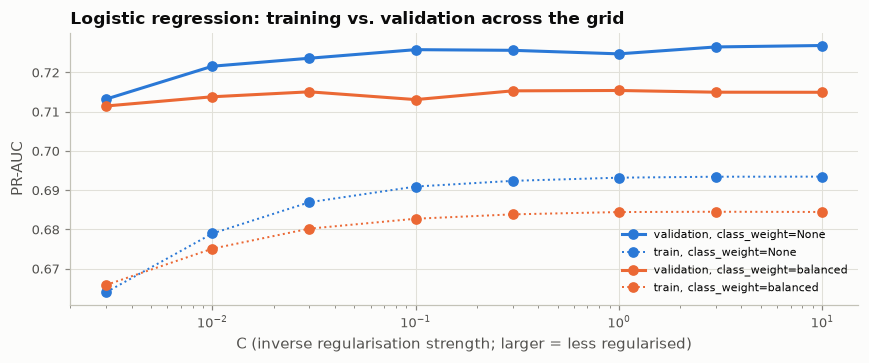

In [51]:
rows = []
for cw in [None, "balanced"]:
    for c in [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]:
        m = PodiumModel(LogisticRegression(C=c, class_weight=cw, max_iter=5000)).fit(X_train, y_train)
        score = log_trial("Logistic regression", f"C={c}, class_weight={cw}", m)
        rows.append({"C": c, "class_weight": str(cw), "train PR-AUC": TRIALS[-1]["train PR-AUC"], "val PR-AUC": score, "model": m})
lr_grid = pd.DataFrame(rows)
best = lr_grid.loc[lr_grid["val PR-AUC"].idxmax()]
LR_PARAMS = {"C": float(best["C"]), "class_weight": None if best["class_weight"] == "None" else "balanced"}
MODELS["Logistic regression (tuned)"] = best["model"]
print("Selected on validation:", LR_PARAMS, f"-> val PR-AUC {best['val PR-AUC']:.4f}")

fig, ax = plt.subplots(figsize=(8, 3.4))
for (cw, g), color in zip(lr_grid.groupby("class_weight"), SERIES):
    ax.plot(g["C"], g["val PR-AUC"], marker="o", color=color, label=f"validation, class_weight={cw}")
    ax.plot(g["C"], g["train PR-AUC"], marker="o", color=color, linestyle=":", linewidth=1.3, label=f"train, class_weight={cw}")
ax.set_xscale("log")
ax.set_xlabel("C (inverse regularisation strength; larger = less regularised)")
ax.set_ylabel("PR-AUC")
ax.set_title("Logistic regression: training vs. validation across the grid")
ax.legend(fontsize=7.5)
savefig("model_lr_tuning")

### 10.4 Random forest

*How it works:* it grows several hundred decision trees. Each tree is trained on a random resample of the training rows and, at every split, may only choose among a random subset of the features. A tree splits the data by thresholds (`grid_pos <= 3?`), so it handles curved relationships and interactions naturally. The forest's probability is the average over all trees; averaging many de-correlated trees reduces the variance of a single tree.

*Limitations for this task:* (1) a forest cannot extrapolate — it can only output averages of training outcomes, which matters when a new era produces feature combinations it has not seen; (2) probabilities are averaged votes and tend to be pulled away from 0 and 1; (3) with correlated features the importance is split arbitrarily between them; (4) it is far less transparent than a linear model, hence Section 13.

*Tuned:* tree depth (`max_depth`) and the minimum number of rows in a leaf (`min_samples_leaf`). Both limit how finely a tree may cut the data; larger leaves give smoother, less over-fitted probabilities.

Selected on validation: {'max_depth': 8, 'min_samples_leaf': 5} -> val PR-AUC 0.7500


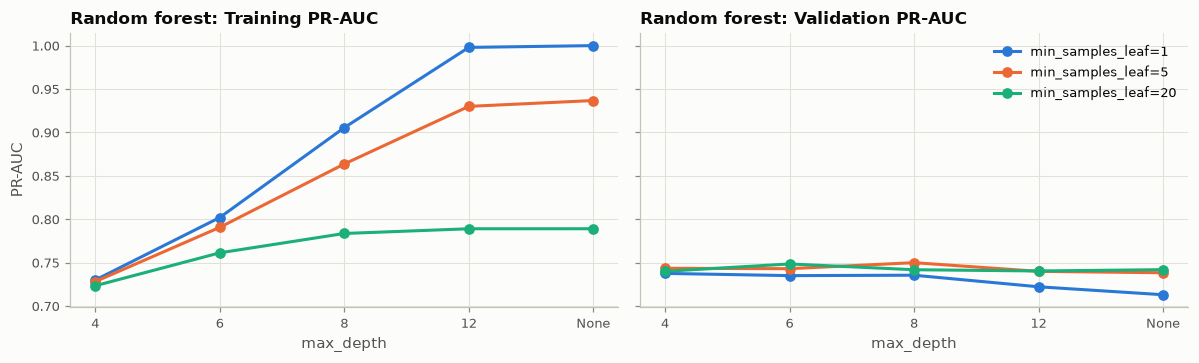

In [52]:
rows = []
for depth in [4, 6, 8, 12, None]:
    for leaf in [1, 5, 20]:
        est = RandomForestClassifier(n_estimators=300, max_depth=depth, min_samples_leaf=leaf, max_features="sqrt", n_jobs=-1, random_state=SEED)
        m = PodiumModel(est).fit(X_train, y_train)
        score = log_trial("Random forest", f"max_depth={depth}, min_samples_leaf={leaf}", m)
        rows.append({"max_depth": "None" if depth is None else str(depth), "min_samples_leaf": leaf, "train PR-AUC": TRIALS[-1]["train PR-AUC"], "val PR-AUC": score, "model": m})
rf_grid = pd.DataFrame(rows)
best = rf_grid.loc[rf_grid["val PR-AUC"].idxmax()]
RF_PARAMS = {"max_depth": None if best["max_depth"] == "None" else int(best["max_depth"]), "min_samples_leaf": int(best["min_samples_leaf"])}
MODELS["Random forest"] = best["model"]
print("Selected on validation:", RF_PARAMS, f"-> val PR-AUC {best['val PR-AUC']:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, col, title in zip(axes, ["train PR-AUC", "val PR-AUC"], ["Training", "Validation"]):
    for (leaf, g), color in zip(rf_grid.groupby("min_samples_leaf"), SERIES):
        ax.plot(g["max_depth"], g[col], marker="o", color=color, label=f"min_samples_leaf={leaf}")
    ax.set_xlabel("max_depth")
    ax.set_title(f"Random forest: {title} PR-AUC")
axes[0].set_ylabel("PR-AUC")
axes[1].legend()
savefig("model_rf_tuning")

The left panel shows the forest memorising the training data as trees get deeper and leaves smaller (training PR-AUC approaches 1), while the right panel shows that validation performance does not follow. The gap between the two is over-fitting; the selected setting is the one with the best *validation* score.

### 10.5 Gradient boosting

*How it works:* trees are built one after another. Each new, small tree is fitted to the errors (gradients of the log-loss) left by the trees so far, and its contribution is scaled down by the learning rate. The final score is the sum over all trees, converted to a probability. Where a forest reduces variance by averaging independent trees, boosting reduces bias by correcting mistakes step by step. The histogram-based implementation bins each feature first, which makes training fast.

*Limitations for this task:* (1) it over-fits if run for too many rounds, so the number of trees must be chosen on validation data; (2) it is sensitive to its settings (learning rate, depth); (3) like the forest it cannot extrapolate beyond the training range and is not directly interpretable.

*Tuned:* learning rate, tree depth, L2 regularisation, and the number of boosting rounds. For each setting the validation loss is tracked after every round, and the round with the lowest validation loss is kept.

Selected on validation: {'learning_rate': 0.1, 'max_depth': 4, 'l2_regularization': 1.0, 'max_iter': 40} -> val PR-AUC 0.7553


,learning_rate,max_depth,l2,rounds,train PR-AUC,val PR-AUC
0,0.10,4,1.0,40,0.7756,0.7553
1,0.03,3,1.0,214,0.7651,0.7515
2,0.10,4,0.0,38,0.7784,0.7513
3,0.03,2,0.0,203,0.7296,0.7504
4,0.10,3,1.0,42,0.7415,0.7498
5,0.03,3,0.0,205,0.7640,0.7488
6,0.03,2,1.0,255,0.7360,0.7477
7,0.10,2,0.0,95,0.7430,0.7475
8,0.03,4,0.0,148,0.7868,0.7468
9,0.10,3,0.0,61,0.7629,0.7459


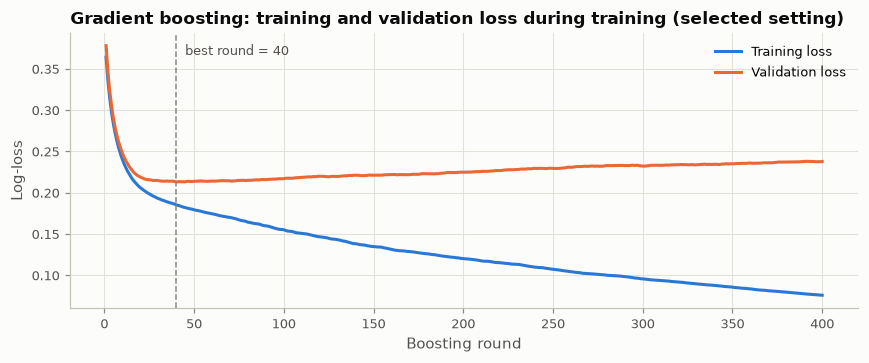

In [53]:
def gb_curves(est, Z_tr, Z_va):
    """Log-loss on train and validation after every boosting round."""
    tr = [log_loss(y_train, p[:, 1]) for p in est.staged_predict_proba(Z_tr)]
    va = [log_loss(y_val, p[:, 1]) for p in est.staged_predict_proba(Z_va)]
    return np.array(tr), np.array(va)

MAX_ROUNDS = 400
rows, gb_history = [], {}
for lrate in [0.03, 0.1]:
    for depth in [2, 3, 4]:
        for l2 in [0.0, 1.0]:
            probe = PodiumModel(HistGradientBoostingClassifier(max_iter=MAX_ROUNDS, learning_rate=lrate, max_depth=depth, l2_regularization=l2,
                                                               early_stopping=False, random_state=SEED)).fit(X_train, y_train)
            tr, va = gb_curves(probe.estimator, probe.transform(X_train), probe.transform(X_val))
            n_best = int(np.argmin(va)) + 1
            m = PodiumModel(HistGradientBoostingClassifier(max_iter=n_best, learning_rate=lrate, max_depth=depth, l2_regularization=l2,
                                                           early_stopping=False, random_state=SEED)).fit(X_train, y_train)
            score = log_trial("Gradient boosting", f"learning_rate={lrate}, max_depth={depth}, l2={l2}, rounds={n_best}", m)
            key = (lrate, depth, l2)
            gb_history[key] = (tr, va)
            rows.append({"learning_rate": lrate, "max_depth": depth, "l2": l2, "rounds": n_best, "train PR-AUC": TRIALS[-1]["train PR-AUC"], "val PR-AUC": score, "model": m, "key": key})
gb_grid = pd.DataFrame(rows)
best = gb_grid.loc[gb_grid["val PR-AUC"].idxmax()]
GB_PARAMS = {"learning_rate": float(best["learning_rate"]), "max_depth": int(best["max_depth"]), "l2_regularization": float(best["l2"]), "max_iter": int(best["rounds"])}
MODELS["Gradient boosting"] = best["model"]
print("Selected on validation:", GB_PARAMS, f"-> val PR-AUC {best['val PR-AUC']:.4f}")
display(gb_grid.drop(columns=["model", "key"]).sort_values("val PR-AUC", ascending=False).round(4).reset_index(drop=True))

tr, va = gb_history[best["key"]]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(range(1, len(tr) + 1), tr, color=C["blue"], label="Training loss")
ax.plot(range(1, len(va) + 1), va, color=C["orange"], label="Validation loss")
ax.axvline(best["rounds"], color=C["muted"], linestyle="--", linewidth=1)
ax.text(best["rounds"] + 5, max(va) * 0.97, f"best round = {int(best['rounds'])}", fontsize=8.5, color=C["ink2"])
ax.set_xlabel("Boosting round")
ax.set_ylabel("Log-loss")
ax.set_title("Gradient boosting: training and validation loss during training (selected setting)")
ax.legend()
savefig("model_gb_training")

The training loss keeps falling with every round, while the validation loss reaches a minimum and then rises: beyond that point the model is fitting noise in the training seasons. The model is stopped at the validation minimum.

### 10.6 Shallow neural network

*Architecture.* A feed-forward network: 28 inputs → one or two hidden layers with ReLU activation and dropout → one output unit whose sigmoid is the podium probability. "Shallow" means at most two hidden layers.

*How it works:* each hidden unit computes a weighted sum of its inputs and applies ReLU (`max(0, x)`), which lets the network bend straight lines into curves and combine features. The weights are learned by gradient descent (Adam optimiser) on the binary cross-entropy loss, in mini-batches of 64 rows.

*Regularisation — three mechanisms, because the data set is small (about 6,400 training rows) for a neural network:* **dropout** randomly switches off hidden units during training so the network cannot rely on any single unit; **weight decay** penalises large weights (the same idea as the L2 penalty in logistic regression); **early stopping** ends training when the validation loss has not improved for 15 epochs and restores the best epoch.

*Limitations for this task:* (1) tabular data with a few thousand rows is where neural networks have the least advantage over tree ensembles; (2) results vary with the random initialisation, so the spread over seeds is reported; (3) it needs scaled inputs and more tuning than the other models; (4) it is the least interpretable of the models here.

*Tuned:* the size and number of hidden layers, the dropout rate and the weight decay.

Selected on validation: {'hidden': (64,), 'dropout': 0.0, 'weight_decay': 0.0001} -> val PR-AUC 0.7296   (11s for 16 networks)


,hidden,dropout,weight_decay,best_epoch,train PR-AUC,val PR-AUC
0,"(64,)",0.0,0.0001,35,0.7300,0.7296
1,"(64, 32)",0.3,0.0001,20,0.7200,0.7291
2,"(16,)",0.3,0.0001,38,0.7067,0.7261
3,"(64,)",0.3,0.0001,37,0.7235,0.7255
4,"(16,)",0.0,0.0001,34,0.7069,0.7253
5,"(32, 16)",0.0,0.0001,22,0.7192,0.7217
6,"(32, 16)",0.3,0.0001,23,0.7090,0.7188
7,"(64, 32)",0.0,0.0100,32,0.7017,0.7172
8,"(32, 16)",0.0,0.0100,32,0.6996,0.7154
9,"(64, 32)",0.3,0.0100,21,0.6851,0.7149


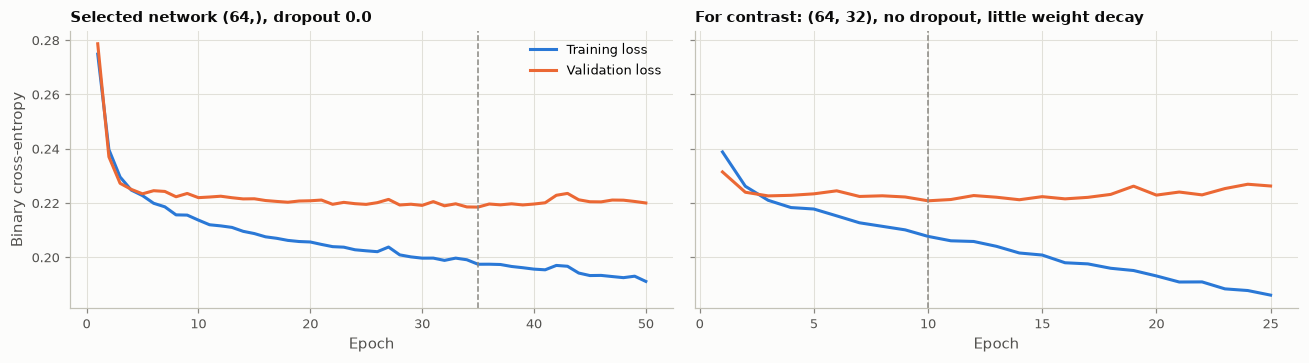

Selected network over 5 random seeds: validation PR-AUC mean 0.7159, sd 0.0062, range 0.7073-0.7244


In [54]:
t0 = time.time()
rows = []
for hidden in [(16,), (64,), (32, 16), (64, 32)]:
    for dropout in [0.0, 0.3]:
        for wd in [1e-4, 1e-2]:
            m = PodiumModel(ShallowNet(hidden=hidden, dropout=dropout, weight_decay=wd)).fit(X_train, y_train, X_val, y_val)
            score = log_trial("Shallow neural network", f"hidden={hidden}, dropout={dropout}, weight_decay={wd}, epochs={m.estimator.best_epoch}", m)
            rows.append({"hidden": str(hidden), "dropout": dropout, "weight_decay": wd, "best_epoch": m.estimator.best_epoch,
                         "train PR-AUC": TRIALS[-1]["train PR-AUC"], "val PR-AUC": score, "model": m, "h": hidden})
nn_grid = pd.DataFrame(rows)
best = nn_grid.loc[nn_grid["val PR-AUC"].idxmax()]
NN_PARAMS = {"hidden": best["h"], "dropout": float(best["dropout"]), "weight_decay": float(best["weight_decay"])}
MODELS["Shallow neural network"] = best["model"]
print(f"Selected on validation: {NN_PARAMS} -> val PR-AUC {best['val PR-AUC']:.4f}   ({time.time() - t0:.0f}s for {len(nn_grid)} networks)")
display(nn_grid.drop(columns=["model", "h"]).sort_values("val PR-AUC", ascending=False).round(4).reset_index(drop=True))

hist = pd.DataFrame(best["model"].estimator.history)
no_reg = nn_grid[(nn_grid["hidden"] == str((64, 32))) & (nn_grid["dropout"] == 0.0) & (nn_grid["weight_decay"] == 1e-4)].iloc[0]["model"]
hist_noreg = pd.DataFrame(no_reg.estimator.history)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, h, title, mark in [(axes[0], hist, f"Selected network {NN_PARAMS['hidden']}, dropout {NN_PARAMS['dropout']}", best["model"].estimator.best_epoch),
                           (axes[1], hist_noreg, "For contrast: (64, 32), no dropout, little weight decay", no_reg.estimator.best_epoch)]:
    ax.plot(h["epoch"], h["train_loss"], color=C["blue"], label="Training loss")
    ax.plot(h["epoch"], h["val_loss"], color=C["orange"], label="Validation loss")
    ax.axvline(mark, color=C["muted"], linestyle="--", linewidth=1)
    ax.set_xlabel("Epoch")
    ax.set_title(title, fontsize=9.5)
axes[0].set_ylabel("Binary cross-entropy")
axes[0].legend()
savefig("model_nn_training")

# How much does the result depend on the random seed?
seed_scores = []
for s in range(5):
    m = PodiumModel(ShallowNet(seed=s, **NN_PARAMS)).fit(X_train, y_train, X_val, y_val)
    seed_scores.append(average_precision_score(y_val, m.proba(X_val)))
NN_SEED_SD = float(np.std(seed_scores))
print(f"Selected network over 5 random seeds: validation PR-AUC mean {np.mean(seed_scores):.4f}, sd {NN_SEED_SD:.4f}, range {min(seed_scores):.4f}-{max(seed_scores):.4f}")

**Reading the curves.** The dashed line marks the epoch that early stopping kept. The right-hand panel shows the largest network with no dropout: its training loss keeps falling while the validation loss flattens and turns upward — the network starts memorising the training seasons, and it does so within a few epochs. Early stopping is what prevents this from reaching the final model; the grid above shows which combination of size, dropout and weight decay generalised best.

The spread over random seeds printed above is the yardstick for all neural-network comparisons that follow: a difference smaller than that spread is not meaningful.

Because the validation seasons are used both to stop training and to choose the architecture, the network's validation score is slightly optimistic. The test seasons, which play no part in either, give the unbiased figure (Section 11).

### 10.7 All modelling attempts

Total modelling attempts logged: 60


,attempts,worst_val,best_val,baseline_val
model,,,,
Gradient boosting,12,0.7454,0.7553,0.7247
Logistic regression,17,0.7114,0.7268,0.7247
Random forest,15,0.7130,0.7500,0.7247
Shallow neural network,16,0.7064,0.7296,0.7247


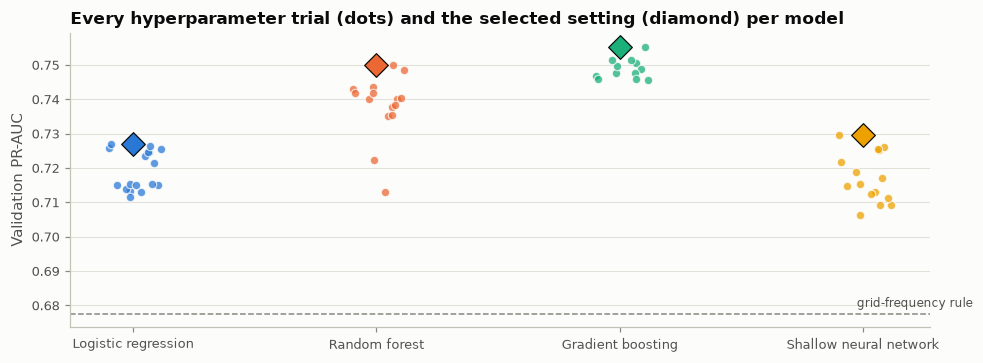

In [55]:
trials = pd.DataFrame(TRIALS)
trials["gap (train - val)"] = trials["train PR-AUC"] - trials["val PR-AUC"]
trials.to_csv(os.path.join(OUT_DIR, "all_model_trials.csv"), index=False)
summary = trials.groupby("model").agg(attempts=("params", "size"), worst_val=("val PR-AUC", "min"), best_val=("val PR-AUC", "max")).round(4)
summary["baseline_val"] = round(average_precision_score(y_val, baseline_lr.proba(X_val)), 4)
print(f"Total modelling attempts logged: {len(trials)}")
display(summary)

fig, ax = plt.subplots(figsize=(9, 3.4))
names = ["Logistic regression", "Random forest", "Gradient boosting", "Shallow neural network"]
for i, (name, color) in enumerate(zip(names, SERIES)):
    v = trials.loc[trials["model"] == name, "val PR-AUC"].values
    jitter = np.random.default_rng(SEED).uniform(-0.12, 0.12, len(v))
    ax.scatter(np.full(len(v), i) + jitter, v, color=color, s=30, alpha=0.75, edgecolor=C["surface"], linewidth=0.8)
    ax.scatter([i], [v.max()], color=color, s=120, marker="D", edgecolor=C["ink"], linewidth=0.8)
ref = average_precision_score(y_val, grid_rule.proba(X_val))
ax.axhline(ref, color=C["muted"], linestyle="--", linewidth=1)
ax.text(len(names) - 0.55, ref + 0.002, "grid-frequency rule", fontsize=8, color=C["ink2"], ha="right")
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names)
ax.set_ylabel("Validation PR-AUC")
ax.set_title("Every hyperparameter trial (dots) and the selected setting (diamond) per model")
ax.grid(axis="x", visible=False)
savefig("model_all_trials")

### 10.8 Two checks on the experimental design

**Check 1 — chronological vs. random split.** Section 7 argued for a chronological split. Here the same two models are also evaluated with a random row split of the same sizes, to see how different the reported score would have been.

**Check 2 — era sensitivity.** How much does the choice of training seasons matter? The models are re-trained on shorter, more recent windows and scored on the same validation seasons.

,chronological split (2019-2021),"random split, mean of 5","random split, sd",difference
Gradient boosting,0.7553,0.6914,0.0483,-0.0640
Logistic regression,0.7268,0.6777,0.0420,-0.0491


,model,Gradient boosting,Logistic regression
training seasons,rows,,
2003-2018,6411,0.7553,0.7268
2006-2018,5355,0.7392,0.7268
2010-2018,3877,0.7374,0.7195
2014-2018,2067,0.7292,0.7131


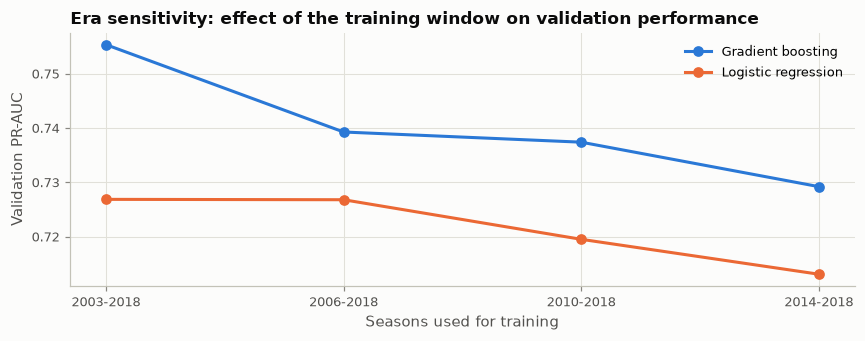

In [56]:
from sklearn.model_selection import train_test_split

dev = table[table["split"].isin(["train", "val"])]
rows = []
for rep in range(5):
    r_train, r_val = train_test_split(dev, test_size=len(val), random_state=rep, stratify=dev["podium"])
    for name, est in [("Logistic regression", LogisticRegression(max_iter=5000, **LR_PARAMS)),
                      ("Gradient boosting", HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, **GB_PARAMS))]:
        m = PodiumModel(est).fit(r_train[FEATURES], r_train["podium"].values)
        rows.append({"model": name, "repeat": rep, "PR-AUC": average_precision_score(r_val["podium"], m.proba(r_val[FEATURES]))})
random_split = pd.DataFrame(rows).groupby("model")["PR-AUC"].agg(["mean", "std"])
chrono = pd.Series({"Logistic regression": average_precision_score(y_val, MODELS["Logistic regression (tuned)"].proba(X_val)),
                    "Gradient boosting": average_precision_score(y_val, MODELS["Gradient boosting"].proba(X_val))})
split_check = pd.DataFrame({"chronological split (2019-2021)": chrono, "random split, mean of 5": random_split["mean"], "random split, sd": random_split["std"]})
split_check["difference"] = split_check["random split, mean of 5"] - split_check["chronological split (2019-2021)"]
display(split_check.round(4))

rows = []
for start in [2003, 2006, 2010, 2014]:
    sub = train[train["year"] >= start]
    for name, est in [("Logistic regression", LogisticRegression(max_iter=5000, **LR_PARAMS)),
                      ("Gradient boosting", HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, **GB_PARAMS))]:
        m = PodiumModel(est).fit(sub[FEATURES], sub["podium"].values)
        rows.append({"training seasons": f"{start}-2018", "rows": len(sub), "model": name, "val PR-AUC": average_precision_score(y_val, m.proba(X_val))})
era_check = pd.DataFrame(rows).pivot(index=["training seasons", "rows"], columns="model", values="val PR-AUC")
display(era_check.round(4))

fig, ax = plt.subplots(figsize=(8, 3.2))
for name, color in zip(era_check.columns, SERIES):
    ax.plot([i[0] for i in era_check.index], era_check[name], marker="o", color=color, label=name)
ax.set_xlabel("Seasons used for training")
ax.set_ylabel("Validation PR-AUC")
ax.set_title("Era sensitivity: effect of the training window on validation performance")
ax.legend()
savefig("model_era_sensitivity")

In [57]:
d_lr, d_gb = split_check.loc["Logistic regression", "difference"], split_check.loc["Gradient boosting", "difference"]
spread = era_check.max() - era_check.min()
md(f"""
**Check 1 — split.** With a random split the validation PR-AUC is {abs(d_lr):.3f} {'higher' if d_lr > 0 else 'lower'} for logistic regression and {abs(d_gb):.3f} {'higher' if d_gb > 0 else 'lower'} for gradient boosting than with the chronological split (random-split standard deviation about {split_check['random split, sd'].mean():.3f}). Two things differ at once, so this is not a clean measurement of leakage: a random validation set is drawn from all of 2003–2021 and is therefore a different, more mixed set of races than 2019–2021, and its score swings widely from one random draw to the next. The two schemes also do not ask the same question: a random split asks "how well does the model fill in races *between* races it has seen?", the chronological split asks "how well does it predict seasons it has *never* seen?". Only the second question matches real use, so the chronological figures are the ones reported, whichever is larger.

**Check 2 — era.** Across training windows from 2003–2018 down to 2014–2018, validation PR-AUC varies by {spread['Logistic regression']:.3f} (logistic regression) and {spread['Gradient boosting']:.3f} (gradient boosting). Dropping older seasons removes up to two thirds of the training rows; the table shows what that trade — fewer but more recent rows — does to performance. The full 2003–2018 window is kept for the final models because it uses all available data with complete qualifying coverage and the features are built to be era-robust (shares and rates instead of raw points).
""")


**Check 1 — split.** With a random split the validation PR-AUC is 0.049 lower for logistic regression and 0.064 lower for gradient boosting than with the chronological split (random-split standard deviation about 0.045). Two things differ at once, so this is not a clean measurement of leakage: a random validation set is drawn from all of 2003–2021 and is therefore a different, more mixed set of races than 2019–2021, and its score swings widely from one random draw to the next. The two schemes also do not ask the same question: a random split asks "how well does the model fill in races *between* races it has seen?", the chronological split asks "how well does it predict seasons it has *never* seen?". Only the second question matches real use, so the chronological figures are the ones reported, whichever is larger.

**Check 2 — era.** Across training windows from 2003–2018 down to 2014–2018, validation PR-AUC varies by 0.014 (logistic regression) and 0.026 (gradient boosting). Dropping older seasons removes up to two thirds of the training rows; the table shows what that trade — fewer but more recent rows — does to performance. The full 2003–2018 window is kept for the final models because it uses all available data with complete qualifying coverage and the features are built to be era-robust (shares and rates instead of raw points).


## 11. Model comparison

The selected setting of each model is now evaluated on all three sets. The decision threshold of each model is chosen on the validation seasons and applied unchanged to the test seasons. **This is the first and only time the test seasons are used.**

In [58]:
FINAL = ["Grid-frequency rule (no ML)", "Logistic regression (baseline, default)", "Logistic regression (tuned)",
         "Random forest", "Gradient boosting", "Shallow neural network"]
SETS = {"train": (X_train, y_train), "val": (X_val, y_val), "test": (X_test, y_test)}
PROBA = {name: {s: MODELS[name].proba(X) for s, (X, _) in SETS.items()} for name in FINAL}
THRESHOLD = {name: best_f1_threshold(y_val, PROBA[name]["val"]) for name in FINAL}

rows = []
for name in FINAL:
    for s, (_, y) in SETS.items():
        rows.append({"model": name, "set": s, "threshold": THRESHOLD[name], **all_metrics(y, PROBA[name][s], THRESHOLD[name])})
comparison = pd.DataFrame(rows)
comparison.to_csv(os.path.join(OUT_DIR, "model_comparison.csv"), index=False)

HEADLINE = ["ROC-AUC", "PR-AUC", "F1", "Precision", "Recall"]
def table_for(set_name):
    return comparison[comparison["set"] == set_name].set_index("model")[["threshold"] + HEADLINE + ["Brier", "Accuracy"]]

for s, title in [("train", "TRAINING seasons 2003-2018"), ("val", "VALIDATION seasons 2019-2021"), ("test", "TEST seasons 2022-2024 (unseen)")]:
    print(title)
    display(table_for(s).style.format("{:.3f}").highlight_max(subset=HEADLINE, color="#cde2fb").highlight_min(subset=["Brier"], color="#cde2fb"))

TRAINING seasons 2003-2018


,threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Brier,Accuracy
model,,,,,,,,
Grid-frequency rule (no ML),0.500,0.909,0.618,0.638,0.638,0.638,0.072,0.898
"Logistic regression (baseline, default)",0.296,0.932,0.693,0.667,0.585,0.777,0.067,0.891
Logistic regression (tuned),0.295,0.932,0.693,0.669,0.585,0.781,0.067,0.892
Random forest,0.387,0.973,0.864,0.776,0.744,0.812,0.047,0.934
Gradient boosting,0.341,0.956,0.776,0.717,0.650,0.799,0.058,0.911
Shallow neural network,0.445,0.946,0.730,0.685,0.694,0.676,0.062,0.913


VALIDATION seasons 2019-2021


,threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Brier,Accuracy
model,,,,,,,,
Grid-frequency rule (no ML),0.500,0.922,0.678,0.717,0.717,0.717,0.067,0.915
"Logistic regression (baseline, default)",0.296,0.931,0.725,0.714,0.634,0.817,0.066,0.902
Logistic regression (tuned),0.295,0.931,0.727,0.714,0.634,0.817,0.066,0.902
Random forest,0.387,0.939,0.750,0.730,0.697,0.767,0.063,0.915
Gradient boosting,0.341,0.937,0.755,0.724,0.665,0.794,0.063,0.909
Shallow neural network,0.445,0.933,0.730,0.732,0.714,0.750,0.064,0.917


TEST seasons 2022-2024 (unseen)


,threshold,ROC-AUC,PR-AUC,F1,Precision,Recall,Brier,Accuracy
model,,,,,,,,
Grid-frequency rule (no ML),0.500,0.910,0.646,0.649,0.650,0.647,0.073,0.895
"Logistic regression (baseline, default)",0.296,0.933,0.695,0.667,0.560,0.824,0.071,0.876
Logistic regression (tuned),0.295,0.932,0.693,0.665,0.556,0.828,0.072,0.875
Random forest,0.387,0.938,0.697,0.675,0.659,0.691,0.070,0.900
Gradient boosting,0.341,0.937,0.691,0.667,0.632,0.706,0.070,0.894
Shallow neural network,0.445,0.923,0.668,0.618,0.614,0.623,0.076,0.884


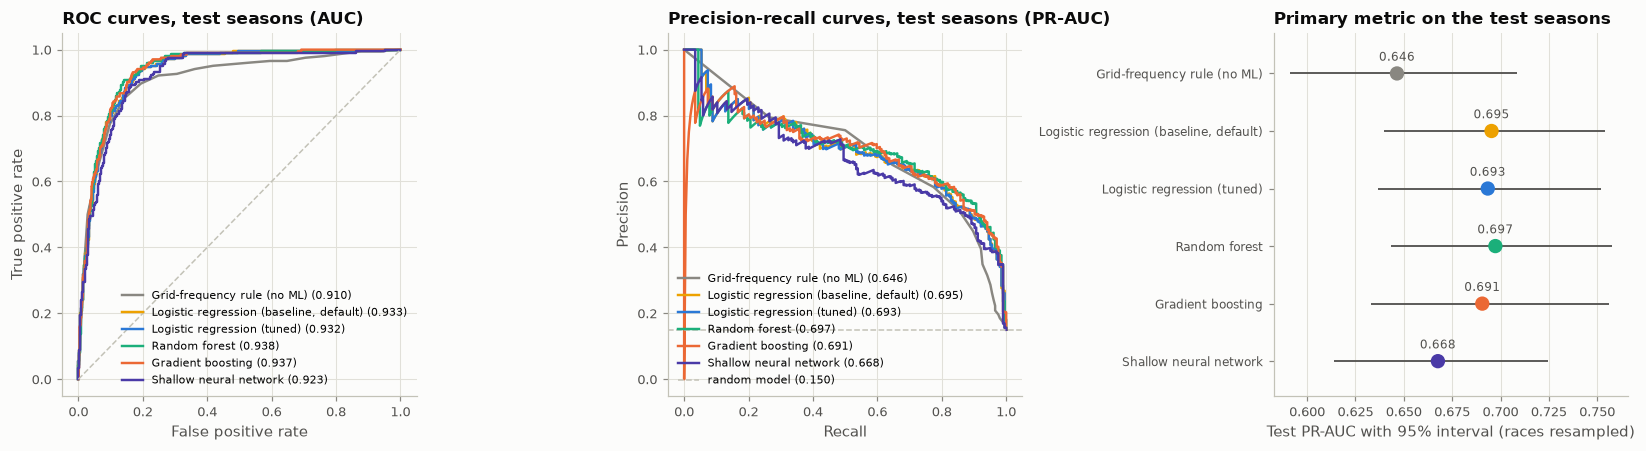

In [59]:
def race_bootstrap(y_true, p, race_ids, metric=average_precision_score, n_boot=500, seed=SEED):
    """95% interval by resampling whole races, because rows of one race are not independent."""
    rng = np.random.default_rng(seed)
    groups = pd.Series(np.arange(len(race_ids))).groupby(np.asarray(race_ids)).apply(lambda s: s.values)
    ids = groups.index.values
    stats = []
    for _ in range(n_boot):
        idx = np.concatenate([groups[r] for r in rng.choice(ids, size=len(ids), replace=True)])
        stats.append(metric(y_true[idx], p[idx]))
    return np.percentile(stats, [2.5, 97.5])

ci = {name: race_bootstrap(y_test, PROBA[name]["test"], test["raceId"].values) for name in FINAL}
COLOR_OF = dict(zip(FINAL, [C["muted"], C["yellow"], C["blue"], C["aqua"], C["orange"], C["violet"]]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
for name in FINAL:
    fpr, tpr, _ = roc_curve(y_test, PROBA[name]["test"])
    ax.plot(fpr, tpr, color=COLOR_OF[name], linewidth=1.6, label=f"{name} ({roc_auc_score(y_test, PROBA[name]['test']):.3f})")
ax.plot([0, 1], [0, 1], color=C["axis"], linestyle="--", linewidth=1)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves, test seasons (AUC)")
ax.legend(fontsize=7, loc="lower right")

ax = axes[1]
for name in FINAL:
    pr, rc, _ = precision_recall_curve(y_test, PROBA[name]["test"])
    ax.plot(rc, pr, color=COLOR_OF[name], linewidth=1.6, label=f"{name} ({average_precision_score(y_test, PROBA[name]['test']):.3f})")
ax.axhline(y_test.mean(), color=C["axis"], linestyle="--", linewidth=1, label=f"random model ({y_test.mean():.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-recall curves, test seasons (PR-AUC)")
ax.legend(fontsize=7, loc="lower left")

ax = axes[2]
y = np.arange(len(FINAL))[::-1]
test_pr = [average_precision_score(y_test, PROBA[n]["test"]) for n in FINAL]
ax.errorbar(test_pr, y, xerr=[[v - ci[n][0] for v, n in zip(test_pr, FINAL)], [ci[n][1] - v for v, n in zip(test_pr, FINAL)]],
            fmt="none", ecolor=C["ink2"], linewidth=1.2, zorder=1)
ax.scatter(test_pr, y, color=[COLOR_OF[n] for n in FINAL], s=70, zorder=2)
for yy, v in zip(y, test_pr):
    ax.text(v, yy + 0.22, f"{v:.3f}", ha="center", fontsize=8, color=C["ink2"])
ax.set_ylim(-0.6, len(FINAL) - 0.3)
ax.set_yticks(y)
ax.set_yticklabels(FINAL, fontsize=8)
ax.set_xlabel("Test PR-AUC with 95% interval (races resampled)")
ax.set_title("Primary metric on the test seasons")
ax.grid(axis="y", visible=False)
savefig("comparison_curves")

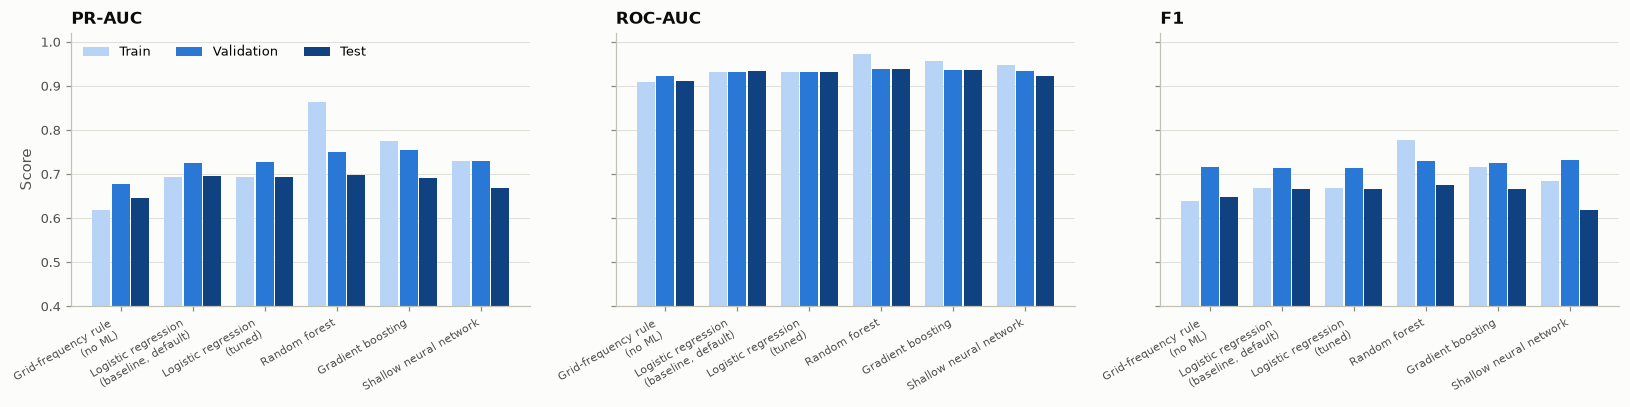

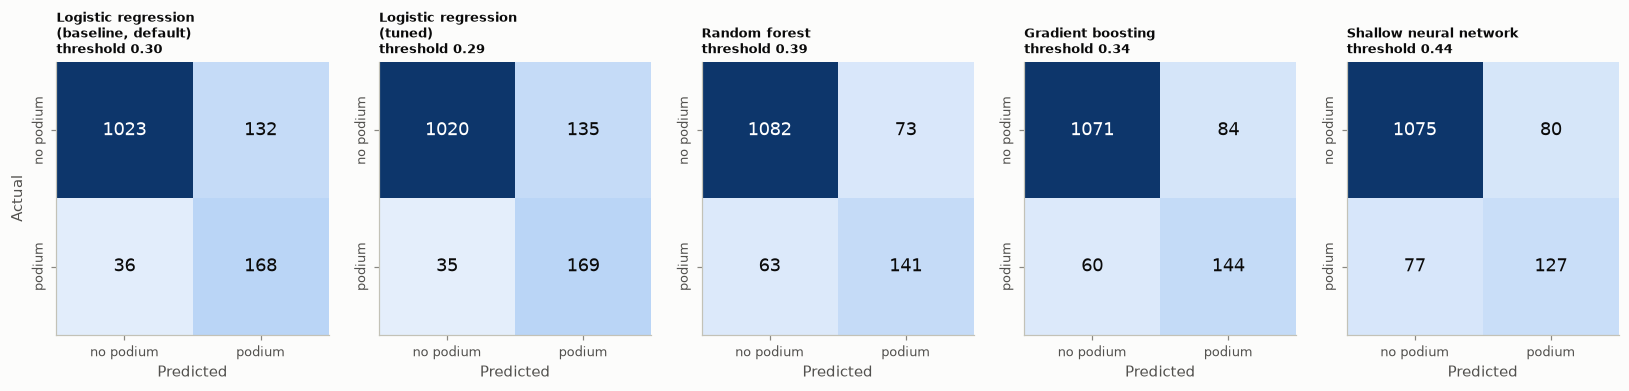

In [60]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
x = np.arange(len(FINAL))
for ax, metric in zip(axes, ["PR-AUC", "ROC-AUC", "F1"]):
    for i, (s, color, label) in enumerate([("train", C["light_blue"], "Train"), ("val", C["blue"], "Validation"), ("test", C["dark_blue"], "Test")]):
        v = comparison[comparison["set"] == s].set_index("model").loc[FINAL, metric]
        ax.bar(x + (i - 1) * 0.27, v, width=0.25, color=color, label=label)
    ax.set_xticks(x)
    ax.set_xticklabels([n.replace(" (", "\n(") for n in FINAL], fontsize=7, rotation=30, ha="right")
    ax.set_title(metric)
    ax.set_ylim(0.4, 1.02)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Score")
axes[0].legend(ncol=3, loc="upper left")
savefig("comparison_train_val_test")

learned = [n for n in FINAL if n != "Grid-frequency rule (no ML)"]
fig, axes = plt.subplots(1, len(learned), figsize=(15, 3.2))
for ax, name in zip(axes, learned):
    cm = confusion_matrix(y_test, (PROBA[name]["test"] >= THRESHOLD[name]).astype(int))
    ax.imshow(cm, cmap=BLUES, vmin=0, vmax=cm.max())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=12, color="white" if cm[i, j] > cm.max() * 0.5 else C["ink"])
    ax.set_xticks([0, 1]); ax.set_xticklabels(["no podium", "podium"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["no podium", "podium"], rotation=90, va="center")
    ax.set_xlabel("Predicted")
    ax.set_title(f"{name.replace(' (', chr(10) + '(')}\nthreshold {THRESHOLD[name]:.2f}", fontsize=8.5)
    ax.grid(False)
axes[0].set_ylabel("Actual")
savefig("comparison_confusion")

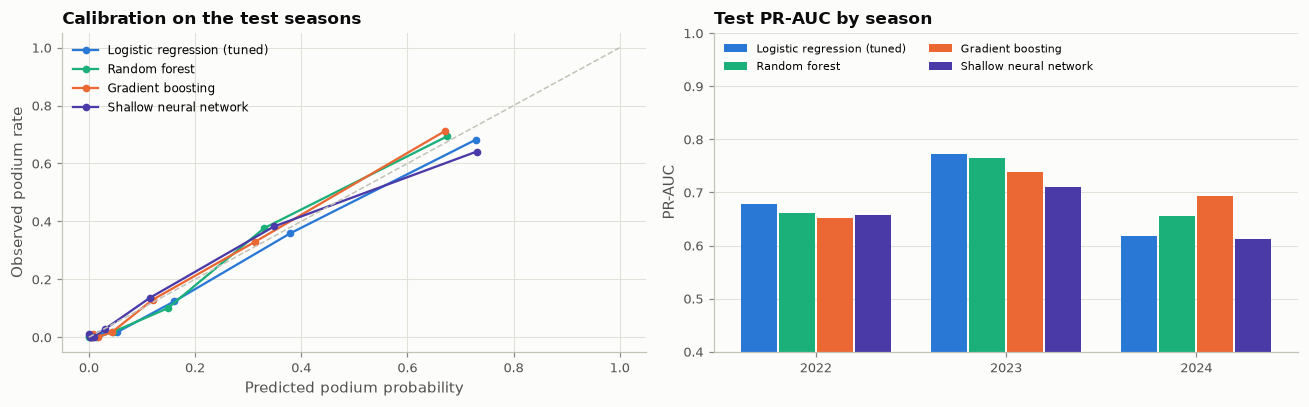

model,Logistic regression (tuned),Random forest,Gradient boosting,Shallow neural network
season,,,,
2022,0.678,0.662,0.652,0.657
2023,0.773,0.765,0.739,0.710
2024,0.618,0.657,0.693,0.612


In [61]:
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
for name in learned[1:]:
    frac, mean_pred = calibration_curve(y_test, PROBA[name]["test"], n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", markersize=4, color=COLOR_OF[name], linewidth=1.5, label=name)
ax.plot([0, 1], [0, 1], color=C["axis"], linestyle="--", linewidth=1)
ax.set_xlabel("Predicted podium probability")
ax.set_ylabel("Observed podium rate")
ax.set_title("Calibration on the test seasons")
ax.legend(fontsize=8)

ax = axes[1]
by_season = []
for name in learned[1:]:
    for yr in sorted(test["year"].unique()):
        mask = (test["year"] == yr).values
        by_season.append({"model": name, "season": yr, "PR-AUC": average_precision_score(y_test[mask], PROBA[name]["test"][mask])})
by_season = pd.DataFrame(by_season).pivot(index="season", columns="model", values="PR-AUC")[learned[1:]]
xs = np.arange(len(by_season))
for i, name in enumerate(by_season.columns):
    ax.bar(xs + (i - 1.5) * 0.2, by_season[name], width=0.19, color=COLOR_OF[name], label=name)
ax.set_xticks(xs)
ax.set_xticklabels(by_season.index)
ax.set_ylim(0.4, 1)
ax.set_ylabel("PR-AUC")
ax.set_title("Test PR-AUC by season")
ax.legend(fontsize=7.5, ncol=2, loc="upper left")
ax.grid(axis="x", visible=False)
savefig("comparison_calibration_seasons")
display(by_season.round(3))

### 11.1 A decision rule that uses the structure of a race

Every model scores each driver on its own, but a race has **exactly three** podium places. An alternative to a probability threshold is therefore: *in each race, predict the three drivers with the highest probability.* This needs no threshold at all and uses only the fact that the rows of a race belong together, which is known before the race. It is reported as an additional result, next to the threshold rule.

In [62]:
def top3_f1(p, frame, y_true):
    rank = pd.Series(p).groupby(frame["raceId"].values).rank(method="first", ascending=False)
    pred = (rank <= 3).astype(int).values
    return f1_score(y_true, pred)

rows = []
for name in FINAL:
    rows.append({"model": name,
                 "val F1 (threshold)": f1_score(y_val, (PROBA[name]["val"] >= THRESHOLD[name]).astype(int)),
                 "val F1 (top-3 per race)": top3_f1(PROBA[name]["val"], val, y_val),
                 "test F1 (threshold)": f1_score(y_test, (PROBA[name]["test"] >= THRESHOLD[name]).astype(int)),
                 "test F1 (top-3 per race)": top3_f1(PROBA[name]["test"], test, y_test)})
top3 = pd.DataFrame(rows).set_index("model")
display(top3.round(3))

,val F1 (threshold),val F1 (top-3 per race),test F1 (threshold),test F1 (top-3 per race)
model,,,,
Grid-frequency rule (no ML),0.717,0.717,0.649,0.652
"Logistic regression (baseline, default)",0.714,0.683,0.667,0.647
Logistic regression (tuned),0.714,0.689,0.665,0.642
Random forest,0.730,0.700,0.675,0.647
Gradient boosting,0.724,0.711,0.667,0.652
Shallow neural network,0.732,0.700,0.618,0.608


In [63]:
val_tab, test_tab = table_for("val"), table_for("test")
stat_models = ["Logistic regression (tuned)", "Random forest", "Gradient boosting"]
BEST_STAT = val_tab.loc[stat_models, "PR-AUC"].idxmax()
BEST_OVERALL = val_tab.loc[stat_models + ["Shallow neural network"], "PR-AUC"].idxmax()
base_name, rule_name, nn_name = "Logistic regression (baseline, default)", "Grid-frequency rule (no ML)", "Shallow neural network"
best_test = test_tab.loc[learned, "PR-AUC"].idxmax()
overlap = ci[BEST_OVERALL][0] <= test_tab.loc[base_name, "PR-AUC"] <= ci[BEST_OVERALL][1]
gap = (table_for("train")["PR-AUC"] - test_tab["PR-AUC"]).loc[learned]
top3_gain = (top3["test F1 (top-3 per race)"] - top3["test F1 (threshold)"]).loc[learned]
md(f"""
### 11.2 What the comparison shows

**Selection (validation seasons only).** Best statistical model: **{BEST_STAT}** (validation PR-AUC {val_tab.loc[BEST_STAT, 'PR-AUC']:.3f}). Best model overall: **{BEST_OVERALL}** (validation PR-AUC {val_tab.loc[BEST_OVERALL, 'PR-AUC']:.3f}). This is the model used for the inference function.

**Performance on the unseen test seasons (2022–2024).**

| Model | PR-AUC (95% interval) | ROC-AUC | F1 | Precision | Recall |
|---|---|---|---|---|---|
""" + "\n".join(f"| {n} | {test_tab.loc[n, 'PR-AUC']:.3f} ({ci[n][0]:.3f}–{ci[n][1]:.3f}) | {test_tab.loc[n, 'ROC-AUC']:.3f} | {test_tab.loc[n, 'F1']:.3f} | {test_tab.loc[n, 'Precision']:.3f} | {test_tab.loc[n, 'Recall']:.3f} |" for n in FINAL) + f"""

**Against the baselines.**

- The rule with no machine learning (grid slot only) already reaches a test PR-AUC of {test_tab.loc[rule_name, 'PR-AUC']:.3f}. Starting position explains most of what can be predicted.
- The logistic-regression baseline reaches {test_tab.loc[base_name, 'PR-AUC']:.3f}: adding qualifying, form and standings features is worth {test_tab.loc[base_name, 'PR-AUC'] - test_tab.loc[rule_name, 'PR-AUC']:+.3f} PR-AUC over the grid rule.
- The selected model, {BEST_OVERALL}, reaches {test_tab.loc[BEST_OVERALL, 'PR-AUC']:.3f}, i.e. {test_tab.loc[BEST_OVERALL, 'PR-AUC'] - test_tab.loc[base_name, 'PR-AUC']:+.3f} relative to the logistic baseline. The baseline's score lies {'inside' if overlap else 'outside'} the selected model's 95% interval, so the extra complexity {'is not clearly' if overlap else 'is'} rewarded on these 68 test races.
- The shallow neural network reaches {test_tab.loc[nn_name, 'PR-AUC']:.3f} ({test_tab.loc[nn_name, 'PR-AUC'] - test_tab.loc[base_name, 'PR-AUC']:+.3f} vs. the logistic baseline; its seed-to-seed standard deviation on validation was {NN_SEED_SD:.3f}).
- The highest test PR-AUC belongs to {best_test}. The model was **not** chosen on this number; it is reported for transparency.

**Over-fitting.** The gap between training and test PR-AUC is {', '.join(f'{gap[n]:+.3f} for {n}' for n in learned[1:])}. A large gap means the model fits the training seasons much better than it generalises.

**Decision rule.** Predicting the top three per race instead of using a threshold changes test F1 by {', '.join(f'{top3_gain[n]:+.3f} ({n})' for n in learned[1:])}.
""")


### 11.2 What the comparison shows

**Selection (validation seasons only).** Best statistical model: **Gradient boosting** (validation PR-AUC 0.755). Best model overall: **Gradient boosting** (validation PR-AUC 0.755). This is the model used for the inference function.

**Performance on the unseen test seasons (2022–2024).**

| Model | PR-AUC (95% interval) | ROC-AUC | F1 | Precision | Recall |
|---|---|---|---|---|---|
| Grid-frequency rule (no ML) | 0.646 (0.591–0.709) | 0.910 | 0.649 | 0.650 | 0.647 |
| Logistic regression (baseline, default) | 0.695 (0.640–0.754) | 0.933 | 0.667 | 0.560 | 0.824 |
| Logistic regression (tuned) | 0.693 (0.637–0.752) | 0.932 | 0.665 | 0.556 | 0.828 |
| Random forest | 0.697 (0.644–0.758) | 0.938 | 0.675 | 0.659 | 0.691 |
| Gradient boosting | 0.691 (0.633–0.756) | 0.937 | 0.667 | 0.632 | 0.706 |
| Shallow neural network | 0.668 (0.614–0.725) | 0.923 | 0.618 | 0.614 | 0.623 |

**Against the baselines.**

- The rule with no machine learning (grid slot only) already reaches a test PR-AUC of 0.646. Starting position explains most of what can be predicted.
- The logistic-regression baseline reaches 0.695: adding qualifying, form and standings features is worth +0.049 PR-AUC over the grid rule.
- The selected model, Gradient boosting, reaches 0.691, i.e. -0.005 relative to the logistic baseline. The baseline's score lies inside the selected model's 95% interval, so the extra complexity is not clearly rewarded on these 68 test races.
- The shallow neural network reaches 0.668 (-0.028 vs. the logistic baseline; its seed-to-seed standard deviation on validation was 0.006).
- The highest test PR-AUC belongs to Random forest. The model was **not** chosen on this number; it is reported for transparency.

**Over-fitting.** The gap between training and test PR-AUC is +0.000 for Logistic regression (tuned), +0.166 for Random forest, +0.085 for Gradient boosting, +0.062 for Shallow neural network. A large gap means the model fits the training seasons much better than it generalises.

**Decision rule.** Predicting the top three per race instead of using a threshold changes test F1 by -0.023 (Logistic regression (tuned)), -0.028 (Random forest), -0.015 (Gradient boosting), -0.010 (Shallow neural network).


**Interpretation.**

- **The models are close to each other, and all are far above chance.** The intervals in the right-hand panel of the curves figure overlap heavily. With 68 test races, differences of one or two hundredths in PR-AUC between the learned models should not be read as one model being truly better. What is clear is the ordering *random (≈0.15) ≪ grid rule < models with the full feature set*.
- **Why a simple model does so well.** Most of the predictable signal is in a handful of strong, nearly monotonic features (grid, qualifying gap, team form). A linear model on standardised inputs captures a monotonic effect well, so the room left for more flexible models is small. The remaining errors are mostly events no pre-race feature can see: first-lap collisions, mechanical failures, safety cars, weather and strategy.
- **Why more flexible models do not automatically win here.** The training set is small (6,411 rows, 900 positives) and the test seasons come from a new regulation era. Flexible models can fit era-specific patterns in the training seasons that do not carry over, which shows up as a larger train–test gap.
- **Validation vs. test.** Scores differ between the validation and test seasons for every model, including the grid rule that has nothing to tune. That points to the seasons themselves being more or less predictable (for example, how dominant the leading team was), not to over-fitting of the validation set. The per-season panel shows this variation directly.
- **Calibration.** The calibration panel shows whether a predicted probability can be read as a frequency. Points near the diagonal mean that "70%" really happens about 70% of the time.
- **Baseline requirement.** The baseline is logistic regression with default settings. The more complex models are justified only to the extent that they beat it on validation; where they do not, the table says so.

## 12. Experiment: feature-group ablation

Section 8 justified the feature groups **before** training. The ablation measures what each group actually contributes **after** training.

**Method.** One group is removed, every model is re-trained from scratch with its selected hyperparameters on the remaining features, and the score is compared with the full model. This is repeated for each of the six groups. The neural network is trained with three random seeds per configuration and averaged, because its seed-to-seed variation is of the same size as some of the effects being measured.

A second view, **"only this group"**, trains each model on a single group. The two views answer different questions:

- *Drop one group* → the group's **unique** contribution: what is lost that no other group can replace.
- *Only this group* → the group's **stand-alone** value.

Because the groups overlap heavily (Section 8.3), a group can be very informative on its own and still cause almost no loss when dropped.

In [64]:
def build_model(kind, cols, seed=SEED):
    if kind == "Logistic regression":
        return PodiumModel(LogisticRegression(max_iter=5000, **LR_PARAMS), cols)
    if kind == "Random forest":
        return PodiumModel(RandomForestClassifier(n_estimators=300, max_features="sqrt", n_jobs=-1, random_state=seed, **RF_PARAMS), cols)
    if kind == "Gradient boosting":
        return PodiumModel(HistGradientBoostingClassifier(early_stopping=False, random_state=seed, **GB_PARAMS), cols)
    return PodiumModel(ShallowNet(seed=seed, **NN_PARAMS), cols)

def fit_and_score(kind, cols):
    """PR-AUC, ROC-AUC and F1 (threshold from validation) on validation and test. Neural network: mean of three seeds."""
    seeds = [SEED, SEED + 1, SEED + 2] if kind == "Shallow neural network" else [SEED]
    out = []
    for s in seeds:
        m = build_model(kind, cols, s).fit(X_train, y_train, X_val, y_val)
        pv, pt = m.proba(X_val), m.proba(X_test)
        thr = best_f1_threshold(y_val, pv)
        out.append({"val PR-AUC": average_precision_score(y_val, pv), "test PR-AUC": average_precision_score(y_test, pt),
                    "val ROC-AUC": roc_auc_score(y_val, pv), "test ROC-AUC": roc_auc_score(y_test, pt),
                    "test F1": f1_score(y_test, (pt >= thr).astype(int))})
    return pd.DataFrame(out).mean().to_dict()

ABLATION_MODELS = ["Logistic regression", "Random forest", "Gradient boosting", "Shallow neural network"]
t0 = time.time()
rows = []
for kind in ABLATION_MODELS:
    rows.append({"model": kind, "setting": "full", "group": "(all features)", "n_features": len(FEATURES), **fit_and_score(kind, FEATURES)})
    for g, members in FEATURE_GROUPS.items():
        rows.append({"model": kind, "setting": "drop", "group": g, "n_features": len(FEATURES) - len(members),
                     **fit_and_score(kind, [f for f in FEATURES if f not in members])})
        rows.append({"model": kind, "setting": "only", "group": g, "n_features": len(members), **fit_and_score(kind, members)})
ablation = pd.DataFrame(rows)
ablation.to_csv(os.path.join(OUT_DIR, "ablation_results.csv"), index=False)
print(f"{len(ablation)} configurations trained in {time.time() - t0:.0f}s")

full = ablation[ablation["setting"] == "full"].set_index("model")
drop = ablation[ablation["setting"] == "drop"].copy()
for col in ["val PR-AUC", "test PR-AUC", "val ROC-AUC", "test ROC-AUC", "test F1"]:
    drop["Δ " + col] = drop[col] - drop["model"].map(full[col])

print("Full models (reference):")
display(full[["val PR-AUC", "test PR-AUC", "val ROC-AUC", "test ROC-AUC", "test F1"]].round(4))
print("Change in score when one group is REMOVED (negative = the model got worse without it):")
display(drop.pivot(index="group", columns="model", values=["Δ val PR-AUC", "Δ test PR-AUC"]).loc[list(FEATURE_GROUPS)].round(4))
print("Change in ROC-AUC and F1 on the test seasons:")
display(drop.pivot(index="group", columns="model", values=["Δ test ROC-AUC", "Δ test F1"]).loc[list(FEATURE_GROUPS)].round(4))

52 configurations trained in 32s
Full models (reference):


,val PR-AUC,test PR-AUC,val ROC-AUC,test ROC-AUC,test F1
model,,,,,
Logistic regression,0.7268,0.6934,0.9307,0.9323,0.6654
Random forest,0.7500,0.6973,0.9387,0.9378,0.6746
Gradient boosting,0.7553,0.6906,0.9368,0.9370,0.6667
Shallow neural network,0.7241,0.6682,0.9331,0.9238,0.6204


Change in score when one group is REMOVED (negative = the model got worse without it):


Δ val PR-AUC                                                              Δ test PR-AUC                                                         
model            Gradient boosting Logistic regression Random forest Shallow neural network Gradient boosting Logistic regression Random forest Shallow neural network
group                                                                                                                                                                 
grid                       -0.0289             -0.0108       -0.0383                -0.0269           -0.0194             -0.0047       -0.0197                -0.0125
qualifying                 -0.0171              0.0010       -0.0216                 0.0021            0.0147              0.0108        0.0065                 0.0099
driver_form                -0.0023             -0.0027       -0.0128                 0.0162           -0.0156              0.0069        0.0039                 0.0201
constructor_form           -0.0150             -0.0011       -0.0044                -0.0043           -0.0165              0.0028       -0.0091                 0.0094
standings                  -0.0169              0.0012       -0.0277                -0.0344            0.0050              0.0061       -0.0075                 0.0014
context                    -0.0045              0.0032       -0.0079                -0.0018           -0.0045              0.0035       -0.0059                 0.0028

Change in ROC-AUC and F1 on the test seasons:


Δ test ROC-AUC                                                                  Δ test F1                                                         
model            Gradient boosting Logistic regression Random forest Shallow neural network Gradient boosting Logistic regression Random forest Shallow neural network
group                                                                                                                                                                 
grid                       -0.0012             -0.0027       -0.0030                -0.0033            0.0058              0.0013       -0.0309                -0.0146
qualifying                  0.0015              0.0038       -0.0017                 0.0047           -0.0068             -0.0037       -0.0340                 0.0038
driver_form                -0.0046              0.0003        0.0011                 0.0073           -0.0255             -0.0101        0.0075                 0.0432
constructor_form           -0.0010              0.0007        0.0003                 0.0034           -0.0015              0.0108        0.0071                 0.0120
standings                   0.0003              0.0014       -0.0008                 0.0021            0.0133             -0.0040        0.0141                 0.0053
context                     0.0012              0.0004        0.0008                 0.0036           -0.0100              0.0054        0.0030                 0.0126

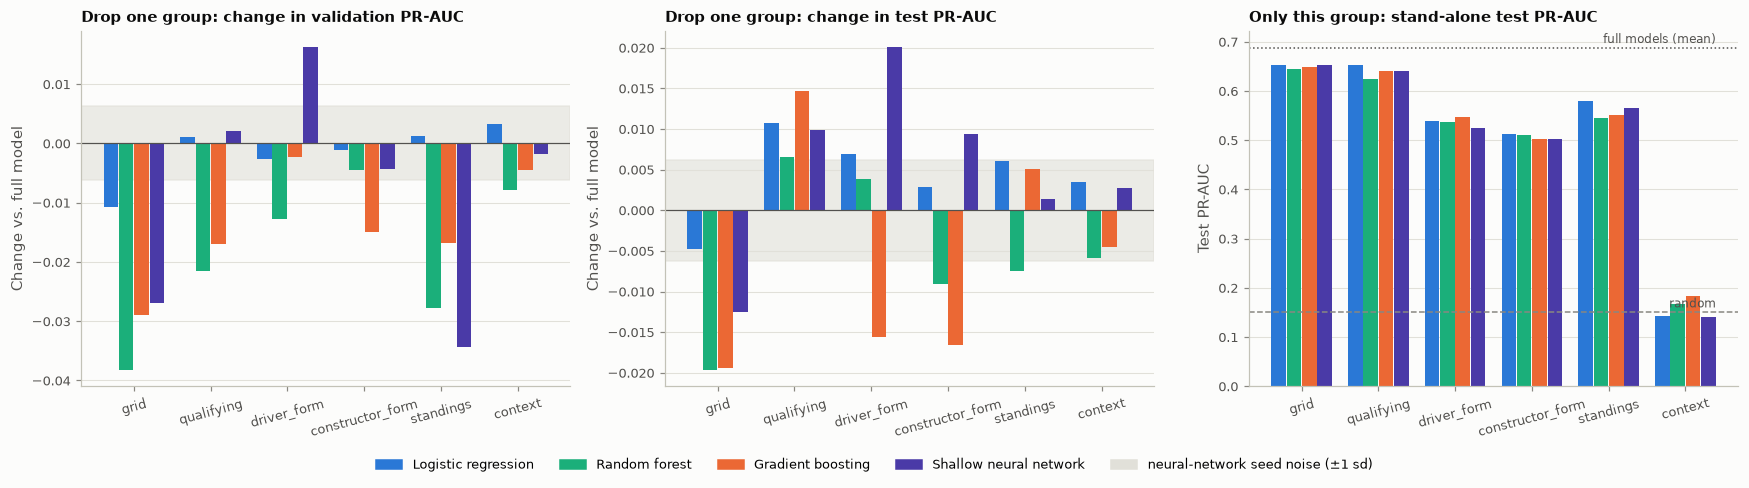

In [65]:
MODEL_COLOR = dict(zip(ABLATION_MODELS, [C["blue"], C["aqua"], C["orange"], C["violet"]]))
groups = list(FEATURE_GROUPS)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, col, title in [(axes[0], "Δ val PR-AUC", "Drop one group: change in validation PR-AUC"),
                       (axes[1], "Δ test PR-AUC", "Drop one group: change in test PR-AUC")]:
    w = drop.pivot(index="group", columns="model", values=col).loc[groups, ABLATION_MODELS]
    x = np.arange(len(groups))
    for i, name in enumerate(ABLATION_MODELS):
        ax.bar(x + (i - 1.5) * 0.2, w[name], width=0.19, color=MODEL_COLOR[name], label=name)
    ax.axhline(0, color=C["ink2"], linewidth=0.8)
    ax.axhspan(-NN_SEED_SD, NN_SEED_SD, color=C["grid"], alpha=0.6, zorder=0)
    ax.set_xticks(x)
    ax.set_xticklabels(groups, fontsize=8.5, rotation=15)
    ax.set_ylabel("Change vs. full model")
    ax.set_title(title, fontsize=10)
    ax.grid(axis="x", visible=False)

ax = axes[2]
only = ablation[ablation["setting"] == "only"].pivot(index="group", columns="model", values="test PR-AUC").loc[groups, ABLATION_MODELS]
x = np.arange(len(groups))
for i, name in enumerate(ABLATION_MODELS):
    ax.bar(x + (i - 1.5) * 0.2, only[name], width=0.19, color=MODEL_COLOR[name])
ax.axhline(y_test.mean(), color=C["muted"], linestyle="--", linewidth=1)
ax.text(len(groups) - 0.6, y_test.mean() + 0.01, "random", fontsize=8, color=C["ink2"], ha="right")
ax.axhline(full["test PR-AUC"].mean(), color=C["ink2"], linestyle=":", linewidth=1)
ax.text(len(groups) - 0.6, full["test PR-AUC"].mean() + 0.01, "full models (mean)", fontsize=8, color=C["ink2"], ha="right")
ax.set_xticks(x)
ax.set_xticklabels(groups, fontsize=8.5, rotation=15)
ax.set_ylabel("Test PR-AUC")
ax.set_title("Only this group: stand-alone test PR-AUC", fontsize=10)
ax.grid(axis="x", visible=False)
handles = [mpl.patches.Patch(color=MODEL_COLOR[n], label=n) for n in ABLATION_MODELS] + [mpl.patches.Patch(color=C["grid"], label="neural-network seed noise (±1 sd)")]
fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=8.5, bbox_to_anchor=(0.5, -0.06))
savefig("ablation_groups")

In [66]:
mean_drop = drop.groupby("group")[["Δ val PR-AUC", "Δ test PR-AUC"]].mean().loc[groups]
mean_only = only.mean(axis=1)
ranked_drop = mean_drop["Δ val PR-AUC"].sort_values()
consistent = [g for g in groups if (drop[drop["group"] == g][["Δ val PR-AUC", "Δ test PR-AUC"]] < 0).all().all()]
md(f"""
**Ablation results** (mean over the four models)

| Group | Features | Drop it: Δ val PR-AUC | Drop it: Δ test PR-AUC | Only it: test PR-AUC |
|---|---|---|---|---|
""" + "\n".join(f"| {g} | {len(FEATURE_GROUPS[g])} | {mean_drop.loc[g, 'Δ val PR-AUC']:+.4f} | {mean_drop.loc[g, 'Δ test PR-AUC']:+.4f} | {mean_only[g]:.3f} |" for g in groups) + f"""

- **Largest unique contribution:** removing **{ranked_drop.index[0]}** costs the most on validation ({ranked_drop.iloc[0]:+.4f} PR-AUC on average), followed by **{ranked_drop.index[1]}** ({ranked_drop.iloc[1]:+.4f}).
- **Strongest stand-alone group:** **{mean_only.idxmax()}** alone reaches a test PR-AUC of {mean_only.max():.3f}; the weakest alone is **{mean_only.idxmin()}** ({mean_only.min():.3f}, against {y_test.mean():.2f} for a random model).
- **Groups whose removal hurts every model on both validation and test:** {', '.join(consistent) if consistent else 'none — no single group is indispensable for all four models'}.
""")


**Ablation results** (mean over the four models)

| Group | Features | Drop it: Δ val PR-AUC | Drop it: Δ test PR-AUC | Only it: test PR-AUC |
|---|---|---|---|---|
| grid | 3 | -0.0262 | -0.0141 | 0.649 |
| qualifying | 5 | -0.0089 | +0.0105 | 0.640 |
| driver_form | 7 | -0.0004 | +0.0038 | 0.537 |
| constructor_form | 3 | -0.0062 | -0.0034 | 0.507 |
| standings | 5 | -0.0194 | +0.0013 | 0.560 |
| context | 5 | -0.0028 | -0.0010 | 0.159 |

- **Largest unique contribution:** removing **grid** costs the most on validation (-0.0262 PR-AUC on average), followed by **standings** (-0.0194).
- **Strongest stand-alone group:** **grid** alone reaches a test PR-AUC of 0.649; the weakest alone is **context** (0.159, against 0.15 for a random model).
- **Groups whose removal hurts every model on both validation and test:** grid.


**Interpretation.**

- **The groups overlap, so drop-one effects are small.** Grid, qualifying, team form and standings all measure "how fast is this car–driver combination right now". Remove one, and the others cover most of the loss. That is why the *drop-one* effects are a few hundredths of PR-AUC at most, even for groups that are strong on their own in the *only-this-group* panel. A small drop-one effect does **not** mean a group is useless; it means it is replaceable.
- **Grid is the group with the clearest unique contribution.** Its removal lowers the score for the models on both validation and test (see the computed list above), even though qualifying position is still available. The reason is the one found in Question 1: the grid differs from the qualifying order in about a quarter of entries, and when it does, the actual starting slot is what counts.
- **Qualifying, standings and form are largely interchangeable.** Removing one of them hurts on validation for the tree models but not consistently on test. Where a group's removal helps on one set and hurts on the other, the honest reading is "no measurable unique contribution", not "harmful".
- **Effects inside the grey band are noise.** Changes smaller than the neural network's seed-to-seed standard deviation cannot be distinguished from re-running the same model. The same caution applies to the other models given the size of the validation and test sets.
- **Context** is the weakest group: alone it is at the level of a random model (three of its five features are identical for every driver in a race), and its drop-one effect is close to zero. It is kept because it costs five columns and the ablation gives no consistent evidence that it hurts; it is the first candidate for removal in a leaner model.
- **Relation to the pre-training evidence.** The stand-alone ranking of the groups matches the single-feature ranking of Section 8.1 (grid and qualifying first, context last), so the exploratory evidence and the post-training measurement tell the same story.

## 13. Model explainability

> **Explanations are not causal effects.** Everything in this section describes **what the model relies on** to make its predictions. A feature being important to the model is **not** proof that it *causes* podium finishes. The features are correlated with each other and with things the model never sees (the true pace of the car, driver skill, budget). For example, a high importance for championship standing does not mean that being higher in the standings makes a car faster; standing and podiums are both consequences of having a fast car and a good driver. The plots below answer "why did the model predict this?", never "what would happen if we changed this feature in the real world?".

Two models are explained: the best statistical model and the shallow neural network. Three methods are used:

| Method | Scope | Idea |
|---|---|---|
| Permutation importance | Global | Shuffle one feature in unseen data and measure how much the score drops |
| SHAP | Global and local | Split each individual prediction into additive contributions of the features |
| LIME | Local | Fit a small linear model around one prediction to approximate the model nearby |

### 13.1 Global: permutation importance

Each feature is shuffled 20 times in the **test** seasons and the drop in PR-AUC is recorded. The test set is used because importance on unseen data shows what the model needs in order to generalise, not what it memorised. Because correlated features can stand in for each other, a single shuffled feature can look unimportant while its *group* is essential. The right-hand panel therefore shuffles all features of a group **together**.

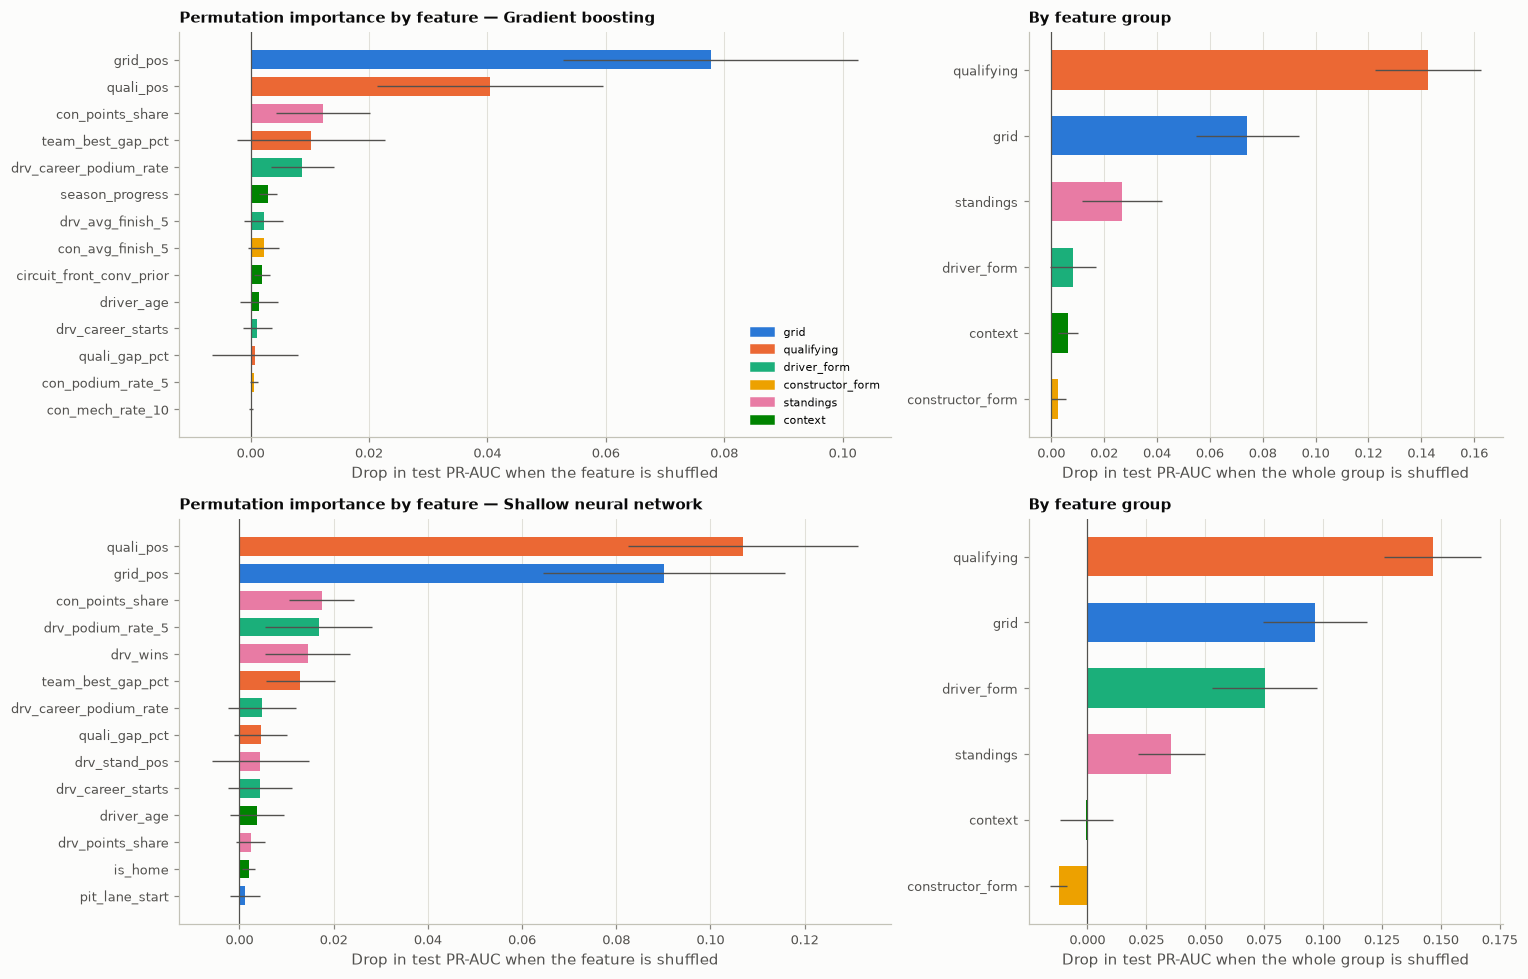


Gradient boosting - top features: grid_pos (0.078), quali_pos (0.040), con_points_share (0.012), team_best_gap_pct (0.010), drv_career_podium_rate (0.009)
Gradient boosting - groups: qualifying (0.143), grid (0.074), standings (0.027), driver_form (0.008), context (0.006), constructor_form (0.003)

Shallow neural network - top features: quali_pos (0.107), grid_pos (0.090), con_points_share (0.017), drv_podium_rate_5 (0.017), drv_wins (0.014)
Shallow neural network - groups: qualifying (0.147), grid (0.097), driver_form (0.075), standings (0.036), context (-0.000), constructor_form (-0.012)


In [67]:
from sklearn.inspection import permutation_importance

EXPLAINED = {"best statistical": MODELS[BEST_STAT], "neural network": MODELS["Shallow neural network"]}
EXPLAINED_NAME = {"best statistical": BEST_STAT, "neural network": "Shallow neural network"}
pr_scorer = lambda est, X, y: average_precision_score(y, est.predict_proba(X)[:, 1])

def grouped_permutation(model, X, y, n_repeats=20, seed=SEED):
    """Shuffle all features of a group with the same row permutation, so within-group relationships are preserved."""
    rng = np.random.default_rng(seed)
    base = average_precision_score(y, model.proba(X))
    out = {}
    for g, members in FEATURE_GROUPS.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[members] = X[members].values[rng.permutation(len(X))]
            drops.append(base - average_precision_score(y, model.proba(Xp)))
        out[g] = (np.mean(drops), np.std(drops))
    return pd.DataFrame(out, index=["mean", "std"]).T

PERM, PERM_GROUP = {}, {}
for key, model in EXPLAINED.items():
    r = permutation_importance(model, X_test, y_test, scoring=pr_scorer, n_repeats=20, random_state=SEED)
    PERM[key] = pd.DataFrame({"mean": r.importances_mean, "std": r.importances_std}, index=FEATURES).sort_values("mean", ascending=False)
    PERM_GROUP[key] = grouped_permutation(model, X_test, y_test)

fig, axes = plt.subplots(2, 2, figsize=(14, 9), gridspec_kw={"width_ratios": [1.5, 1]})
for row, key in enumerate(EXPLAINED):
    ax = axes[row, 0]
    d = PERM[key].head(14).iloc[::-1]
    ax.barh(d.index, d["mean"], xerr=d["std"], color=[GROUP_COLOR[GROUP_OF[f]] for f in d.index], height=0.7, error_kw={"ecolor": C["ink2"], "linewidth": 0.9})
    ax.axvline(0, color=C["ink2"], linewidth=0.8)
    ax.set_xlabel("Drop in test PR-AUC when the feature is shuffled")
    ax.set_title(f"Permutation importance by feature — {EXPLAINED_NAME[key]}", fontsize=10)
    ax.grid(axis="y", visible=False)
    if row == 0:
        ax.legend(handles=[mpl.patches.Patch(color=GROUP_COLOR[g], label=g) for g in FEATURE_GROUPS], loc="lower right", fontsize=7.5)
    ax = axes[row, 1]
    d = PERM_GROUP[key].sort_values("mean")
    ax.barh(d.index, d["mean"], xerr=d["std"], color=[GROUP_COLOR[g] for g in d.index], height=0.6, error_kw={"ecolor": C["ink2"], "linewidth": 0.9})
    ax.axvline(0, color=C["ink2"], linewidth=0.8)
    ax.set_xlabel("Drop in test PR-AUC when the whole group is shuffled")
    ax.set_title("By feature group", fontsize=10)
    ax.grid(axis="y", visible=False)
savefig("xai_permutation_importance")

for key in EXPLAINED:
    print(f"\n{EXPLAINED_NAME[key]} - top features:", ", ".join(f"{f} ({v:.3f})" for f, v in PERM[key]["mean"].head(5).items()))
    print(f"{EXPLAINED_NAME[key]} - groups:", ", ".join(f"{g} ({v:.3f})" for g, v in PERM_GROUP[key]["mean"].sort_values(ascending=False).items()))

### 13.2 Global: SHAP

SHAP assigns to each feature, for each individual prediction, a contribution that says how far that feature pushed the prediction above or below the model's average output. The contributions of all features add up exactly to the prediction. Averaging their absolute size over many rows gives a global importance; plotting them against the feature value shows the *direction* of the effect, which permutation importance cannot show.

- For the statistical model an exact, model-specific explainer is used (tree explainer for the tree ensembles, linear explainer for logistic regression).
- For the neural network a model-agnostic explainer is used on a sample of rows, with a sample of training rows as the reference ("background") data.

Contributions are computed on the pre-processed inputs the model actually sees; the plots show the original feature values so they can be read in real units.

SHAP values computed in 3s


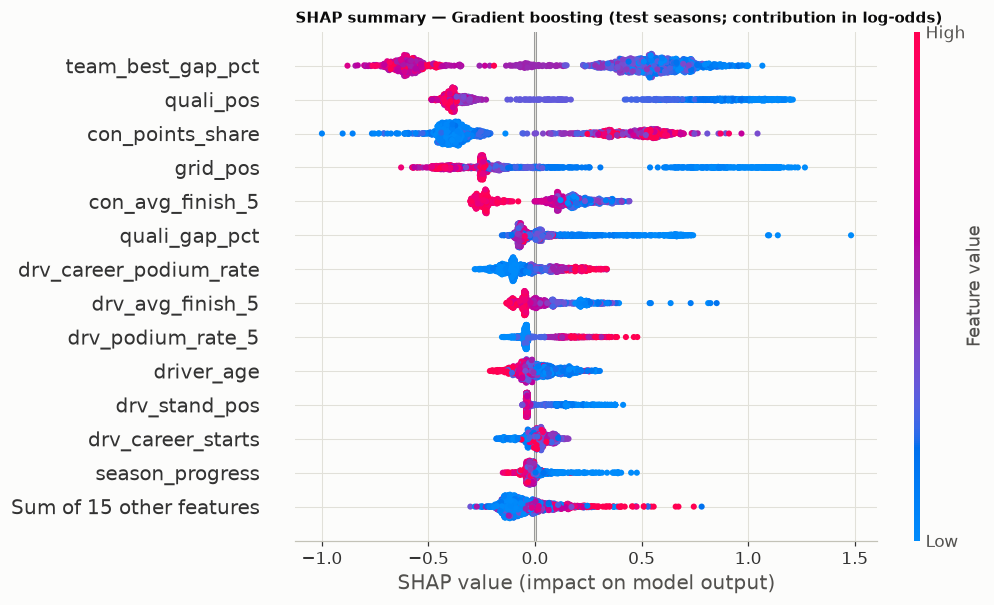

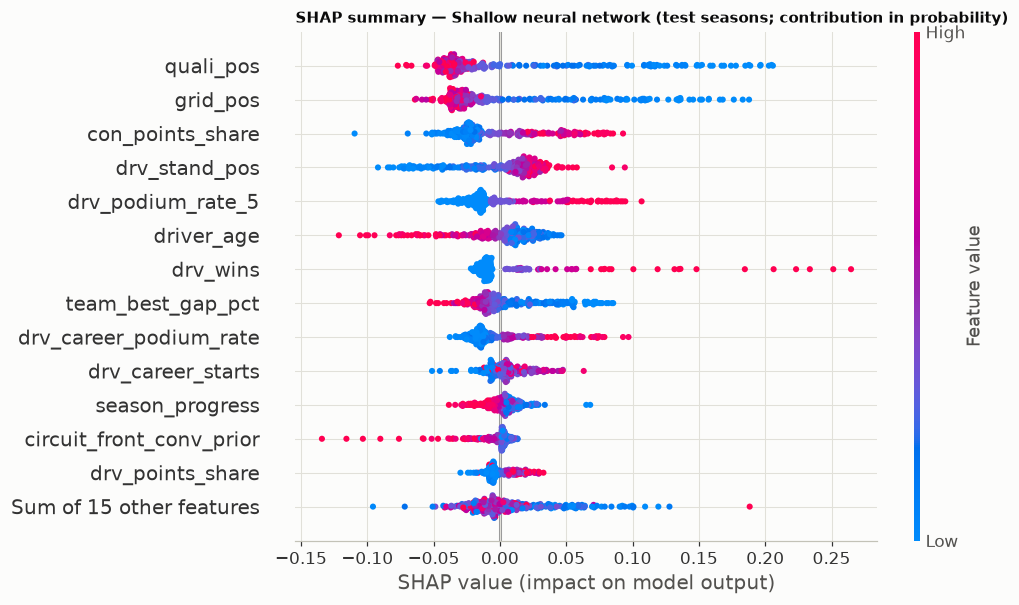

In [68]:
import shap

def shap_explain(model, X, background=None, max_rows=None, seed=SEED):
    """SHAP values for the positive class, returned with original-unit feature values for display."""
    if max_rows is not None and len(X) > max_rows:
        X = X.sample(max_rows, random_state=seed)
    Z = model.transform(X)
    est = model.estimator
    raw = pd.DataFrame(model.prep.named_steps["impute"].transform(X[model.cols]), columns=model.cols)
    if isinstance(est, LogisticRegression):
        ex = shap.LinearExplainer(est, model.transform(X_train))
        values, base, unit = ex.shap_values(Z), ex.expected_value, "log-odds"
    elif isinstance(est, (RandomForestClassifier, HistGradientBoostingClassifier)):
        ex = shap.TreeExplainer(est)
        values, base = ex.shap_values(Z, check_additivity=False), ex.expected_value
        unit = "probability" if isinstance(est, RandomForestClassifier) else "log-odds"
    else:
        bg = model.transform(X_train.sample(100, random_state=seed)) if background is None else background
        ex = shap.Explainer(lambda A: est.predict_proba(A)[:, 1], shap.maskers.Independent(bg, max_samples=100), seed=seed)
        res = ex(Z, silent=True)
        values, base, unit = res.values, res.base_values, "probability"
    values = np.asarray(values)
    if values.ndim == 3:                                       # (rows, features, classes) -> positive class
        values = values[:, :, 1]
    base = np.ravel(np.asarray(base, dtype=float))
    base = float(base[-1]) if len(base) <= 2 else base
    base_values = np.full(len(X), base) if np.isscalar(base) else base
    return shap.Explanation(values=values, base_values=base_values, data=raw.values, feature_names=model.cols), unit, X

SHAP = {}
t0 = time.time()
SHAP["best statistical"] = shap_explain(EXPLAINED["best statistical"], X_test)
SHAP["neural network"] = shap_explain(EXPLAINED["neural network"], X_test, max_rows=300)
print(f"SHAP values computed in {time.time() - t0:.0f}s")

for key in EXPLAINED:
    expl, unit, _ = SHAP[key]
    plt.figure()
    shap.plots.beeswarm(expl, max_display=14, show=False, plot_size=(9.5, 5.6))
    plt.title(f"SHAP summary — {EXPLAINED_NAME[key]} (test seasons; contribution in {unit})", fontsize=10, loc="left")
    savefig(f"xai_shap_beeswarm_{key.replace(' ', '_')}")

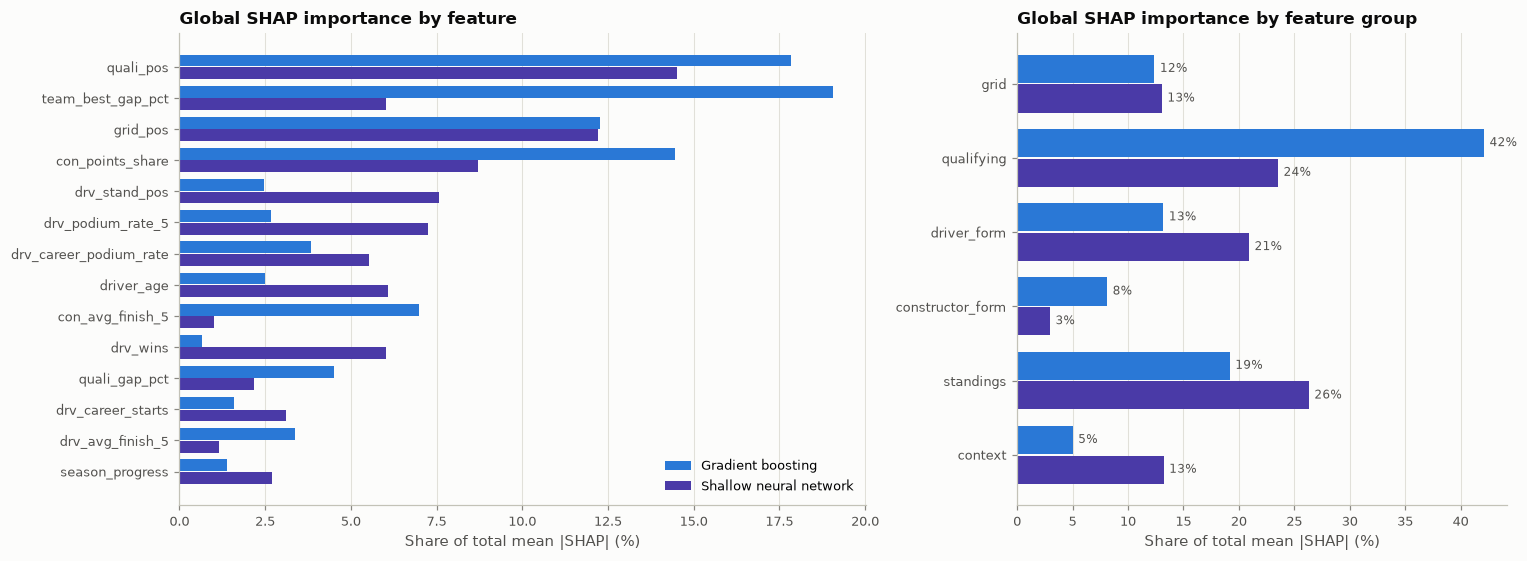

,Gradient boosting,Shallow neural network
grid,12.4,13.1
qualifying,42.1,23.5
driver_form,13.2,20.9
constructor_form,8.1,3.0
standings,19.2,26.3
context,5.0,13.2


In [69]:
def shap_share(expl):
    mean_abs = pd.Series(np.abs(expl.values).mean(axis=0), index=FEATURES)
    return mean_abs / mean_abs.sum()

share = pd.DataFrame({EXPLAINED_NAME[k]: shap_share(SHAP[k][0]) for k in EXPLAINED})
group_share = share.groupby(pd.Series(GROUP_OF)).sum().loc[list(FEATURE_GROUPS)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
top = share.mean(axis=1).sort_values(ascending=False).head(14).index[::-1]
y = np.arange(len(top))
for i, (name, color) in enumerate(zip(share.columns, [C["blue"], C["violet"]])):
    ax.barh(y + (0.2 if i == 0 else -0.2), share.loc[top, name] * 100, height=0.38, color=color, label=name)
ax.set_yticks(y)
ax.set_yticklabels(top)
ax.set_xlabel("Share of total mean |SHAP| (%)")
ax.set_title("Global SHAP importance by feature")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)

ax = axes[1]
y = np.arange(len(group_share))[::-1]
for i, (name, color) in enumerate(zip(group_share.columns, [C["blue"], C["violet"]])):
    ax.barh(y + (0.2 if i == 0 else -0.2), group_share[name] * 100, height=0.38, color=color, label=name)
    for yy, v in zip(y + (0.2 if i == 0 else -0.2), group_share[name] * 100):
        ax.text(v + 0.5, yy, f"{v:.0f}%", va="center", fontsize=8, color=C["ink2"])
ax.set_yticks(y)
ax.set_yticklabels(group_share.index)
ax.set_xlabel("Share of total mean |SHAP| (%)")
ax.set_title("Global SHAP importance by feature group")
ax.grid(axis="y", visible=False)
savefig("xai_shap_global_bar")
display((group_share * 100).round(1))

In [70]:
def top_features(series, n=5):
    return ", ".join(f"`{f}`" for f in series.sort_values(ascending=False).head(n).index)
k1, k2 = "best statistical", "neural network"
perm_top = set(PERM[k1]["mean"].head(8).index)
shap_top = set(share[EXPLAINED_NAME[k1]].sort_values(ascending=False).head(8).index)
md(f"""
**Global explanations — what the models rely on**

| | {EXPLAINED_NAME[k1]} | {EXPLAINED_NAME[k2]} |
|---|---|---|
| Top features by permutation importance | {top_features(PERM[k1]['mean'])} | {top_features(PERM[k2]['mean'])} |
| Top features by SHAP | {top_features(share[EXPLAINED_NAME[k1]])} | {top_features(share[EXPLAINED_NAME[k2]])} |
| Top group, permutation | {PERM_GROUP[k1]['mean'].idxmax()} | {PERM_GROUP[k2]['mean'].idxmax()} |
| Top group, SHAP | {group_share[EXPLAINED_NAME[k1]].idxmax()} ({group_share[EXPLAINED_NAME[k1]].max() * 100:.0f}%) | {group_share[EXPLAINED_NAME[k2]].idxmax()} ({group_share[EXPLAINED_NAME[k2]].max() * 100:.0f}%) |

For {EXPLAINED_NAME[k1]}, {len(perm_top & shap_top)} of the top 8 features are the same under permutation importance and SHAP.
""")


**Global explanations — what the models rely on**

| | Gradient boosting | Shallow neural network |
|---|---|---|
| Top features by permutation importance | `grid_pos`, `quali_pos`, `con_points_share`, `team_best_gap_pct`, `drv_career_podium_rate` | `quali_pos`, `grid_pos`, `con_points_share`, `drv_podium_rate_5`, `drv_wins` |
| Top features by SHAP | `team_best_gap_pct`, `quali_pos`, `con_points_share`, `grid_pos`, `con_avg_finish_5` | `quali_pos`, `grid_pos`, `con_points_share`, `drv_stand_pos`, `drv_podium_rate_5` |
| Top group, permutation | qualifying | qualifying |
| Top group, SHAP | qualifying (42%) | standings (26%) |

For Gradient boosting, 7 of the top 8 features are the same under permutation importance and SHAP.


**Interpretation of the global explanations.**

- **Both models lean first on where the car starts and how fast it was in qualifying**, then on how the team and driver have been doing this season (standings and recent form). This agrees with the exploratory ranking in Section 8.1 and with the ablation in Section 12, so three independent pieces of evidence point the same way.
- **Direction (SHAP summary plots).** In the summary plots each dot is one driver–race; colour is the feature value. Low values of `grid_pos` and `quali_pos` (blue) lie on the right-hand side — a start near the front pushes the prediction towards "podium" — and high values of the form and points-share features (red) also lie on the right. The model has learned the directions that the EDA showed.
- **Shape.** For the position features the positive contributions reach much further from zero than the negative ones: starting at the very front raises the prediction a lot, while starting anywhere from mid-grid backwards lowers it by a similar, moderate amount. This reflects Section 8.2 — the podium rate is almost flat near zero from mid-grid backwards.
- **Why single-feature permutation importances are small.** Shuffling one feature usually costs little because a correlated feature still carries the same information (`grid_pos` and `quali_pos` have a correlation of 0.97). The group-level panels are the more trustworthy summary: shuffling a whole group removes that information completely.
- **Two methods, slightly different answers.** Permutation importance measures the loss in *ranking quality* when a feature is destroyed; SHAP measures how much a feature *moves the predictions*. A feature can move many predictions a little without changing the ranking much. Where the two disagree on the order of similar features, neither is "wrong"; the importance is being shared among near-duplicates.
- **Context features contribute little to ranking quality** (group permutation importance near zero), in line with the ablation, even where their SHAP share is not negligible: they move predictions slightly without improving the ranking.
- **Not causal.** These plots show reliance, not cause. "Grid position is the most important feature" means the model uses it most. It does not mean that moving a slow car to pole would give it the podium rate of a pole-sitter: cars are on pole *because* they are fast, and the model cannot separate the two.

### 13.3 Local: explaining single predictions

Two individual predictions from the test seasons are explained, chosen by fixed rules so the choice is not cherry-picked:

- **Case A — a confident, correct podium prediction:** the test row with the highest predicted probability that was a podium.
- **Case B — a podium the model did not expect:** the real podium finish with the *lowest* predicted probability. This shows what the model cannot see.

Each case is explained with a **SHAP waterfall** plot and with **LIME**, for the best statistical model.

,year,round,circuit,driver,constructor,grid,positionOrder,probability
case,,,,,,,,
A: confident and correct,2022,11,Red Bull Ring,Max Verstappen,Red Bull,1,2,0.892
B: unexpected podium,2024,21,Autódromo José Carlos Pace,Pierre Gasly,Alpine F1 Team,13,3,0.007


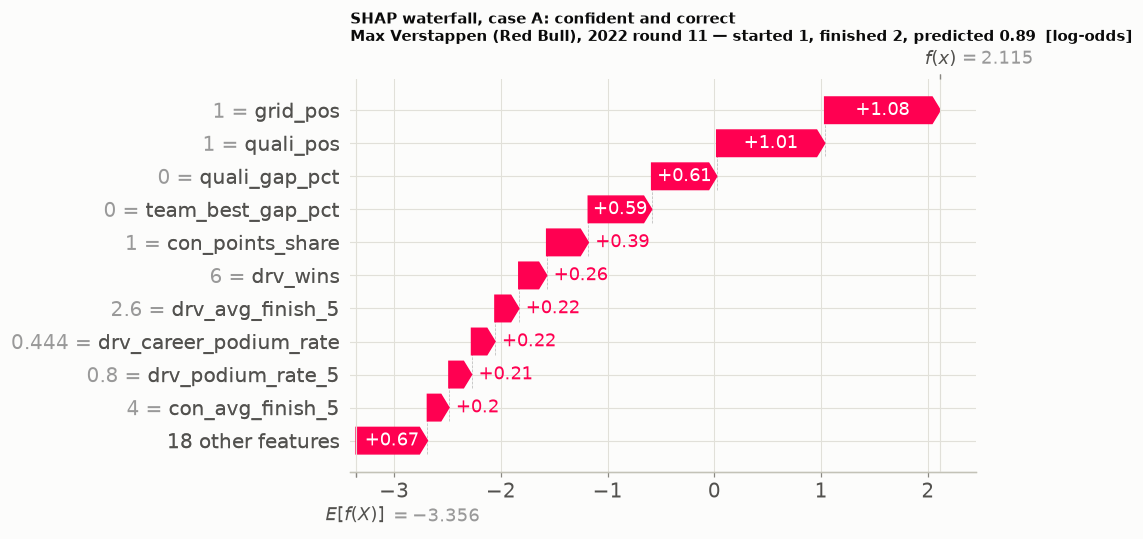

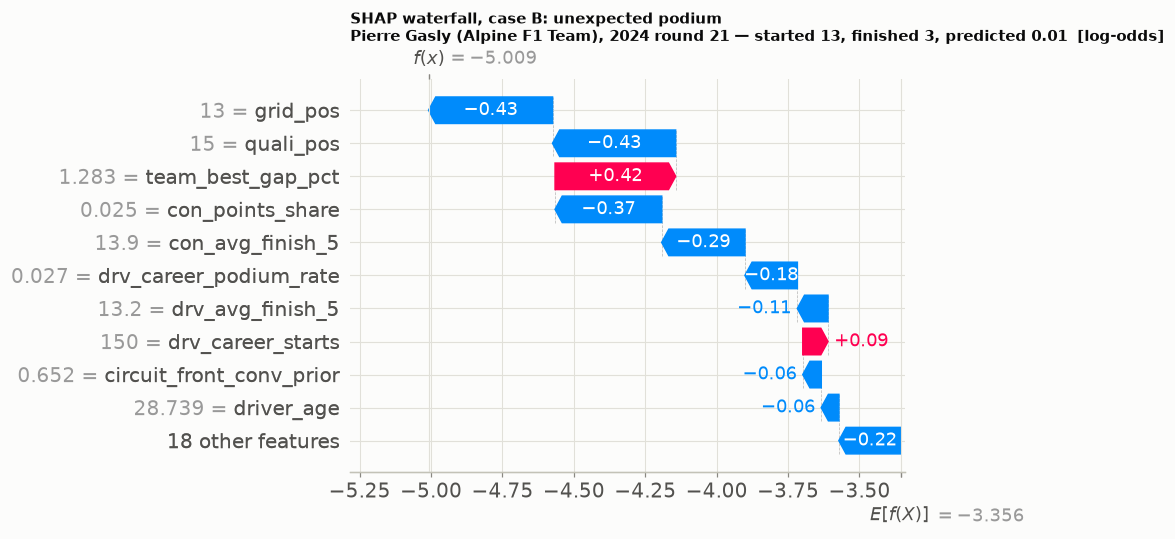

In [71]:
model_local = EXPLAINED["best statistical"]
p_test = model_local.proba(X_test)
info = test[["raceId", "driverId", "year", "round", "podium"]].merge(
    fact[["raceId", "driverId", "driver", "constructor", "circuit", "grid", "positionOrder"]], on=["raceId", "driverId"], how="left")
info["probability"] = p_test
podium_rows = info[info["podium"] == 1]
CASES = {"A: confident and correct": int(podium_rows["probability"].idxmax()), "B: unexpected podium": int(podium_rows["probability"].idxmin())}
display(info.loc[list(CASES.values()), ["year", "round", "circuit", "driver", "constructor", "grid", "positionOrder", "probability"]]
        .assign(case=list(CASES)).set_index("case").round(3))

expl_all, unit, _ = SHAP["best statistical"]
for label, idx in CASES.items():
    row = info.loc[idx]
    plt.figure()
    shap.plots.waterfall(expl_all[idx], max_display=11, show=False)
    plt.gcf().set_size_inches(9.5, 5)
    plt.title(f"SHAP waterfall, case {label}\n{row['driver']} ({row['constructor']}), {int(row['year'])} round {int(row['round'])} — "
              f"started {int(row['grid'])}, finished {int(row['positionOrder'])}, predicted {row['probability']:.2f}  [{unit}]", fontsize=9.5, loc="left")
    savefig(f"xai_local_shap_case_{label[0]}")

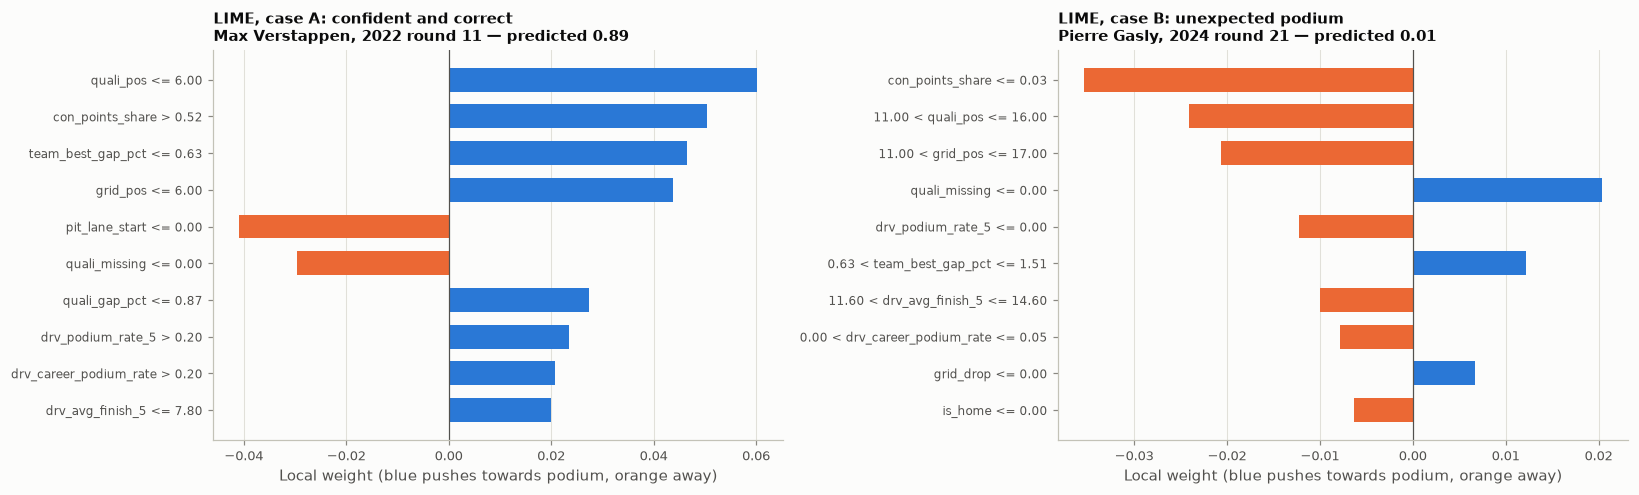

,SHAP top 5,LIME top 5,shared,shared with same direction
case,,,,
A: confident and correct,"grid_pos, quali_pos, quali_gap_pct, team_best_gap_pct, con_points_share","quali_pos, con_points_share, team_best_gap_pct, grid_pos, pit_lane_start",4,4
B: unexpected podium,"grid_pos, quali_pos, team_best_gap_pct, con_points_share, con_avg_finish_5","con_points_share, quali_pos, grid_pos, quali_missing, drv_podium_rate_5",3,3


In [72]:
from lime.lime_tabular import LimeTabularExplainer

imputer = model_local.prep.named_steps["impute"]
train_filled = imputer.transform(X_train)                       # LIME needs complete rows; values stay in original units
lime_explainer = LimeTabularExplainer(train_filled, feature_names=FEATURES, class_names=["no podium", "podium"],
                                      discretize_continuous=True, mode="classification", random_state=SEED)
predict_fn = lambda A: model_local.predict_proba(pd.DataFrame(A, columns=FEATURES))

LIME = {}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for ax, (label, idx) in zip(axes, CASES.items()):
    x = imputer.transform(X_test.iloc[[idx]])[0]
    exp = lime_explainer.explain_instance(x, predict_fn, num_features=10, num_samples=5000)
    LIME[label] = exp
    items = exp.as_list()[::-1]
    ax.barh([t for t, _ in items], [w for _, w in items], color=[C["blue"] if w > 0 else C["orange"] for _, w in items], height=0.65)
    ax.axvline(0, color=C["ink2"], linewidth=0.8)
    row = info.loc[idx]
    ax.set_title(f"LIME, case {label}\n{row['driver']}, {int(row['year'])} round {int(row['round'])} — predicted {row['probability']:.2f}", fontsize=9.5)
    ax.set_xlabel("Local weight (blue pushes towards podium, orange away)")
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", visible=False)
savefig("xai_local_lime")

rows = []
for label, idx in CASES.items():
    shap_rank = pd.Series(expl_all[idx].values, index=FEATURES)
    shap_top = list(shap_rank.abs().sort_values(ascending=False).head(5).index)
    lime_map = dict(LIME[label].as_map()[1])
    lime_top = [FEATURES[i] for i, _ in sorted(lime_map.items(), key=lambda kv: -abs(kv[1]))[:5]]
    same_sign = [f for f in set(shap_top) & set(lime_top) if np.sign(shap_rank[f]) == np.sign(lime_map[FEATURES.index(f)])]
    rows.append({"case": label, "SHAP top 5": ", ".join(shap_top), "LIME top 5": ", ".join(lime_top),
                 "shared": len(set(shap_top) & set(lime_top)), "shared with same direction": len(same_sign)})
local_agreement = pd.DataFrame(rows).set_index("case")
display(local_agreement.style.set_properties(**{"text-align": "left"}))

In [73]:
a, b = info.loc[CASES["A: confident and correct"]], info.loc[CASES["B: unexpected podium"]]
def drivers_of(idx, sign, n=3):
    s = pd.Series(expl_all[idx].values, index=FEATURES)
    s = s[s * sign > 0].abs().sort_values(ascending=False).head(n)
    raw = pd.Series(expl_all[idx].data, index=FEATURES)
    return ", ".join(f"`{f}` = {raw[f]:.2f}" for f in s.index) if len(s) else "none"
md(f"""
**Reading the two cases** (model: {BEST_STAT})

**Case A — {a['driver']} ({a['constructor']}), {int(a['year'])} round {int(a['round'])}, {a['circuit']}.** Started {int(a['grid'])}, finished {int(a['positionOrder'])}; predicted podium probability **{a['probability']:.2f}**. The features that pushed the prediction up the most were {drivers_of(CASES['A: confident and correct'], +1)}. The strong signals all point the same way, which is why the model is so confident.

**Case B — {b['driver']} ({b['constructor']}), {int(b['year'])} round {int(b['round'])}, {b['circuit']}.** Started {int(b['grid'])}, finished {int(b['positionOrder'])}; predicted podium probability **{b['probability']:.2f}**. The features that pushed the prediction *down* the most were {drivers_of(CASES['B: unexpected podium'], -1)}. On pre-race information this entry looked like a clear non-podium, and the model said so. The podium came from what happened *during* the race, which no pre-race feature can contain. This is not a defect of this model in particular; it marks the limit of what can be predicted at the cutoff.

**SHAP vs. LIME.** The two methods share {local_agreement['shared'].iloc[0]} of their top five features in case A and {local_agreement['shared'].iloc[1]} in case B. They are not expected to match exactly: SHAP distributes the exact difference between this prediction and the average prediction, while LIME fits an approximate linear model on random points around the row and reports rule-like conditions (for example `grid_pos <= 6`). Agreement on the main features in both methods is a sign the explanation is robust; features that appear in only one method should be treated with caution. In particular, LIME can give weight to flags that are constant for almost every row (such as `pit_lane_start <= 0`); this is a side effect of how it samples around the row, not a real driver of the prediction.
""")


**Reading the two cases** (model: Gradient boosting)

**Case A — Max Verstappen (Red Bull), 2022 round 11, Red Bull Ring.** Started 1, finished 2; predicted podium probability **0.89**. The features that pushed the prediction up the most were `grid_pos` = 1.00, `quali_pos` = 1.00, `quali_gap_pct` = 0.00. The strong signals all point the same way, which is why the model is so confident.

**Case B — Pierre Gasly (Alpine F1 Team), 2024 round 21, Autódromo José Carlos Pace.** Started 13, finished 3; predicted podium probability **0.01**. The features that pushed the prediction *down* the most were `grid_pos` = 13.00, `quali_pos` = 15.00, `con_points_share` = 0.02. On pre-race information this entry looked like a clear non-podium, and the model said so. The podium came from what happened *during* the race, which no pre-race feature can contain. This is not a defect of this model in particular; it marks the limit of what can be predicted at the cutoff.

**SHAP vs. LIME.** The two methods share 4 of their top five features in case A and 3 in case B. They are not expected to match exactly: SHAP distributes the exact difference between this prediction and the average prediction, while LIME fits an approximate linear model on random points around the row and reports rule-like conditions (for example `grid_pos <= 6`). Agreement on the main features in both methods is a sign the explanation is robust; features that appear in only one method should be treated with caution. In particular, LIME can give weight to flags that are constant for almost every row (such as `pit_lane_start <= 0`); this is a side effect of how it samples around the row, not a real driver of the prediction.


**Reminder.** The local explanations say which inputs led *the model* to its output for that row. They do not say why the driver did or did not finish on the podium, and they do not say what would have happened had an input been different.

## 14. Inference function

`predict_podium` takes the pre-race feature values of one driver in one race and returns the podium probability and decision from the selected model.

- **Input:** a dictionary of feature names and values. Any feature may be left out or set to `None`.
- **Missing values:** filled by the model's own pipeline with the medians learned from the training seasons, exactly as during training. The output lists which features were filled, so the caller knows how much the prediction rests on defaults.
- **Validation:** unknown feature names raise an error, so a typing mistake cannot silently turn into a missing value.
- **Decision:** the threshold chosen on the validation seasons.

In [74]:
FINAL_MODEL_NAME = BEST_OVERALL
FINAL_MODEL = MODELS[FINAL_MODEL_NAME]
FINAL_THRESHOLD = THRESHOLD[FINAL_MODEL_NAME]

def predict_podium(record, model=FINAL_MODEL, threshold=FINAL_THRESHOLD):
    """Predict whether a driver finishes on the podium from pre-race features.

    record : dict mapping feature name -> value. Features may be omitted or None (they are imputed).
    Returns a dict with the probability, the yes/no decision and the list of imputed features.
    """
    unknown = sorted(set(record) - set(FEATURES))
    if unknown:
        raise ValueError(f"Unknown feature(s): {unknown}. Valid features: {FEATURES}")
    row = pd.DataFrame([{f: record.get(f, np.nan) for f in FEATURES}]).apply(pd.to_numeric, errors="coerce")
    imputed = [f for f in FEATURES if pd.isna(row.at[0, f])]
    probability = float(model.proba(row)[0])
    return {"podium_probability": round(probability, 4),
            "prediction": "podium" if probability >= threshold else "no podium",
            "threshold": round(float(threshold), 4),
            "model": FINAL_MODEL_NAME,
            "features_provided": len(FEATURES) - len(imputed),
            "features_imputed": imputed}

def record_for(race_id, driver_id):
    """Pre-race feature record of a real entry in the modeling table."""
    row = table[(table["raceId"] == race_id) & (table["driverId"] == driver_id)].iloc[0]
    return {f: (None if pd.isna(row[f]) else float(row[f])) for f in FEATURES}

print(f"Inference model: {FINAL_MODEL_NAME}, decision threshold {FINAL_THRESHOLD:.3f}")

Inference model: Gradient boosting, decision threshold 0.341


### 14.1 Demonstration on a complete record

A real entry from the last race in the data is used: the driver who started from pole position.

In [75]:
last_race = int(test.sort_values("date")["raceId"].iloc[-1])
entry = fact[(fact["raceId"] == last_race) & (fact["grid"] == 1)].iloc[0]
complete = record_for(last_race, int(entry["driverId"]))
assert all(v is not None for v in complete.values()), "demo record is expected to be complete"
print(f"Entry: {entry['driver']} ({entry['constructor']}), {int(entry['year'])} {entry['circuit']} — started {int(entry['grid'])}, finished {int(entry['positionOrder'])}\n")
print("Input record:")
display(pd.Series(complete, name="value").round(3).to_frame().T)
result_complete = predict_podium(complete)
print("\nOutput:")
for k, v in result_complete.items():
    print(f"  {k}: {v}")

Entry: Lando Norris (McLaren), 2024 Yas Marina Circuit — started 1, finished 1

Input record:


,grid_pos,pit_lane_start,grid_drop,quali_pos,quali_gap_pct,mate_quali_gap_pct,team_best_gap_pct,quali_missing,drv_podium_rate_5,drv_avg_finish_5,drv_dnf_rate_10,drv_career_podium_rate,drv_career_starts,drv_circuit_podium_rate,drv_circuit_starts,con_podium_rate_5,con_avg_finish_5,con_mech_rate_10,drv_stand_pos,drv_points_share,drv_wins,con_stand_pos,con_points_share,is_home,season_progress,field_size,driver_age,circuit_front_conv_prior
value,1.0,0.0,0.0,1.0,0.0,-0.252,0.0,0.0,0.2,5.6,0.0,0.197,127.0,0.0,5.0,0.2,5.9,0.0,2.0,0.814,3.0,1.0,1.0,0.0,1.0,20.0,25.07,0.75



Output:
  podium_probability: 0.7519
  prediction: podium
  threshold: 0.3405
  model: Gradient boosting
  features_provided: 28
  features_imputed: []


### 14.2 Demonstration on a partially-missing record

The same entry, but now assume the qualifying lap times were not delivered and nothing is known about the driver's history at this circuit: five features are removed. Grid position, standings and recent form are still provided.

Output:
  podium_probability: 0.7371
  prediction: podium
  threshold: 0.3405
  model: Gradient boosting
  features_provided: 22
  features_imputed: ['quali_gap_pct', 'mate_quali_gap_pct', 'team_best_gap_pct', 'drv_dnf_rate_10', 'drv_circuit_podium_rate', 'con_mech_rate_10']

With only grid_pos provided: probability 0.0363, prediction 'no podium', 27 features imputed

Unknown feature name -> Unknown feature(s): ['grid_position']. Valid features: ['gri ...


,features provided,probability,prediction
record,,,
complete,28,0.7519,podium
partially missing,22,0.7371,podium
grid position only,1,0.0363,no podium


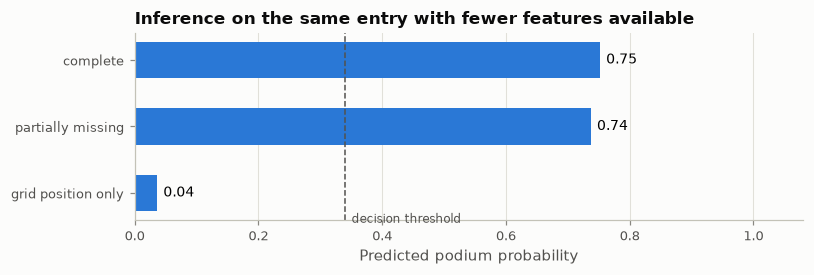

In [76]:
dropped = ["quali_gap_pct", "mate_quali_gap_pct", "team_best_gap_pct", "drv_circuit_podium_rate", "con_mech_rate_10"]
partial = {k: v for k, v in complete.items() if k not in dropped}
partial["drv_dnf_rate_10"] = None                          # an explicit None is treated the same as a missing key
result_partial = predict_podium(partial)
print("Output:")
for k, v in result_partial.items():
    print(f"  {k}: {v}")

minimal = predict_podium({"grid_pos": complete["grid_pos"]})
print(f"\nWith only grid_pos provided: probability {minimal['podium_probability']}, prediction '{minimal['prediction']}', {len(minimal['features_imputed'])} features imputed")

try:
    predict_podium({"grid_position": 1})
except ValueError as err:
    print("\nUnknown feature name ->", str(err)[:60], "...")

demo = pd.DataFrame([
    {"record": "complete", "features provided": result_complete["features_provided"], "probability": result_complete["podium_probability"], "prediction": result_complete["prediction"]},
    {"record": "partially missing", "features provided": result_partial["features_provided"], "probability": result_partial["podium_probability"], "prediction": result_partial["prediction"]},
    {"record": "grid position only", "features provided": minimal["features_provided"], "probability": minimal["podium_probability"], "prediction": minimal["prediction"]},
]).set_index("record")
display(demo)

fig, ax = plt.subplots(figsize=(7.5, 2.6))
ax.barh(demo.index[::-1], demo["probability"][::-1], color=C["blue"], height=0.55)
ax.axvline(FINAL_THRESHOLD, color=C["ink2"], linestyle="--", linewidth=1)
ax.text(FINAL_THRESHOLD + 0.01, -0.45, "decision threshold", fontsize=8, color=C["ink2"])
for y, v in enumerate(demo["probability"][::-1]):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=9)
ax.set_xlim(0, 1.08)
ax.set_xlabel("Predicted podium probability")
ax.set_title("Inference on the same entry with fewer features available")
ax.grid(axis="y", visible=False)
savefig("inference_demo")

**What the demonstration shows.** The function returns a prediction for a complete record, for a record with several missing features, and even for a record with a single feature. As features are removed, the missing ones are replaced by the training median — the value of a *typical mid-field entry* — so the prediction is pulled towards an average car. The output reports which features were imputed; a prediction with many imputed features should be trusted less. An unknown feature name is rejected instead of being ignored.

## 15. Limitations and summary

### 15.1 Known limitations

**Data**

- **Qualifying coverage drift.** The `qualifying` table is empty before 1994 and patchy until 2002, so the model is built on, and valid for, 2003 onward only. Within 2003–2024 the qualifying *format* also changed (single-lap runs in 2003–2005, knockout sessions from 2006), so "gap to pole" does not mean exactly the same thing in every season.
- **Sprint weekends.** On sprint weekends in 2021–2022 the grid was set by the sprint, not by qualifying. `grid_pos` is still correct (it is the real starting slot) but `grid_drop` then mixes penalties with sprint results. Sprint results themselves are excluded because their position relative to qualifying changed between seasons.
- **Team identity.** Form and standings follow `constructorId`. When a team is renamed it receives a new id and its history restarts, although it is the same organisation.
- **Shared drives.** The rule for collapsing duplicate driver–race rows uses the outcome to choose the row. It affects only 85 pairs before 1979 and no row of the modeling table.
- **Status classification.** "Mechanical retirement" is built from free-text status labels and involves judgment for borderline labels; the sensitivity check in Question 3 shows how much this matters.
- **No information on weather, tyres, strategy, practice pace or upgrades**, all of which influence results and some of which are known before the race.

**Modeling**

- **Era sensitivity.** Regulations, points systems, field size and reliability all change over time. The test seasons belong to a new regulation era, and performance varies noticeably from season to season. A model trained through 2018 is being applied six seasons later; in real use it would be re-trained every season.
- **Small sample.** There are 900 podiums in training and about 200 in each of validation and test. Differences of one or two hundredths between models are within noise, as the bootstrap intervals show.
- **Rows are scored independently.** The models do not know that exactly three drivers per race are positive. The top-three-per-race rule (Section 11.1) uses this at decision time only.
- **Irreducible uncertainty.** First-lap incidents, failures, safety cars and rain cannot be seen in pre-race data. Case B in Section 13.3 is an example.
- **Validation reuse.** The validation seasons are used to choose hyperparameters, thresholds and the stopping epoch of the network, so validation scores are slightly optimistic. The test seasons are used once, at the end.
- **No re-fit on train + validation.** The final models are trained on 2003–2018 only. Re-fitting on 2003–2021 before predicting 2022–2024 would probably help, but would leave no data for early stopping, so it was not done.

**Explainability**

- **Explanations are not causal.** Importance means the model relies on a feature, not that the feature causes podiums.
- **Correlated features** share importance between them, so the ranking of similar features is unstable; group-level results are the reliable ones.

### 15.2 Verification that the raw files were not modified

In [77]:
unchanged = {t: file_hash(os.path.join(DATA_DIR, t + ".csv")) == RAW_HASH[t] for t in TABLES}
in_memory = all(RAW[t].equals(pd.read_csv(os.path.join(DATA_DIR, t + ".csv"), dtype=str, keep_default_na=False)) for t in TABLES)
print(f"Raw CSV files unchanged on disk: {sum(unchanged.values())} of {len(TABLES)}")
print(f"In-memory RAW frames still identical to the files: {in_memory}")
assert all(unchanged.values()) and in_memory

Raw CSV files unchanged on disk: 14 of 14
In-memory RAW frames still identical to the files: True


In [78]:
import sklearn, scipy
print("Saved figures:", len(os.listdir(FIG_DIR)), "| saved tables:", sorted(os.listdir(OUT_DIR)))
print("Versions:", {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__,
                    "torch": torch.__version__, "shap": shap.__version__})

summary = {
    "modeling_rows": int(len(table)), "features": len(FEATURES), "split": SPLIT,
    "selected_model": FINAL_MODEL_NAME, "best_statistical_model": BEST_STAT, "threshold": float(FINAL_THRESHOLD),
    "hyperparameters": {"logistic_regression": LR_PARAMS, "random_forest": RF_PARAMS, "gradient_boosting": GB_PARAMS,
                        "neural_network": {k: (list(v) if isinstance(v, tuple) else v) for k, v in NN_PARAMS.items()}},
    "test_metrics": {n: {k: round(float(v), 4) for k, v in table_for("test").loc[n].items()} for n in FINAL},
}
with open(os.path.join(OUT_DIR, "run_summary.json"), "w") as fh:
    json.dump(summary, fh, indent=2, default=str)

Saved figures: 44 | saved tables: ['ablation_results.csv', 'all_model_trials.csv', 'model_comparison.csv', 'modeling_table.csv', 'preprocessing_order_experiments.csv', 'run_summary.json']
Versions: {'python': '3.14.0', 'pandas': '3.0.6', 'numpy': '2.5.3', 'scikit-learn': '1.9.1', 'torch': '2.14.1', 'shap': '0.52.0'}


In [79]:
t = table_for("test")
md(f"""
### 15.3 Summary

- **Data.** 14 raw tables audited: all primary and foreign keys are sound; about 160,000 hidden missing values (`\\\\N` and empty strings) were converted; dates and durations were typed; 91 surplus shared-drive rows were collapsed so that `(raceId, driverId)` is unique.
- **Data-engineering answers.** (1) Front-row starts convert to podiums about 60% of the time over all seasons and more often in the hybrid era, and the circuit ranking is not stable across eras. (2) There is no home-race advantage once starting position is held fixed. (3) Mechanical retirements fell from the 2014–2021 era to 2022–2024, and the least reliable constructors differ between the two.
- **Modeling table.** {len(table):,} driver–race rows (2003–2024), {len(FEATURES)} pre-race features in six groups, verified leakage-safe by a scramble-the-future test.
- **Models.** Selected on validation PR-AUC: **{FINAL_MODEL_NAME}**. On the unseen 2022–2024 seasons it reaches PR-AUC **{t.loc[FINAL_MODEL_NAME, 'PR-AUC']:.3f}**, ROC-AUC **{t.loc[FINAL_MODEL_NAME, 'ROC-AUC']:.3f}** and F1 **{t.loc[FINAL_MODEL_NAME, 'F1']:.3f}**, against PR-AUC {t.loc['Logistic regression (baseline, default)', 'PR-AUC']:.3f} for the logistic baseline, {t.loc['Grid-frequency rule (no ML)', 'PR-AUC']:.3f} for the grid rule and about {y_test.mean():.2f} for a random model.
- **Main finding.** Starting position and qualifying pace carry most of the predictable signal; team and driver form add a modest further gain; and the learned models are statistically hard to tell apart on 68 test races. What remains unpredicted is mostly what happens during the race.
""")


### 15.3 Summary

- **Data.** 14 raw tables audited: all primary and foreign keys are sound; about 160,000 hidden missing values (`\\N` and empty strings) were converted; dates and durations were typed; 91 surplus shared-drive rows were collapsed so that `(raceId, driverId)` is unique.
- **Data-engineering answers.** (1) Front-row starts convert to podiums about 60% of the time over all seasons and more often in the hybrid era, and the circuit ranking is not stable across eras. (2) There is no home-race advantage once starting position is held fixed. (3) Mechanical retirements fell from the 2014–2021 era to 2022–2024, and the least reliable constructors differ between the two.
- **Modeling table.** 8,970 driver–race rows (2003–2024), 28 pre-race features in six groups, verified leakage-safe by a scramble-the-future test.
- **Models.** Selected on validation PR-AUC: **Gradient boosting**. On the unseen 2022–2024 seasons it reaches PR-AUC **0.691**, ROC-AUC **0.937** and F1 **0.667**, against PR-AUC 0.695 for the logistic baseline, 0.646 for the grid rule and about 0.15 for a random model.
- **Main finding.** Starting position and qualifying pace carry most of the predictable signal; team and driver form add a modest further gain; and the learned models are statistically hard to tell apart on 68 test races. What remains unpredicted is mostly what happens during the race.
